In [2]:
# ================================================================
# CRDL COMPONENT 3
# C3-10 | RUNTIME STATE RECOVERY
#
# Restore previously completed experiment locations.
# NO previous stages rerun.
# NO training.
# NO existing files modified.
# ================================================================

from pathlib import Path
from google.colab import drive
import csv
import json

# ------------------------------------------------
# 1. Ensure Google Drive is mounted
# ------------------------------------------------

if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')

# ------------------------------------------------
# 2. Restore research project roots
# ------------------------------------------------

ROOT = Path('/content/drive/MyDrive')

RAW = ROOT / 'manushi_research_data'

PROJECT = (
    ROOT /
    'crdl_experiments' /
    'component3_fresh_v1'
)

DATA = (
    RAW /
    'pothrgbd' /
    'PData-main'
)

# ------------------------------------------------
# 3. Restore exact C3-09 experiment folder
# ------------------------------------------------

OUT = (
    PROJECT /
    '07_evaluation' /
    'C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662'
)

# ------------------------------------------------
# 4. Restore successful Section 3B
# ------------------------------------------------

SEC3 = (
    OUT /
    'section3b_pothrgbd_pairing_fix_20261021T033026Z_6cf763'
)

# ------------------------------------------------
# 5. Restore successful Section 4A
# ------------------------------------------------

SAVE4 = (
    OUT /
    'section4a_road_signal_qa_20261021T033852Z_e8af43'
)

# ------------------------------------------------
# 6. Restore successful Section 4B
# ------------------------------------------------

C4B = (
    OUT /
    'section4b_scale_group_evidence_20261021T034651Z_aade1b'
)

# ------------------------------------------------
# 7. Verify existing saved folders
# ------------------------------------------------

required_folders = {
    'PROJECT': PROJECT,
    'DATA': DATA,
    'OUT': OUT,
    'SEC3': SEC3,
    'SAVE4': SAVE4,
    'C4B': C4B
}

for name, path in required_folders.items():

    assert path.is_dir(), (
        f'Missing previous folder: {name}\n{path}'
    )

    print(f'[PASS] {name}')

# ------------------------------------------------
# 8. Verify required saved manifests
# ------------------------------------------------

pairing_file = (
    SEC3 /
    'pairing_manifest_all_depths.csv'
)

temporal_file = (
    C4B /
    'temporal_groups_PROXIES_NOT_SPLITS.csv'
)

assert pairing_file.is_file()
assert temporal_file.is_file()

with pairing_file.open(
    newline='',
    encoding='utf-8'
) as f:

    pairing_rows = list(csv.DictReader(f))

with temporal_file.open(
    newline='',
    encoding='utf-8'
) as f:

    temporal_rows = list(csv.DictReader(f))

# ------------------------------------------------
# 9. Validate recovered sample population
# ------------------------------------------------

valid_pairs = [

    row for row in pairing_rows

    if (
        row['pair_status'] == 'UNIQUE_NAME_MATCH'
        and row['label_exists'].lower() == 'true'
    )
]

assert len(valid_pairs) == 996, (
    f'Expected 996 pairs, found {len(valid_pairs)}'
)

pair_ids = {
    row['sample_id']
    for row in valid_pairs
}

temporal_ids = {
    row['sample_id']
    for row in temporal_rows
}

assert len(temporal_ids) == len(temporal_rows), (
    'Duplicate sample IDs in temporal manifest.'
)

assert pair_ids == temporal_ids, (
    'Pairing and temporal manifests disagree.'
)

burst_count = len({

    row['half_hour_burst_proxy']
    for row in temporal_rows
})

assert burst_count == 5

# ------------------------------------------------
# 10. Final recovery confirmation
# ------------------------------------------------

print("\n" + "=" * 70)
print("CRDL COMPONENT 3 — RUNTIME STATE RECOVERY")
print("=" * 70)

print("Previous C3-09 results restored: YES")

print("Matched labeled triplets:", len(valid_pairs))

print("Provisional temporal groups:", burst_count)

print("Previous training/checkpoints modified: NO")

print("New training performed: NO")

print("\nC3-10 SECTION 1 IS READY TO RUN")

print("=" * 70)

Mounted at /content/drive
[PASS] PROJECT
[PASS] DATA
[PASS] OUT
[PASS] SEC3
[PASS] SAVE4
[PASS] C4B

CRDL COMPONENT 3 — RUNTIME STATE RECOVERY
Previous C3-09 results restored: YES
Matched labeled triplets: 996
Provisional temporal groups: 5
Previous training/checkpoints modified: NO
New training performed: NO

C3-10 SECTION 1 IS READY TO RUN


In [3]:
# ================================================================
# CRDL COMPONENT 3 — C3-10 SECTION 1
# LEAKAGE-AWARE SCENE CURATION BEFORE ML TRAINING
#
# READ-ONLY SOURCE | CPU | NO TRAINING
# NO PHYSICAL-UNIT CLAIMS
# ================================================================

from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
from PIL import Image, ImageDraw, ImageOps

import csv
import json
import hashlib
import uuid
import numpy as np


# ================================================================
# 1. VERIFY PREVIOUS COLAB STATE
# ================================================================

required = (
    'OUT',
    'SEC3',
    'C4B',
    'DATA'
)

assert all(
    k in globals()
    for k in required
), (
    'Run C3-09 Sections 3B and 4B '
    'in the same Colab runtime.'
)

OUT, SEC3, C4B, DATA = map(
    Path,
    (OUT, SEC3, C4B, DATA)
)

assert all(
    p.is_dir()
    for p in (OUT, SEC3, C4B, DATA)
)


# ================================================================
# 2. CREATE NEW VERSIONED OUTPUT FOLDER
# ================================================================

SPLIT_AUDIT = OUT / (

    'C3-10_section01_scene_curation_'

    + datetime.now(
        timezone.utc
    ).strftime('%Y%m%dT%H%M%SZ_')

    + uuid.uuid4().hex[:6]
)

SPLIT_AUDIT.mkdir(
    parents=True,
    exist_ok=False
)


# ================================================================
# 3. REUSABLE FILE HELPERS
# ================================================================

def read_csv(path):

    assert path.is_file(), (
        f'Missing prerequisite: {path}'
    )

    with path.open(
        newline='',
        encoding='utf-8'
    ) as f:

        return list(
            csv.DictReader(f)
        )


def save_csv(path, rows, columns):

    with path.open(
        'w',
        newline='',
        encoding='utf-8'
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=columns
        )

        writer.writeheader()
        writer.writerows(rows)


def save_json(path, data):

    path.write_text(

        json.dumps(
            data,
            indent=2,
            default=str
        ),

        encoding='utf-8'
    )


def sha256_file(path):

    h = hashlib.sha256()

    with path.open('rb') as f:

        for buf in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):

            h.update(buf)

    return h.hexdigest()


# ================================================================
# 4. LOAD VERIFIED RGB–DEPTH–LABEL PAIRS
# ================================================================

pair_rows = read_csv(

    SEC3 /
    'pairing_manifest_all_depths.csv'
)

burst_rows = read_csv(

    C4B /
    'temporal_groups_PROXIES_NOT_SPLITS.csv'
)

paired = [

    r for r in pair_rows

    if (

        r['pair_status']
        == 'UNIQUE_NAME_MATCH'

        and r['label_exists'].lower()
        == 'true'
    )
]

assert len(paired) == 996, (

    'Expected 996 previously verified '
    'name matches. Found: '

    + str(len(paired))
)

by_id = {

    r['sample_id']: r

    for r in paired
}

assert len(by_id) == len(paired), (
    'Duplicate supposedly unique IDs'
)

by_burst = {

    r['sample_id']: r

    for r in burst_rows
}

assert set(by_id) == set(by_burst), (
    'Pairing and temporal-group manifests disagree'
)


# ================================================================
# 5. IMAGE FINGERPRINTING
# ================================================================

# Difference hash (dHash):
#
# Produces a 64-bit perceptual fingerprint
# based on relative neighboring pixel brightness.
#
# Similarity is evidence for manual review.
# It does not prove the same physical pothole.

def dhash64(image_path):

    with Image.open(image_path) as im:

        small = ImageOps.grayscale(
            im
        ).resize(

            (9, 8),

            Image.Resampling.LANCZOS
        )

        pixels = np.asarray(

            small,

            dtype=np.int16
        )

    bits = (

        pixels[:, 1:]
        > pixels[:, :-1]

    ).reshape(-1)

    value = 0

    for bit in bits:

        value = (

            (value << 1)

            | int(bit)
        )

    return value


# ================================================================
# 6. BUILD TRAINING-CANDIDATE MANIFEST
# ================================================================

records = []

for sample_id in sorted(by_id):

    row = by_id[sample_id]

    temporal = by_burst[sample_id]

    names = [

        row['rgb_filename'],

        row['depth_filename'],

        row['label_filename']
    ]

    # Do not accept arbitrary file paths from CSV.

    assert all(

        n

        and Path(n).name == n

        and '/' not in n

        and '\\' not in n

        for n in names
    )

    rgb = (
        DATA / 'images' / names[0]
    )

    depth = (
        DATA / 'depths' / names[1]
    )

    label = (
        DATA / 'labels' / names[2]
    )

    assert all(

        p.is_file()

        and not p.is_symlink()

        for p in (rgb, depth, label)
    )

    record = {

        'sample_id':
            sample_id,

        'capture_day_proxy':
            temporal['capture_date_proxy'],

        'temporal_burst_proxy':
            temporal['half_hour_burst_proxy'],

        'rgb_path':
            str(rgb),

        'depth_path':
            str(depth),

        'label_path':
            str(label),

        'rgb_bytes':
            rgb.stat().st_size,

        'depth_bytes':
            depth.stat().st_size,

        'label_bytes':
            label.stat().st_size,

        'rgb_dhash64':
            f'{dhash64(rgb):016x}',

        'scene_independence':
            'NOT_VERIFIED',

        'geometry_units':
            'RAW_SENSOR_ONLY',

        'role':
            'UNASSIGNED_DO_NOT_TRAIN_YET'
    }

    records.append(record)


# ================================================================
# 7. DETECT POSSIBLE CROSS-BURST DUPLICATES
# ================================================================

# Hamming distance counts differences
# between two 64-bit image fingerprints.
#
# We use a conservative small threshold
# to flag strong similarity.
#
# Do not automatically merge or delete images.

CROSS_BURST_HASH_THRESHOLD = 4

near = []

near_total = 0

for i in range(len(records)):

    a = records[i]

    hash_a = int(
        a['rgb_dhash64'],
        16
    )

    for j in range(
        i + 1,
        len(records)
    ):

        b = records[j]

        if (

            a['temporal_burst_proxy']

            == b['temporal_burst_proxy']
        ):

            continue

        hash_b = int(
            b['rgb_dhash64'],
            16
        )

        distance = (

            hash_a ^ hash_b

        ).bit_count()

        if distance <= CROSS_BURST_HASH_THRESHOLD:

            near_total += 1

            if len(near) < 1000:

                near.append({

                    'sample_a':
                        a['sample_id'],

                    'sample_b':
                        b['sample_id'],

                    'burst_a':
                        a['temporal_burst_proxy'],

                    'burst_b':
                        b['temporal_burst_proxy'],

                    'dhash_hamming':
                        distance,

                    'interpretation':
                        'SUSPECT_ONLY_NOT_PROOF'
                })


# ================================================================
# 8. GROUP BY PROVISIONAL CAPTURE BURST
# ================================================================

by_group = defaultdict(list)

for row in records:

    by_group[

        row['temporal_burst_proxy']

    ].append(row)


# ================================================================
# 9. GENERATE VISUAL SCENE CONTACT SHEETS
# ================================================================

group_summary = []

for burst, items in sorted(
    by_group.items()
):

    items = sorted(

        items,

        key=lambda x: x['sample_id']
    )

    capture_days = sorted(
        set(

            x['capture_day_proxy']

            for x in items
        )
    )

    # Select representative images
    # across the entire temporal group.

    indices = np.unique(

        np.linspace(

            0,
            len(items) - 1,

            num=min(
                12,
                len(items)
            ),

            dtype=int
        )
    )

    picks = [

        items[int(i)]

        for i in indices
    ]

    thumb_w = 220
    thumb_h = 170

    cols = 4

    rows = (

        len(picks)
        + cols - 1

    ) // cols

    canvas = Image.new(

        'RGB',

        (
            cols * thumb_w,
            rows * (thumb_h + 35)
        ),

        (245, 245, 245)
    )

    draw = ImageDraw.Draw(
        canvas
    )

    for k, rec in enumerate(picks):

        with Image.open(
            rec['rgb_path']
        ) as image:

            thumb = ImageOps.pad(

                image.convert('RGB'),

                (thumb_w, thumb_h),

                color=(225, 225, 225)
            )

        x = (
            k % cols
        ) * thumb_w

        y = (
            k // cols
        ) * (thumb_h + 35)

        canvas.paste(
            thumb,
            (x, y)
        )

        draw.text(

            (x + 4, y + thumb_h + 5),

            rec['sample_id'],

            fill=(0, 0, 0)
        )

    filename = (

        f'burst_{burst}_contact_sheet.jpg'
    )

    canvas.save(

        SPLIT_AUDIT / filename,

        quality=88
    )

    group_summary.append({

        'burst':
            burst,

        'n_pairs':
            len(items),

        'capture_dates':
            ';'.join(capture_days),

        'first_sample':
            items[0]['sample_id'],

        'last_sample':
            items[-1]['sample_id'],

        'contact_sheet':
            filename,

        'independent_physical_defects':
            'UNVERIFIED',

        'approved_for_test':
            'NO'
    })


# ================================================================
# 10. SAVE COMPLETE SCENE-CURATION FILES
# ================================================================

save_csv(

    SPLIT_AUDIT /
    'candidate_scene_manifest_NOT_SPLIT.csv',

    records,

    list(records[0])
)

save_csv(

    SPLIT_AUDIT /
    'temporal_group_review.csv',

    group_summary,

    list(group_summary[0])
)

save_csv(

    SPLIT_AUDIT /
    'cross_burst_near_duplicate_candidates.csv',

    near,

    [

        'sample_a',
        'sample_b',

        'burst_a',
        'burst_b',

        'dhash_hamming',
        'interpretation'
    ]
)


# ================================================================
# 11. CREATE MANUAL SCENE-REVIEW TEMPLATE
# ================================================================

manual_review = [

    {

        'burst':
            g['burst'],

        'n_pairs':
            g['n_pairs'],

        'physical_site_or_defect_id':
            '',

        'are_multiple_defects_visible':
            'UNKNOWN',

        'could_overlap_another_burst':
            'UNKNOWN',

        'evidence_notes':
            '',

        'review_status':
            'NEEDS_MANUAL_REVIEW'
    }

    for g in group_summary
]

save_csv(

    SPLIT_AUDIT /
    'manual_scene_review_TEMPLATE.csv',

    manual_review,

    list(manual_review[0])
)


# ================================================================
# 12. SAVE RESEARCH DECISION
# ================================================================

summary = {

    'stage':
        'C3-10_SECTION01_SCENE_CURRATION',

    'candidate_triplets':
        len(records),

    'capture_days':
        len(set(

            r['capture_day_proxy']

            for r in records
        )),

    'temporal_bursts':
        len(by_group),

    'cross_burst_near_hash_pairs_total':
        near_total,

    'cross_burst_hash_pairs_reported':
        len(near),

    'hash_threshold_hamming':
        CROSS_BURST_HASH_THRESHOLD,

    'physical_scene_independence_verified':
        False,

    'final_train_val_test_split_created':
        False,

    'source_depth_scale_verified':
        False,

    'source_RGB_depth_registration_verified':
        False,

    'model_trained':
        False,

    'next':

        'Review five contact sheets and '
        'cross-burst similarity candidates. '
        'Then lock grouped development splits '
        'and generate RAW-UNIT training targets.'
}

save_json(

    SPLIT_AUDIT /
    'scene_curation_decision.json',

    summary
)


# ================================================================
# 13. GENERATE ARTIFACT CHECKSUMS
# ================================================================

receipts = []

for p in sorted(
    SPLIT_AUDIT.iterdir()
):

    if (

        p.is_file()

        and p.name
        != 'sha256_manifest.json'
    ):

        receipts.append({

            'name':
                p.name,

            'size':
                p.stat().st_size,

            'sha256':
                sha256_file(p)
        })

save_json(

    SPLIT_AUDIT /
    'sha256_manifest.json',

    receipts
)


# ================================================================
# 14. PRINT RESULTS
# ================================================================

print("\n" + "=" * 72)

print(
    "C3-10 SECTION 1 — LEAKAGE-AWARE SCENE CURATION"
)

print("=" * 72)

print(
    "Verified name-matched triplets:",
    len(records)
)

print(
    "Capture days:",
    summary['capture_days']
)

print(
    "Provisional temporal bursts:",
    summary['temporal_bursts']
)

print(
    "Cross-burst hash-similarity candidates:",
    near_total
)

print(
    "WARNING: Hash similarity is not confirmed identity"
)

print("\nGROUP REVIEW:")

for row in group_summary:

    print(

        " ",

        row['burst'],

        "| pairs=",
        row['n_pairs'],

        "| day(s)=",
        row['capture_dates']
    )

print(
    "\nSPLITS LOCKED: NO — "
    "needs physical-defect/scene review"
)

print(
    "METRIC MEASUREMENTS VERIFIED: NO"
)

print(
    "NEW MODEL TRAINED: NO"
)

print(
    "\nOUTPUT:",
    SPLIT_AUDIT
)

print("=" * 72)


C3-10 SECTION 1 — LEAKAGE-AWARE SCENE CURATION
Verified name-matched triplets: 996
Capture days: 2
Provisional temporal bursts: 5
Cross-burst hash-similarity candidates: 0

GROUP REVIEW:
  POTHRGBD_TEMPORAL_0000 | pairs= 13 | day(s)= 2025-02-27
  POTHRGBD_TEMPORAL_0001 | pairs= 219 | day(s)= 2025-02-27
  POTHRGBD_TEMPORAL_0002 | pairs= 275 | day(s)= 2025-03-05
  POTHRGBD_TEMPORAL_0003 | pairs= 41 | day(s)= 2025-03-05
  POTHRGBD_TEMPORAL_0004 | pairs= 448 | day(s)= 2025-03-05

SPLITS LOCKED: NO — needs physical-defect/scene review
METRIC MEASUREMENTS VERIFIED: NO
NEW MODEL TRAINED: NO

OUTPUT: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662/C3-10_section01_scene_curation_20261021T041504Z_627df9


In [4]:
# ================================================================
# CRDL COMPONENT 3 — C3-10 SECTION 2
# PROVISIONAL GROUPED ML PILOT PROTOCOL
#
# PURPOSE:
# - Preserve all 996 matched examples
# - Assign reproducible pilot roles by temporal group
# - Screen cross-role perceptual similarities
# - Keep cross-day diagnostic images out of training
# - Prepare next road-relative label-generation milestone
#
# NO TRAINING | NO METRIC DEPTH CLAIMS
# NO PROTECTED BENCHMARK ACCESS
# ================================================================

from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
from itertools import combinations

from PIL import Image, ImageOps, ImageDraw
from scipy.fft import dctn

import numpy as np
import csv
import json
import hashlib
import uuid


# ================================================================
# 1. RESTORE EXACT EXISTING PATHS
# ================================================================

ROOT = Path('/content/drive/MyDrive')

PROJECT = (
    ROOT / 'crdl_experiments'
    / 'component3_fresh_v1'
)

DATA = (
    ROOT / 'manushi_research_data'
    / 'pothrgbd' / 'PData-main'
)

OUT = (
    PROJECT / '07_evaluation'
    / 'C3-09_physical_evidence_gate_v2_'
      '20261021T024723Z_ec15d662'
)

SPLIT_AUDIT = (
    OUT /
    'C3-10_section01_scene_curation_'
    '20261021T041504Z_627df9'
)

source_manifest = (
    SPLIT_AUDIT /
    'candidate_scene_manifest_NOT_SPLIT.csv'
)

assert source_manifest.is_file(), (
    f'Missing C3-10 Section 1 manifest: {source_manifest}'
)

assert DATA.is_dir()
assert OUT.is_dir()


# ================================================================
# 2. CREATE NEW VERSIONED OUTPUT DIRECTORY
# ================================================================

SPLIT2 = OUT / (

    'C3-10_section02_grouped_pilot_protocol_'

    + datetime.now(
        timezone.utc
    ).strftime('%Y%m%dT%H%M%SZ_')

    + uuid.uuid4().hex[:6]
)

SPLIT2.mkdir(
    parents=True,
    exist_ok=False
)


# ================================================================
# 3. REUSABLE FILE UTILITIES
# ================================================================

def read_csv(path):

    with Path(path).open(
        newline='',
        encoding='utf-8'
    ) as f:

        return list(csv.DictReader(f))


def save_csv(name, rows, fields):

    with (SPLIT2 / name).open(
        'w',
        newline='',
        encoding='utf-8'
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=fields
        )

        writer.writeheader()
        writer.writerows(rows)


def save_json(name, obj):

    (SPLIT2 / name).write_text(

        json.dumps(
            obj,
            indent=2,
            default=str
        ),

        encoding='utf-8'
    )


def sha256_file(path):

    h = hashlib.sha256()

    with Path(path).open('rb') as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):
            h.update(chunk)

    return h.hexdigest()


# ================================================================
# 4. LOAD PREVIOUS VERIFIED CANDIDATES
# ================================================================

records = read_csv(
    source_manifest
)

assert len(records) == 996

sample_ids = [
    r['sample_id']
    for r in records
]

assert len(set(sample_ids)) == 996

print("=" * 70)
print("C3-10 SECTION 2 — GROUPED ML PILOT PROTOCOL")
print("=" * 70)

print("Candidate records:", len(records))
print("Source:", source_manifest)


# ================================================================
# 5. DEFINE EXPLICIT PROVISIONAL PILOT ROLES
# ================================================================

# These are NOT certified physical-scene splits.
#
# Group 0004 + 0003:
#   exploratory model training
#
# Group 0002:
#   development validation
#
# Group 0000 + 0001:
#   cross-day diagnostic, not a pristine test
#
# Do not use cross-day diagnostic data to select
# model architectures, thresholds or hyperparameters.

ROLE_BY_BURST = {

    'POTHRGBD_TEMPORAL_0000':
        'CROSS_DAY_DIAGNOSTIC',

    'POTHRGBD_TEMPORAL_0001':
        'CROSS_DAY_DIAGNOSTIC',

    'POTHRGBD_TEMPORAL_0002':
        'PILOT_DEV_VAL',

    'POTHRGBD_TEMPORAL_0003':
        'PILOT_TRAIN',

    'POTHRGBD_TEMPORAL_0004':
        'PILOT_TRAIN'
}


# ================================================================
# 6. VERIFY PATHS AND ASSIGN ROLES
# ================================================================

for row in records:

    burst = row['temporal_burst_proxy']

    assert burst in ROLE_BY_BURST, (
        f'Unknown provisional burst: {burst}'
    )

    row['pilot_role'] = ROLE_BY_BURST[
        burst
    ]

    row['role_certification'] = (
        'PROVISIONAL_NOT_SCENE_VERIFIED'
    )

    row['physical_units_certified'] = False

    row['eligible_for_metric_training'] = False

    # Validate all source paths stay inside
    # the expected PothRGBD directories.

    for field, folder_name in [

        ('rgb_path', 'images'),
        ('depth_path', 'depths'),
        ('label_path', 'labels')
    ]:

        path = Path(row[field])

        permitted = (
            DATA / folder_name
        ).resolve()

        assert path.parent.resolve() == permitted, (
            f'Unexpected source directory: {path}'
        )

        assert path.is_file()
        assert not path.is_symlink()


# ================================================================
# 7. VERIFY EXPECTED PARTITION SIZES
# ================================================================

role_counts = Counter(

    row['pilot_role']
    for row in records
)

assert role_counts == {

    'PILOT_TRAIN': 489,

    'PILOT_DEV_VAL': 275,

    'CROSS_DAY_DIAGNOSTIC': 232
}, (
    f'Unexpected pilot role counts: {role_counts}'
)


# ================================================================
# 8. VERIFY CAPTURE-DAY SEPARATION
# ================================================================

role_days = {}

for role in role_counts:

    role_days[role] = sorted({

        row['capture_day_proxy']

        for row in records

        if row['pilot_role'] == role
    })


assert role_days[
    'CROSS_DAY_DIAGNOSTIC'
] == ['2025-02-27']

assert role_days[
    'PILOT_TRAIN'
] == ['2025-03-05']

assert role_days[
    'PILOT_DEV_VAL'
] == ['2025-03-05']


# ================================================================
# 9. PERCEPTUAL HASH (PHASH) FUNCTION
# ================================================================

# pHash uses frequency-domain image structure.
# It complements the prior dHash comparison.
#
# Similar fingerprints suggest images worth
# reviewing, not necessarily identical defects.

def phash63(image_path):

    with Image.open(
        image_path
    ) as image:

        image = ImageOps.exif_transpose(
            image
        )

        gray = image.convert('L').resize(

            (32, 32),

            Image.Resampling.LANCZOS
        )

        arr = np.asarray(

            gray,

            dtype=np.float64
        )

    coeff = dctn(
        arr,
        norm='ortho'
    )

    low = coeff[:8, :8].reshape(-1)

    # Exclude the DC coefficient.
    values = low[1:]

    threshold = np.median(
        values
    )

    bits = values > threshold

    result = 0

    for bit in bits:

        result = (
            (result << 1)
            | int(bit)
        )

    return result


# ================================================================
# 10. CALCULATE FINGERPRINTS
# ================================================================

hashes = {}

print("\nComputing additional image fingerprints...")

for idx, row in enumerate(
    records,
    start=1
):

    sid = row['sample_id']

    hashes[sid] = phash63(
        row['rgb_path']
    )

    row['rgb_phash63'] = (
        f'{hashes[sid]:016x}'
    )

    if idx % 100 == 0:

        print(
            f"Fingerprinted {idx}/{len(records)} images"
        )


# ================================================================
# 11. CROSS-ROLE SIMILARITY SCREENING
# ================================================================

# Hamming distance between perceptual hashes.
#
# Threshold 8/63 is a candidate flag only.
# It is not a certified duplicate classifier.

PHASH_REVIEW_THRESHOLD = 8

candidates = []

comparisons = 0

for i, j in combinations(
    range(len(records)),
    2
):

    a = records[i]
    b = records[j]

    if a['pilot_role'] == b['pilot_role']:
        continue

    comparisons += 1

    dist = (

        hashes[a['sample_id']]

        ^ hashes[b['sample_id']]

    ).bit_count()

    if dist <= PHASH_REVIEW_THRESHOLD:

        candidates.append({

            'sample_a':
                a['sample_id'],

            'sample_b':
                b['sample_id'],

            'role_a':
                a['pilot_role'],

            'role_b':
                b['pilot_role'],

            'burst_a':
                a['temporal_burst_proxy'],

            'burst_b':
                b['temporal_burst_proxy'],

            'phash_distance':
                dist,

            'review_status':
                'SUSPECT_NOT_CONFIRMED'
        })


candidates.sort(

    key=lambda r: (
        r['phash_distance'],
        r['sample_a'],
        r['sample_b']
    )
)


# ================================================================
# 12. SAVE THE PROVISIONAL ROLE MANIFEST
# ================================================================

manifest_fields = sorted({

    key
    for row in records
    for key in row
})

save_csv(

    'PROVISIONAL_pilot_role_manifest.csv',

    records,

    manifest_fields
)


# Save top review candidates without
# confusing them with confirmed duplicates.

REVIEW_LIMIT = 200

review_pairs = candidates[:REVIEW_LIMIT]

pair_fields = [

    'sample_a',
    'sample_b',

    'role_a',
    'role_b',

    'burst_a',
    'burst_b',

    'phash_distance',
    'review_status'
]

save_csv(

    'cross_role_similarity_REVIEW.csv',

    review_pairs,

    pair_fields
)


# ================================================================
# 13. CREATE HIGH-RISK PAIR CONTACT SHEET
# ================================================================

by_id = {

    row['sample_id']: row

    for row in records
}

if review_pairs:

    visual_pairs = review_pairs[:12]

    tile_w = 260
    tile_h = 175
    caption_h = 35

    sheet = Image.new(

        'RGB',

        (
            tile_w * 2,
            (tile_h + caption_h)
            * len(visual_pairs)
        ),

        (245, 245, 245)
    )

    draw = ImageDraw.Draw(
        sheet
    )

    for idx, pair in enumerate(
        visual_pairs
    ):

        sid_a = pair['sample_a']
        sid_b = pair['sample_b']

        for col, sid in enumerate(
            (sid_a, sid_b)
        ):

            with Image.open(
                by_id[sid]['rgb_path']
            ) as image:

                thumb = ImageOps.pad(

                    image.convert('RGB'),

                    (tile_w, tile_h),

                    color=(225, 225, 225)
                )

            x = col * tile_w

            y = idx * (
                tile_h + caption_h
            )

            sheet.paste(
                thumb,
                (x, y)
            )

            draw.text(

                (x + 4, y + tile_h + 4),

                sid
                + ' | d='
                + str(
                    pair['phash_distance']
                ),

                fill=(0, 0, 0)
            )

    sheet.save(

        SPLIT2 /
        'cross_role_similarity_contact_sheet.jpg',

        quality=88
    )


# ================================================================
# 14. SAVE GROUP SUMMARY
# ================================================================

group_rows = []

for burst in sorted(
    ROLE_BY_BURST
):

    subset = [

        r for r in records

        if r['temporal_burst_proxy'] == burst
    ]

    group_rows.append({

        'burst': burst,

        'role': ROLE_BY_BURST[burst],

        'n_samples': len(subset),

        'capture_day':
            subset[0]['capture_day_proxy'],

        'physical_scene_verified': False,

        'manual_review_required': True
    })


save_csv(

    'group_role_summary.csv',

    group_rows,

    list(group_rows[0])
)


# ================================================================
# 15. CREATE DECISION REPORT
# ================================================================

report = {

    'milestone':
        'C3-10_SECTION02',

    'protocol_version':
        'PROVISIONAL_PILOT_V1',

    'sample_count':
        len(records),

    'role_counts':
        dict(role_counts),

    'capture_days_by_role':
        role_days,

    'cross_role_phash_comparisons':
        comparisons,

    'phash_review_threshold':
        PHASH_REVIEW_THRESHOLD,

    'cross_role_similarity_candidates_total':
        len(candidates),

    'similarity_candidates_saved':
        len(review_pairs),

    'similarity_report_truncated':
        len(candidates) > REVIEW_LIMIT,

    'physical_defect_identity_verified':
        False,

    'scene_disjointness_certified':
        False,

    'independent_test_created':
        False,

    'cross_day_diagnostic_previously_inspected':
        True,

    'metric_training_approved':
        False,

    'raw_geometry_training_performed':
        False,

    'interpretation':
        'Reproducible candidate pilot roles, '
        'not certified independent splits. '
        'pHash similarity does not prove '
        'physical defect identity.',

    'next_stage':
        'Predefined train-only geometry target '
        'quality screening and exploratory '
        'raw-sensor geometry ML training.'
}


save_json(

    'pilot_protocol_decision.json',

    report
)


# ================================================================
# 16. SHA256 REPRODUCIBILITY RECEIPTS
# ================================================================

receipts = []

for path in sorted(
    SPLIT2.iterdir()
):

    if (

        path.is_file()

        and path.name != 'sha256_manifest.json'
    ):

        receipts.append({

            'name':
                path.name,

            'bytes':
                path.stat().st_size,

            'sha256':
                sha256_file(path)
        })


save_json(

    'sha256_manifest.json',

    receipts
)


# ================================================================
# 17. PRINT FINAL RESULTS
# ================================================================

print("\n" + "=" * 72)

print(
    "CRDL C3-10 SECTION 2 — PROVISIONAL PILOT PROTOCOL"
)

print("=" * 72)

print("Total recovered triplets:", len(records))

print("\nPILOT ROLE ASSIGNMENTS")

for role, count in sorted(
    role_counts.items()
):

    print(
        f"{role}: {count}"
    )

print("\nCAPTURE DAYS BY ROLE")

for role, days in role_days.items():

    print(
        f"{role}: {days}"
    )

print(
    "\nCross-role perceptual comparisons:",
    comparisons
)

print(
    "pHash candidate pairs:",
    len(candidates)
)

print(
    "Similarity pairs saved for review:",
    len(review_pairs)
)

print(
    "Similarity report truncated:",
    len(candidates) > REVIEW_LIMIT
)

print("\nSCENE INDEPENDENCE CERTIFIED: NO")

print("PRISTINE INDEPENDENT TEST CREATED: NO")

print("METRIC DEPTH SUPERVISION CERTIFIED: NO")

print("NEW ML MODEL TRAINED: NO")

print("\nSaved:", SPLIT2)

print(
    "\nNEXT: C3-11 — Road-relative "
    "target preparation"
)

print("=" * 72)

C3-10 SECTION 2 — GROUPED ML PILOT PROTOCOL
Candidate records: 996
Source: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662/C3-10_section01_scene_curation_20261021T041504Z_627df9/candidate_scene_manifest_NOT_SPLIT.csv

Computing additional image fingerprints...
Fingerprinted 100/996 images
Fingerprinted 200/996 images
Fingerprinted 300/996 images
Fingerprinted 400/996 images
Fingerprinted 500/996 images
Fingerprinted 600/996 images
Fingerprinted 700/996 images
Fingerprinted 800/996 images
Fingerprinted 900/996 images

CRDL C3-10 SECTION 2 — PROVISIONAL PILOT PROTOCOL
Total recovered triplets: 996

PILOT ROLE ASSIGNMENTS
CROSS_DAY_DIAGNOSTIC: 232
PILOT_DEV_VAL: 275
PILOT_TRAIN: 489

CAPTURE DAYS BY ROLE
CROSS_DAY_DIAGNOSTIC: ['2025-02-27']
PILOT_DEV_VAL: ['2025-03-05']
PILOT_TRAIN: ['2025-03-05']

Cross-role perceptual comparisons: 311723
pHash candidate pairs: 1
Similarity pairs saved for review: 1
Simil

C3-11 SECTION 1 — RAW GEOMETRY TARGET GENERATION
Training pool: 489
Pilot images selected: 24
Suspected duplicate IDs quarantined: 2
[01/24] 20250305_073146 -> PASS_RAW_PILOT | SNR=3.65
[17/24] 20250305_124933 -> PASS_RAW_PILOT | SNR=9.05
[18/24] 20250305_131541 -> PASS_RAW_PILOT | SNR=3.57
[20/24] 20250305_134250 -> PASS_RAW_PILOT | SNR=3.22
[23/24] 20250305_143243 -> PASS_RAW_PILOT | SNR=5.80


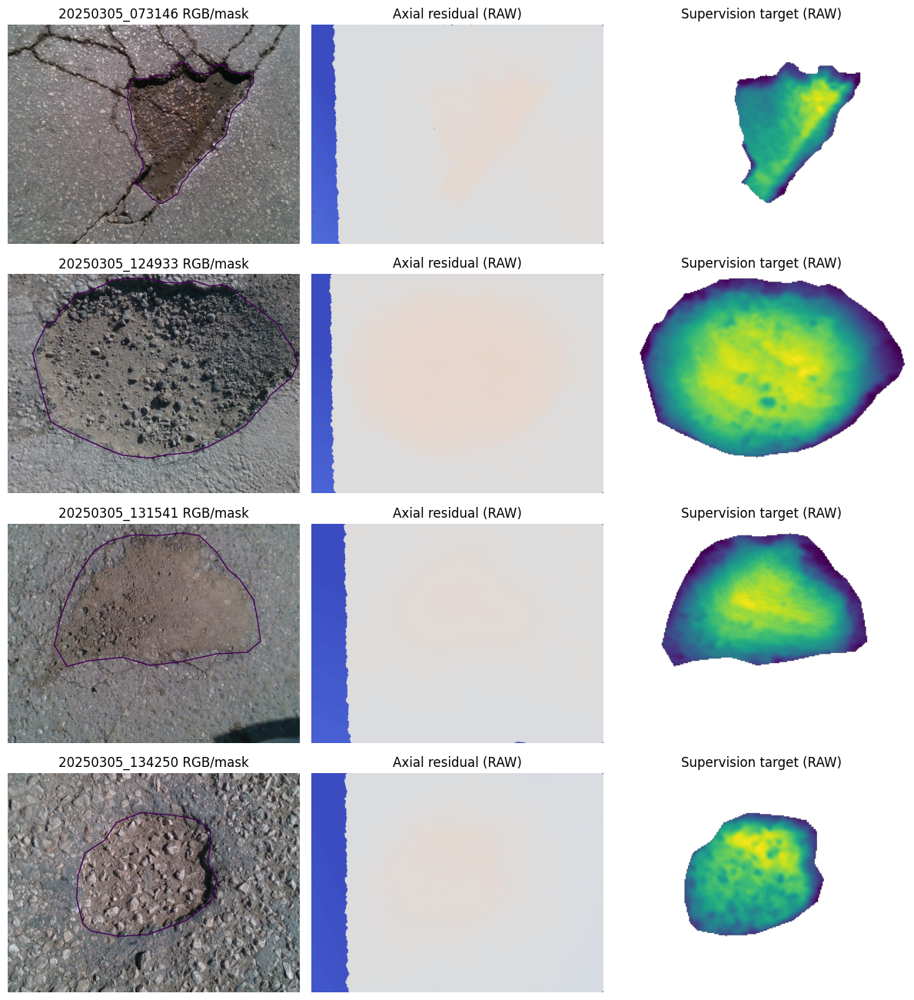


C3-11 SECTION 1 — TRAIN-ONLY RAW GEOMETRY TARGET PILOT
Selected training images: 24
QA outcomes: {'PASS_RAW_PILOT': 5, 'REVIEW': 19}
Saved target NPZ: 5
Potential cross-role duplicate IDs quarantined: 2
Validation/cross-day source depth accessed: NO
Verified physical units: NO
New model trained: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-11_section01_RAW_target_pilot_20261021T043311Z_367db5


In [5]:
# ================================================================
# CRDL COMPONENT 3 — C3-11 SECTION 1
# ROAD-RELATIVE RAW GEOMETRY SUPERVISION PILOT
#
# INPUT: PothRGBD RGB + YOLO polygons + uint16 depth
# OUTPUT: Supervised spatial depression targets
#
# DEVELOPMENT TRAINING GROUP ONLY
# NO VALIDATION / CROSS-DAY SOURCE DEPTH LOADING
# NO VERIFIED METRIC UNITS
# NO MODEL TRAINING IN THIS SECTION
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

from scipy.ndimage import distance_transform_edt
from PIL import Image, ImageDraw

import numpy as np
import matplotlib.pyplot as plt

import csv
import hashlib
import json
import uuid


# ================================================================
# 1. RESTORE EXACT PROJECT AND SOURCE LOCATIONS
# ================================================================

ROOT = Path('/content/drive/MyDrive')

PROJECT = (
    ROOT /
    'crdl_experiments' /
    'component3_fresh_v1'
)

DATA = (
    ROOT /
    'manushi_research_data' /
    'pothrgbd' /
    'PData-main'
)

OUT = (
    PROJECT /
    '07_evaluation' /
    'C3-09_physical_evidence_gate_v2_'
    '20261021T024723Z_ec15d662'
)

SPLIT2 = (
    OUT /
    'C3-10_section02_grouped_pilot_protocol_'
    '20261021T042524Z_735c9f'
)

ROLE_FILE = (
    SPLIT2 /
    'PROVISIONAL_pilot_role_manifest.csv'
)

REVIEW_FILE = (
    SPLIT2 /
    'cross_role_similarity_REVIEW.csv'
)

assert ROLE_FILE.is_file()
assert REVIEW_FILE.is_file()
assert DATA.is_dir()

print("=" * 72)
print("C3-11 SECTION 1 — RAW GEOMETRY TARGET GENERATION")
print("=" * 72)


# ================================================================
# 2. REUSABLE UTILITIES
# ================================================================

def load_csv(path):

    with path.open(
        newline='',
        encoding='utf-8'
    ) as f:

        return list(
            csv.DictReader(f)
        )


def sha256(path):

    h = hashlib.sha256()

    with path.open('rb') as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):

            h.update(block)

    return h.hexdigest()


# ================================================================
# 3. LOAD THE PROVISIONAL PILOT MANIFEST
# ================================================================

rows = load_csv(ROLE_FILE)

review = load_csv(REVIEW_FILE)

assert len(rows) == 996

assert len({
    r['sample_id']
    for r in rows
}) == 996


# ================================================================
# 4. QUARANTINE CROSS-ROLE SUSPECTED DUPLICATES
# ================================================================

quarantine = set()

for r in review:

    quarantine.update([
        r['sample_a'],
        r['sample_b']
    ])

known_ids = {
    r['sample_id']
    for r in rows
}

assert all(
    q in known_ids
    for q in quarantine
)


# ================================================================
# 5. RESTRICT TO THE PILOT TRAINING ROLE
# ================================================================

train = [

    r for r in rows

    if r['pilot_role'] == 'PILOT_TRAIN'
]

assert len(train) == 489

assert all(

    r['capture_day_proxy'] == '2025-03-05'

    for r in train
)

assert all(

    r['temporal_burst_proxy'] in (

        'POTHRGBD_TEMPORAL_0003',
        'POTHRGBD_TEMPORAL_0004'
    )

    for r in train
)


# ================================================================
# 6. SELECT A BOUNDED, REPRODUCIBLE PILOT
# ================================================================

N_PER_GROUP = {

    'POTHRGBD_TEMPORAL_0003': 8,

    'POTHRGBD_TEMPORAL_0004': 16
}

selected = []

for burst, n in N_PER_GROUP.items():

    pool = sorted(

        [

            r for r in train

            if (

                r['temporal_burst_proxy'] == burst

                and r['sample_id'] not in quarantine
            )
        ],

        key=lambda r: r['sample_id']
    )

    assert pool

    indices = np.unique(

        np.linspace(

            0,

            len(pool) - 1,

            min(len(pool), n),

            dtype=int
        )
    )

    selected.extend([

        pool[int(index)]

        for index in indices
    ])


assert len({

    r['sample_id']
    for r in selected

}) == len(selected)

assert all(

    r['sample_id'] not in quarantine

    for r in selected
)

print("Training pool:", len(train))
print("Pilot images selected:", len(selected))
print("Suspected duplicate IDs quarantined:", len(quarantine))


# ================================================================
# 7. PREDECLARED GEOMETRY QUALITY CONFIGURATION
# ================================================================

CFG = {

    'version':
        'C3-11_section01_raw_pilot_v1',

    'output_hw':
        [192, 256],

    'ring_inner_px':
        8,

    'ring_outer_px':
        55,

    'min_support_pixels':
        2500,

    'max_support_sample':
        16000,

    'min_mask_pixels':
        200,

    'min_valid_mask_fraction':
        0.90,

    'min_positive_residual_fraction':
        0.75,

    'min_signal_to_road_p95_ratio':
        1.5,

    'max_holdout_p95_to_signal_ratio':
        0.5,

    'min_heldout_sectors':
        4,

    'min_sector_samples':
        150,

    'seed':
        20261021,

    'raw_units_only':
        True,

    'target_name':
        'positive_road_relative_axial_residual_RAW',

    'physical_scale_verified':
        False,

    'scene_disjointness_verified':
        False,

    'source_roles':
        ['PILOT_TRAIN']
}


# ================================================================
# 8. CREATE VERSIONED TARGET OUTPUT DIRECTORY
# ================================================================

SAVE = (

    PROJECT /
    '04_geometry_targets' /

    (

        'C3-11_section01_RAW_target_pilot_'

        + datetime.now(
            timezone.utc
        ).strftime('%Y%m%dT%H%M%SZ')

        + '_'

        + uuid.uuid4().hex[:6]
    )
)

SAVE.mkdir(
    parents=True,
    exist_ok=False
)

(SAVE / 'targets').mkdir()

(
    SAVE / 'config.json'
).write_text(

    json.dumps(
        CFG,
        indent=2
    ),

    encoding='utf-8'
)


# ================================================================
# 9. DECODE YOLO POLYGON SEGMENTATION LABELS
# ================================================================

def decode_yolo_polygon(path, w, h):

    canvas = Image.new(
        'L',
        (w, h),
        0
    )

    draw = ImageDraw.Draw(canvas)

    count = 0

    lines = path.read_text(
        encoding='utf-8'
    ).splitlines()

    for i, line in enumerate(
        lines,
        start=1
    ):

        if not line.strip():
            continue

        values = np.fromstring(

            line,

            sep=' ',

            dtype=np.float64
        )

        valid_annotation = (

            len(values) >= 7

            and (len(values) - 1) % 2 == 0

            and np.isfinite(values).all()

            and values[0] == 0

            and np.all(
                values[1:] >= 0
            )

            and np.all(
                values[1:] <= 1
            )
        )

        if not valid_annotation:

            raise ValueError(

                f'Invalid class-0 YOLO '
                f'polygon on line {i}'
            )

        points = values[1:].reshape(
            -1, 2
        )

        polygon = [

            (

                round(
                    float(x) * (w - 1)
                ),

                round(
                    float(y) * (h - 1)
                )
            )

            for x, y in points
        ]

        draw.polygon(
            polygon,
            fill=1
        )

        count += 1

    return (

        np.asarray(
            canvas,
            dtype=bool
        ),

        count
    )


# ================================================================
# 10. ROBUST INVERSE-DEPTH ROAD-PLANE MODEL
# ================================================================

# Inverse depth is approximately affine in
# image coordinates for a planar road.
#
# This model reconstructs an axial road reference
# in the sensor's original raw depth units.

def irls_inv_plane(uu, vv, zz):

    A = np.column_stack([

        uu,

        vv,

        np.ones(
            len(zz),
            dtype=np.float64
        )
    ])

    y = 1.0 / zz

    coefficients = np.linalg.lstsq(

        A,
        y,
        rcond=None

    )[0]

    # Iteratively reweighted least squares.
    for _ in range(8):

        error = y - A @ coefficients

        sigma = max(

            1.4826 * np.median(

                np.abs(

                    error - np.median(error)
                )
            ),

            1e-12
        )

        weights = np.sqrt(

            np.minimum(

                1.0,

                1.345 * sigma
                / (np.abs(error) + 1e-12)
            )
        )

        coefficients = np.linalg.lstsq(

            A * weights[:, None],

            y * weights,

            rcond=None

        )[0]

    return coefficients


# ================================================================
# 11. AREA-AVERAGE RESIZING FOR SUPERVISION
# ================================================================

def resize_float_box(array, size):

    image = Image.fromarray(

        array.astype(
            np.float32
        )
    )

    resized = image.resize(

        size,

        Image.Resampling.BOX
    )

    return np.asarray(

        resized,

        dtype=np.float32
    )


# ================================================================
# 12. PROCESS TRAIN-ONLY GEOMETRY TARGETS
# ================================================================

results = []
previsual = []

for index, row in enumerate(
    selected,
    start=1
):

    sid = row['sample_id']

    rec = {

        'sample_id': sid,

        'temporal_burst_proxy':
            row['temporal_burst_proxy'],

        'pilot_role':
            'PILOT_TRAIN',

        'metric_units_verified':
            False,

        'training_performed':
            False,

        'qa_status':
            'UNPROCESSED',

        'target_filename':
            ''
    }

    try:

        # ----------------------------------------
        # Validate all source locations
        # ----------------------------------------

        paths = {

            key: Path(
                row[key + '_path']
            )

            for key in (
                'rgb',
                'depth',
                'label'
            )
        }

        for key, folder in [

            ('rgb', 'images'),

            ('depth', 'depths'),

            ('label', 'labels')
        ]:

            path = paths[key]

            assert path.is_file()

            assert not path.is_symlink()

            assert (

                path.parent.resolve()

                == (DATA / folder).resolve()
            )

        # ----------------------------------------
        # Load raw depth and RGB
        # ----------------------------------------

        z = np.load(

            paths['depth'],

            allow_pickle=False
        )

        with Image.open(
            paths['rgb']
        ) as im:

            rgb = np.asarray(
                im.convert('RGB')
            )

        if (

            z.ndim != 2

            or z.shape != rgb.shape[:2]

            or not np.issubdtype(
                z.dtype,
                np.number
            )
        ):

            raise ValueError(
                'Invalid RGB/depth dimensions '
                'or numeric format'
            )

        h, w = z.shape

        # ----------------------------------------
        # Load segmentation mask
        # ----------------------------------------

        mask, npolygons = decode_yolo_polygon(

            paths['label'],

            w,
            h
        )

        valid = (

            np.isfinite(z)

            & (z > 0)
        )

        rec.update({

            'mask_pixels':
                int(mask.sum()),

            'polygon_count':
                npolygons,

            'depth_dtype':
                str(z.dtype)
        })

        if (

            mask.sum() < CFG['min_mask_pixels']

            or npolygons == 0
        ):

            rec['qa_status'] = 'FAIL_MASK'

            results.append(rec)
            continue

        # ----------------------------------------
        # Healthy road ring
        # ----------------------------------------

        distance = distance_transform_edt(
            ~mask
        )

        ring = (

            (
                distance >= CFG['ring_inner_px']
            )

            & (
                distance <= CFG['ring_outer_px']
            )

            & valid
        )

        rec['ring_valid_pixels'] = int(
            ring.sum()
        )

        rec['mask_valid_depth_fraction'] = float(

            (mask & valid).sum()

            / mask.sum()
        )

        if ring.sum() < CFG['min_support_pixels']:

            rec['qa_status'] = 'FAIL_SUPPORT'

            results.append(rec)
            continue

        # ----------------------------------------
        # Normalized image coordinates
        # ----------------------------------------

        yy, xx = np.indices(
            z.shape
        )

        uu = (
            2 * (xx + 0.5) / w - 1
        )

        vv = (
            2 * (yy + 0.5) / h - 1
        )

        sy, sx = np.where(ring)

        # ----------------------------------------
        # Bounded deterministic reference samples
        # ----------------------------------------

        if len(sy) > CFG['max_support_sample']:

            seed = (

                CFG['seed']

                + int(
                    sid.replace('_', '')
                ) % 1000000
            )

            pick = np.random.default_rng(
                seed
            ).choice(

                len(sy),

                size=CFG['max_support_sample'],

                replace=False
            )

            sy, sx = (
                sy[pick],
                sx[pick]
            )

        # ----------------------------------------
        # Fit robust healthy-road reference
        # ----------------------------------------

        coefficients = irls_inv_plane(

            uu[sy, sx],

            vv[sy, sx],

            z[sy, sx].astype(np.float64)
        )

        denominator = (

            coefficients[0] * uu

            + coefficients[1] * vv

            + coefficients[2]
        )

        good_reference = (

            np.isfinite(denominator)

            & (denominator > 1e-9)
        )

        reference = np.full(

            z.shape,

            np.nan,

            dtype=np.float64
        )

        reference[good_reference] = (

            1.0 / denominator[good_reference]
        )

        usable = valid & good_reference

        inside = mask & usable

        support = ring & usable

        if (

            inside.sum() < 100

            or support.sum() < 1000
        ):

            rec['qa_status'] = 'FAIL_REFERENCE'

            results.append(rec)
            continue

        # ----------------------------------------
        # Calculate road-relative axial residual
        # ----------------------------------------

        residual = (

            z.astype(np.float64)

            - reference
        )

        signal = float(

            np.median(

                np.abs(
                    residual[inside]
                )
            )
        )

        road_p95 = float(

            np.percentile(

                np.abs(
                    residual[support]
                ),

                95
            )
        )

        signed = float(

            np.median(
                residual[inside]
            )
        )

        pos_fraction = float(

            (
                residual[inside] > 0
            ).mean()
        )

        # ----------------------------------------
        # Four-sector road reference holdout
        # ----------------------------------------

        cy, cx = np.mean(

            np.where(mask),

            axis=1
        )

        sectors = (

            (sy >= cy).astype(int) * 2

            + (sx >= cx).astype(int)
        )

        holdouts = []

        for sector_id in range(4):

            tr = sectors != sector_id

            te = sectors == sector_id

            if (

                tr.sum() < 1500

                or te.sum()
                < CFG['min_sector_samples']
            ):

                continue

            other = irls_inv_plane(

                uu[sy[tr], sx[tr]],

                vv[sy[tr], sx[tr]],

                z[
                    sy[tr],
                    sx[tr]
                ].astype(float)
            )

            den = (

                other[0] * uu[
                    sy[te],
                    sx[te]
                ]

                + other[1] * vv[
                    sy[te],
                    sx[te]
                ]

                + other[2]
            )

            allow = (

                np.isfinite(den)

                & (den > 1e-9)
            )

            if allow.sum() < CFG['min_sector_samples']:

                continue

            observed = z[

                sy[te][allow],

                sx[te][allow]

            ].astype(np.float64)

            predicted = (
                1.0 / den[allow]
            )

            holdouts.append(

                float(

                    np.percentile(

                        np.abs(

                            observed - predicted
                        ),

                        95
                    )
                )
            )

        worst = (

            max(holdouts)

            if holdouts

            else float('inf')
        )

        # ----------------------------------------
        # Predefined reliability diagnostics
        # ----------------------------------------

        ratio = signal / (
            road_p95 + 1e-9
        )

        hold_ratio = worst / (
            signal + 1e-9
        )

        flags = []

        if (

            rec['mask_valid_depth_fraction']

            < CFG['min_valid_mask_fraction']
        ):

            flags.append(
                'LOW_VALID_DEPTH_COVERAGE'
            )

        if (

            pos_fraction

            < CFG['min_positive_residual_fraction']
        ):

            flags.append(
                'UNCERTAIN_DEPRESSION_SIGN'
            )

        if (

            ratio

            < CFG['min_signal_to_road_p95_ratio']
        ):

            flags.append(
                'WEAK_ROAD_RELATIVE_SIGNAL'
            )

        if (

            len(holdouts)
            < CFG['min_heldout_sectors']

            or hold_ratio

            > CFG['max_holdout_p95_to_signal_ratio']
        ):

            flags.append(
                'UNSTABLE_REFERENCE_HOLDOUT'
            )

        rec.update({

            'signed_median_axial_RAW':
                signed,

            'median_abs_axial_RAW':
                signal,

            'road_p95_raw':
                road_p95,

            'signal_to_road_ratio':
                ratio,

            'positive_fraction':
                pos_fraction,

            'heldout_sector_count':
                len(holdouts),

            'worst_holdout_to_signal':
                hold_ratio,

            'qa_flags':
                flags,

            'depression_p95_raw':

                float(

                    np.percentile(

                        np.maximum(
                            residual[inside],
                            0
                        ),

                        95
                    )
                )
        })

        # ----------------------------------------
        # Retain all failed QA cases in manifest
        # ----------------------------------------

        if flags:

            rec['qa_status'] = 'REVIEW'

            results.append(rec)
            continue

        # ====================================================
        # 13. PREPARE NEURAL NETWORK TARGET RESOLUTION
        # ====================================================

        oh, ow = CFG['output_hw']

        size = (ow, oh)

        # Valid-pixel weighting prevents missing
        # depth values from contaminating resized targets.

        weight = inside.astype(
            np.float32
        )

        positive = np.where(

            inside,

            np.maximum(
                residual,
                0.0
            ),

            0.0

        ).astype(np.float32)

        low_weight = resize_float_box(

            weight,
            size
        )

        low_sum = resize_float_box(

            positive,
            size
        )

        low_mask = (

            np.asarray(

                Image.fromarray(

                    (mask * 255).astype(
                        np.uint8
                    )
                ).resize(

                    size,

                    Image.Resampling.NEAREST
                )
            ) > 0
        )

        loss_mask = (

            (low_weight >= 0.75)

            & low_mask
        )

        target = np.zeros(

            (oh, ow),

            dtype=np.float32
        )

        target[loss_mask] = (

            low_sum[loss_mask]

            / np.maximum(

                low_weight[loss_mask],

                1e-6
            )
        )

        if (

            not np.all(
                np.isfinite(target)
            )

            or loss_mask.sum() < 60
        ):

            rec['qa_status'] = (
                'REVIEW_DOWNSAMPLED_VALIDITY'
            )

            results.append(rec)
            continue

        # ====================================================
        # 14. SAVE ACTUAL SPATIAL SUPERVISION TARGET
        # ====================================================

        filename = (

            sid

            + '_ROAD_RELATIVE_AXIAL_RAW.npz'
        )

        target_path = (

            SAVE /
            'targets' /
            filename
        )

        np.savez_compressed(

            target_path,

            target_raw=target,

            loss_mask=loss_mask.astype(
                np.uint8
            ),

            pothole_mask=low_mask.astype(
                np.uint8
            ),

            source_hw=np.array(

                [h, w],

                dtype=np.int32
            )
        )

        rec['qa_status'] = 'PASS_RAW_PILOT'

        rec['target_filename'] = (

            'targets/' + filename
        )

        rec['loss_mask_pixels'] = int(
            loss_mask.sum()
        )

        # ----------------------------------------
        # Save source integrity
        # ----------------------------------------

        rec['rgb_sha256'] = sha256(
            paths['rgb']
        )

        rec['depth_sha256'] = sha256(
            paths['depth']
        )

        rec['label_sha256'] = sha256(
            paths['label']
        )

        rec['target_sha256'] = sha256(
            target_path
        )

        # ----------------------------------------
        # Preserve examples for visual QA
        # ----------------------------------------

        if len(previsual) < 4:

            previsual.append((

                sid,
                rgb,
                mask,

                z.astype(np.float32),

                residual,

                target,
                loss_mask
            ))

    except Exception as error:

        rec['qa_status'] = 'ERROR'

        rec['error'] = (

            f'{type(error).__name__}: {error}'
        )[:200]

    results.append(rec)

    print(

        f'[{index:02}/{len(selected):02}] '

        f'{sid} -> {rec["qa_status"]} '

        f'| SNR='

        f'{rec.get("signal_to_road_ratio", float("nan")):.2f}'
    )


# ================================================================
# 15. SAVE COMPLETE QUALITY MANIFEST
# ================================================================

fields = sorted({

    key

    for record in results

    for key in record
})

with (

    SAVE / 'train_only_target_qa.csv'

).open(

    'w',

    newline='',

    encoding='utf-8'
) as f:

    writer = csv.DictWriter(

        f,

        fieldnames=fields
    )

    writer.writeheader()
    writer.writerows(results)


# ================================================================
# 16. SAVE RESEARCH SUMMARY
# ================================================================

summary = {

    'version':
        CFG['version'],

    'selected_training_samples':
        len(selected),

    'source_candidate_train_count':
        len(train),

    'quarantine_sample_ids':
        sorted(quarantine),

    'excluded_suspect_hash_pairs':
        len(review),

    'qa_counts':
        dict(Counter(

            r['qa_status']

            for r in results
        )),

    'actual_target_npz_count':

        len(list(

            (SAVE / 'targets').glob(
                '*.npz'
            )
        )),

    'metric_units_verified':
        False,

    'scene_independence_verified':
        False,

    'pilot_only':
        True,

    'raw_sensor_geometry_training_eligible_only_after_review':
        False,

    'validation_and_cross_day_depths_loaded':
        False
}

(
    SAVE / 'summary.json'
).write_text(

    json.dumps(
        summary,
        indent=2
    ),

    encoding='utf-8'
)


# ================================================================
# 17. VISUALIZE SUCCESSFUL TRAINING TARGETS
# ================================================================

if previsual:

    fig, axes = plt.subplots(

        len(previsual),

        3,

        figsize=(
            12,
            3.3 * len(previsual)
        ),

        squeeze=False
    )

    for i, (

        sid,
        rgb,
        mask,
        z,
        residual,
        target,
        loss_mask

    ) in enumerate(previsual):

        # RGB input and segmentation
        axes[i, 0].imshow(rgb)

        axes[i, 0].contour(

            mask,

            levels=[0.5],

            linewidths=1
        )

        axes[i, 0].set_title(
            sid + ' RGB/mask'
        )

        # Full-resolution road-relative residual
        values = residual[
            np.isfinite(residual)
        ]

        scale = max(

            float(

                np.percentile(

                    np.abs(values),

                    98
                )
            ),

            1
        )

        axes[i, 1].imshow(

            np.ma.masked_invalid(
                residual
            ),

            cmap='coolwarm',

            vmin=-scale,

            vmax=scale
        )

        axes[i, 1].set_title(
            'Axial residual (RAW)'
        )

        # Training-ready spatial target
        axes[i, 2].imshow(

            np.ma.masked_where(

                ~loss_mask,

                target
            ),

            cmap='viridis'
        )

        axes[i, 2].set_title(
            'Supervision target (RAW)'
        )

        for ax in axes[i]:
            ax.axis('off')

    plt.tight_layout()

    plt.savefig(

        SAVE / 'selected_target_qa.png',

        dpi=140,

        bbox_inches='tight'
    )

    plt.show()

    plt.close(fig)


# ================================================================
# 18. CREATE SHA256 REPRODUCIBILITY MANIFEST
# ================================================================

receipts = []

for path in sorted(
    SAVE.rglob('*')
):

    if (

        path.is_file()

        and path.name != 'sha256_manifest.json'
    ):

        receipts.append({

            'relative_path':

                str(
                    path.relative_to(SAVE)
                ),

            'bytes':
                path.stat().st_size,

            'sha256':
                sha256(path)
        })

(
    SAVE / 'sha256_manifest.json'
).write_text(

    json.dumps(
        receipts,
        indent=2
    ),

    encoding='utf-8'
)


# ================================================================
# 19. FINAL C3-11 SECTION 1 RESULTS
# ================================================================

print("\n" + "=" * 72)

print(
    "C3-11 SECTION 1 — TRAIN-ONLY RAW GEOMETRY TARGET PILOT"
)

print("=" * 72)

print(
    "Selected training images:",
    len(selected)
)

print(
    "QA outcomes:",
    summary['qa_counts']
)

print(
    "Saved target NPZ:",
    summary['actual_target_npz_count']
)

print(
    "Potential cross-role duplicate IDs quarantined:",
    len(quarantine)
)

print(
    "Validation/cross-day source depth accessed: NO"
)

print(
    "Verified physical units: NO"
)

print(
    "New model trained: NO"
)

print("\nSaved:", SAVE)

print("=" * 72)

C3-11 SECTION 2 — TRAINING TARGET QUALITY AUDIT
Previously audited samples: 24
Output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-11_section01_RAW_target_pilot_20261021T043311Z_367db5/C3-11_section02_failure_evidence_20261021T044008Z_e689ec


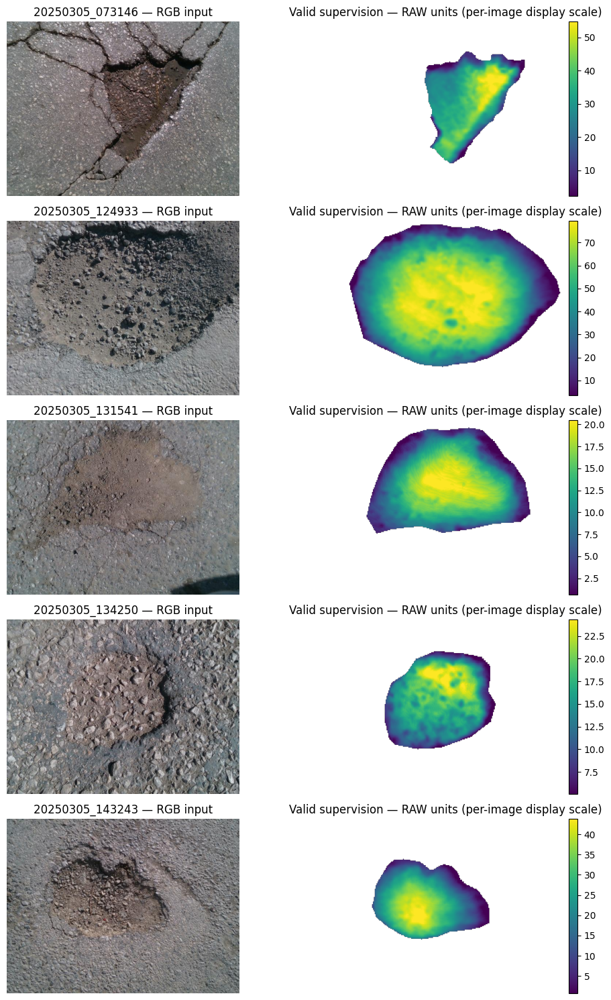


C3-11 SECTION 2 — TARGET QA & RUBRIC EVIDENCE
Audited training-only examples: 24
Statuses: {'PASS_RAW_PILOT': 5, 'REVIEW': 19}
Rejection/review reasons: {'UNSTABLE_REFERENCE_HOLDOUT': 18, 'WEAK_ROAD_RELATIVE_SIGNAL': 3, 'LOW_VALID_DEPTH_COVERAGE': 2}
Verified saved targets: 5

PER-SAMPLE RESULTS:
20250305_073146 | PASS_RAW_PILOT | SNR= 3.6540039350932956 | flags= 
20250305_074333 | REVIEW | SNR= 3.1792336697948054 | flags= UNSTABLE_REFERENCE_HOLDOUT
20250305_075013 | REVIEW | SNR= 2.016778596809396 | flags= UNSTABLE_REFERENCE_HOLDOUT
20250305_081309 | REVIEW | SNR= 3.5597284547293357 | flags= UNSTABLE_REFERENCE_HOLDOUT
20250305_082847 | REVIEW | SNR= 1.9114710239497454 | flags= UNSTABLE_REFERENCE_HOLDOUT
20250305_083506 | REVIEW | SNR= 1.6172092886649247 | flags= UNSTABLE_REFERENCE_HOLDOUT
20250305_084512 | REVIEW | SNR= 2.8196186565462837 | flags= UNSTABLE_REFERENCE_HOLDOUT
20250305_085116 | REVIEW | SNR= 1.2867378493866173 | flags= WEAK_ROAD_RELATIVE_SIGNAL;UNSTABLE_REFERENCE_HOLDOU

In [6]:
# ================================================================
# CRDL COMPONENT 3 — C3-11 SECTION 2
# TRAINING TARGET QUALITY & RUBRIC EVIDENCE
#
# No model training
# No target regeneration
# No threshold changes
# No physical-unit assumptions
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from PIL import Image, ImageOps, ImageDraw

import ast
import csv
import json
import hashlib
import uuid

import numpy as np
import matplotlib.pyplot as plt


# ================================================================
# 1. RESTORE PROJECT PATHS
# ================================================================

ROOT = Path('/content/drive/MyDrive')

PROJECT = (
    ROOT /
    'crdl_experiments' /
    'component3_fresh_v1'
)

DATA = (
    ROOT /
    'manushi_research_data' /
    'pothrgbd' /
    'PData-main'
)

PILOT = (
    PROJECT /
    '04_geometry_targets' /
    'C3-11_section01_RAW_target_pilot_'
    '20261021T043311Z_367db5'
)

OUT09 = (
    PROJECT /
    '07_evaluation' /
    'C3-09_physical_evidence_gate_v2_'
    '20261021T024723Z_ec15d662'
)

ROLE_FILE = (
    OUT09 /
    'C3-10_section02_grouped_pilot_protocol_'
    '20261021T042524Z_735c9f' /
    'PROVISIONAL_pilot_role_manifest.csv'
)

QA_FILE = (
    PILOT /
    'train_only_target_qa.csv'
)

assert QA_FILE.is_file()
assert ROLE_FILE.is_file()
assert (PILOT / 'targets').is_dir()


# ================================================================
# 2. CREATE NEW VERSIONED OUTPUT
# ================================================================

RUN = PILOT / (

    'C3-11_section02_failure_evidence_'

    + datetime.now(
        timezone.utc
    ).strftime('%Y%m%dT%H%M%SZ_')

    + uuid.uuid4().hex[:6]
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)


# ================================================================
# 3. REUSABLE FILE FUNCTIONS
# ================================================================

def read_csv(path):

    with path.open(
        newline='',
        encoding='utf-8'
    ) as f:

        return list(
            csv.DictReader(f)
        )


def write_csv(filename, records, columns):

    with (RUN / filename).open(
        'w',
        newline='',
        encoding='utf-8'
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=columns
        )

        writer.writeheader()
        writer.writerows(records)


def write_json(filename, obj):

    (RUN / filename).write_text(

        json.dumps(
            obj,
            indent=2,
            allow_nan=False,
            default=str
        ),

        encoding='utf-8'
    )


def sha256_file(path):

    h = hashlib.sha256()

    with path.open('rb') as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):
            h.update(block)

    return h.hexdigest()


def num(value):

    try:
        result = float(value)

        if np.isfinite(result):
            return result

    except (ValueError, TypeError):
        pass

    return None


def parse_flags(raw):

    if not raw or raw in ('nan', 'None'):
        return []

    try:

        value = ast.literal_eval(raw)

        if isinstance(value, list):
            return [str(v) for v in value]

    except (SyntaxError, ValueError):
        pass

    return ['BAD_FLAGS_FORMAT']


# ================================================================
# 4. LOAD AND VERIFY ORIGINAL PILOT MANIFESTS
# ================================================================

qa_rows = read_csv(QA_FILE)

role_rows = read_csv(ROLE_FILE)

role_by_id = {
    r['sample_id']: r
    for r in role_rows
}

assert len(qa_rows) == 24

assert len({
    r['sample_id']
    for r in qa_rows
}) == 24

assert len(role_by_id) == 996

# Strict train-only verification.
assert all(

    r['sample_id'] in role_by_id

    and role_by_id[
        r['sample_id']
    ]['pilot_role'] == 'PILOT_TRAIN'

    for r in qa_rows
)

print("=" * 70)
print("C3-11 SECTION 2 — TRAINING TARGET QUALITY AUDIT")
print("=" * 70)

print("Previously audited samples:", len(qa_rows))
print("Output:", RUN)


# ================================================================
# 5. ANALYZE ALL 24 QA RECORDS
# ================================================================

summaries = []

status_counts = Counter()

flag_counts = Counter()

passes = []

for row in qa_rows:

    sid = row['sample_id']

    status = row['qa_status']

    flags = parse_flags(
        row.get('qa_flags')
    )

    status_counts[status] += 1

    for flag in flags:
        flag_counts[flag] += 1

    summary_row = {

        'sample_id': sid,

        'burst':
            role_by_id[sid][
                'temporal_burst_proxy'
            ],

        'status': status,

        'flags':
            ';'.join(flags),

        'coverage':
            num(
                row.get(
                    'mask_valid_depth_fraction'
                )
            ),

        'signal_to_road_ratio':
            num(
                row.get(
                    'signal_to_road_ratio'
                )
            ),

        'worst_holdout_to_signal':
            num(
                row.get(
                    'worst_holdout_to_signal'
                )
            ),

        'positive_fraction':
            num(
                row.get(
                    'positive_fraction'
                )
            ),

        'target_filename':
            row.get(
                'target_filename',
                ''
            )
    }

    summaries.append(summary_row)

    if status == 'PASS_RAW_PILOT':
        passes.append(row)


assert status_counts['PASS_RAW_PILOT'] == 5

assert len(summaries) == sum(
    status_counts.values()
)


# ================================================================
# 6. VERIFY SAVED TARGET FILE INTEGRITY
# ================================================================

target_stats = []

for row in passes:

    sid = row['sample_id']

    relative = Path(
        row['target_filename']
    )

    # Strictly limit files to original pilot
    # target directory.

    assert not relative.is_absolute()

    assert relative.parts[0] == 'targets'

    assert len(relative.parts) == 2

    target_path = (
        PILOT / relative
    ).resolve()

    assert target_path.parent == (
        PILOT / 'targets'
    ).resolve()

    assert target_path.is_file()
    assert not target_path.is_symlink()

    expected_hash = row.get(
        'target_sha256',
        ''
    )

    assert expected_hash

    assert sha256_file(
        target_path
    ) == expected_hash, (
        f'Target checksum error: {sid}'
    )

    # -------------------------------------------
    # Validate actual stored neural-network label
    # -------------------------------------------

    with np.load(
        target_path,
        allow_pickle=False
    ) as archive:

        assert {

            'target_raw',
            'loss_mask',
            'pothole_mask',
            'source_hw'

        }.issubset(set(archive.files))

        target = archive[
            'target_raw'
        ]

        loss_mask = archive[
            'loss_mask'
        ].astype(bool)

        pothole_mask = archive[
            'pothole_mask'
        ].astype(bool)

        assert target.shape == (192, 256)

        assert loss_mask.shape == target.shape

        assert pothole_mask.shape == target.shape

        # Supervision cannot extend outside
        # the labeled pothole footprint.

        assert np.all(
            ~loss_mask | pothole_mask
        )

        values = target[loss_mask]

        assert values.size >= 60

        assert np.isfinite(
            values
        ).all()

        assert (
            values >= 0
        ).all()

        target_stats.append({

            'sample_id': sid,

            'loss_pixels':
                int(loss_mask.sum()),

            'min_raw':
                float(values.min()),

            'median_raw':
                float(np.median(values)),

            'p95_raw':
                float(
                    np.percentile(
                        values, 95
                    )
                ),

            'max_raw':
                float(values.max()),

            'sha256':
                expected_hash
        })


# ================================================================
# 7. SAVE COMPLETE FAILURE ANALYSIS
# ================================================================

write_csv(

    'all_24_quality_reasons.csv',

    summaries,

    list(summaries[0])
)

write_csv(

    'five_verified_target_statistics.csv',

    target_stats,

    list(target_stats[0])
)

write_csv(

    'quality_flag_frequencies.csv',

    [

        {
            'flag': flag,
            'samples': count
        }

        for flag, count
        in flag_counts.most_common()
    ],

    ['flag', 'samples']
)


# ================================================================
# 8. GENERATE ALL-24 VISUAL REVIEW CONTACT SHEET
# ================================================================

# This includes passes AND failures.
# No numerical targets are changed.

w = 240
h = 155
caption_h = 49
cols = 4

nrows = (

    len(summaries)
    + cols - 1

) // cols

sheet = Image.new(

    'RGB',

    (
        cols * w,
        nrows * (h + caption_h)
    ),

    (244, 244, 244)
)

draw = ImageDraw.Draw(sheet)

for i, row in enumerate(summaries):

    sid = row['sample_id']

    source = Path(
        role_by_id[sid]['rgb_path']
    )

    assert source.is_file()
    assert not source.is_symlink()

    assert source.parent.resolve() == (
        DATA / 'images'
    ).resolve()

    with Image.open(source) as image:

        thumbnail = ImageOps.pad(

            image.convert('RGB'),

            (w, h)
        )

    x = (i % cols) * w

    y = (
        i // cols
    ) * (h + caption_h)

    sheet.paste(
        thumbnail,
        (x, y)
    )

    draw.text(

        (x + 3, y + h + 2),

        sid,

        fill=(0, 0, 0)
    )

    draw.text(

        (x + 3, y + h + 18),

        row['status'],

        fill=(0, 0, 0)
    )

    short_flag = (

        row['flags'].split(';')[0]

        if row['flags']

        else '-'
    )

    draw.text(

        (x + 3, y + h + 33),

        short_flag[:34],

        fill=(0, 0, 0)
    )


sheet.save(

    RUN / 'all_24_review_contact_sheet.jpg',

    quality=90
)


# ================================================================
# 9. IMPROVE THE TARGET VISUALIZATION
# ================================================================

# IMPORTANT:
# We only change the display range.
#
# We DO NOT edit, regenerate, renormalize,
# or overwrite original stored targets.
#
# Each image has its own labeled color scale.
# No mm or physical-unit inference.

if passes:

    fig, axs = plt.subplots(

        len(passes),

        2,

        figsize=(
            10,
            3 * len(passes)
        ),

        squeeze=False
    )

    for i, row in enumerate(passes):

        sid = row['sample_id']

        source = Path(
            role_by_id[sid]['rgb_path']
        )

        with Image.open(source) as im:

            img = np.asarray(
                im.convert('RGB')
            )

        with np.load(

            PILOT / row['target_filename'],

            allow_pickle=False

        ) as archive:

            target = archive[
                'target_raw'
            ].astype(np.float32)

            valid = archive[
                'loss_mask'
            ].astype(bool)

        values = target[valid]

        lo, hi = np.percentile(

            values,

            [2, 98]
        )

        if hi <= lo:
            hi = lo + 1e-6

        # ----------------------------------------
        # RGB visualization
        # ----------------------------------------

        axs[i, 0].imshow(img)

        axs[i, 0].set_title(

            sid + ' — RGB input'
        )

        # ----------------------------------------
        # Correctly displayed target
        # ----------------------------------------

        plotted = axs[i, 1].imshow(

            np.ma.masked_where(

                ~valid,

                target
            ),

            vmin=lo,

            vmax=hi,

            cmap='viridis'
        )

        axs[i, 1].set_title(

            'Valid supervision — RAW units '
            '(per-image display scale)'
        )

        fig.colorbar(

            plotted,

            ax=axs[i, 1],

            fraction=0.045,

            pad=0.02
        )

        for ax in axs[i]:
            ax.axis('off')

    fig.tight_layout()

    fig.savefig(

        RUN /
        'verified_targets_with_correct_color_scales.png',

        dpi=140,

        bbox_inches='tight'
    )

    plt.show()

    plt.close(fig)


# ================================================================
# 10. CREATE EXCELLENT-GRADE RUBRIC EVIDENCE MATRIX
# ================================================================

rubric = [

    (
        'Problem definition',

        'Research problem, assumptions '
        'and measurable acceptance criteria',

        'IN_PROGRESS'
    ),

    (
        'Proof of concept',

        'Trained checkpoint, cold-load inference, '
        'quantitative demo and working integration',

        'NOT_COMPLETE'
    ),

    (
        'Key knowledge pillars',

        'Machine learning, robust geometry, '
        'computer vision, reliability and APIs',

        'IN_PROGRESS'
    ),

    (
        'Technology depth',

        'Method justification, ablations '
        'and reproducible experiments',

        'IN_PROGRESS'
    ),

    (
        'Design excellence',

        'Versioned architecture and '
        'real C1/C2 interface tests',

        'IN_PROGRESS'
    ),

    (
        'Prototype/research completion',

        'Working geometry and severity '
        'pipeline with acceptance tests',

        'NOT_COMPLETE'
    ),

    (
        'Standards and best practices',

        'Leakage protection, provenance, '
        'checksums, testing and uncertainty',

        'IN_PROGRESS'
    ),

    (
        'Functional requirements',

        'Traceable requirements for depth, '
        'area, volume, cracks, severity '
        'and abstention',

        'IN_PROGRESS'
    ),

    (
        'Risk mitigation',

        'Calibration, domain shift, '
        'label reliability, duplication '
        'and unsupported units',

        'IN_PROGRESS'
    )
]

write_csv(

    'rubric_evidence_matrix.csv',

    [

        {

            'criterion': criterion,

            'required_proof': proof,

            'status': status
        }

        for criterion, proof, status
        in rubric
    ],

    [
        'criterion',
        'required_proof',
        'status'
    ]
)


# ================================================================
# 11. SAVE RESEARCH DECISION
# ================================================================

decision = {

    'stage':
        'C3-11_SECTION2_TARGET_QA_AND_RUBRIC_EVIDENCE',

    'source_pilot':
        str(PILOT),

    'audited_training_images':
        len(summaries),

    'status_counts':
        dict(status_counts),

    'pass_fraction_of_selected_nonrandom_pilot':

        len(passes) / len(summaries),

    'flag_frequencies':
        dict(flag_counts),

    'verified_target_files':
        len(target_stats),

    'raw_units_only':
        True,

    'scale_certified':
        False,

    'scene_independence_certified':
        False,

    'model_trained':
        False,

    'note':

        'These 24 examples were selected '
        'deterministically and do not estimate '
        'the acceptance rate of all 489 '
        'training candidates.',

    'next':

        'Review dominant rejection reasons; '
        'investigate numerical or geometric '
        'defects without relaxing quality '
        'criteria post hoc; expand the '
        'train-only target audit; then '
        'prepare actual ML training.'
}

write_json(

    'section2_decision.json',

    decision
)


# ================================================================
# 12. GENERATE ARTIFACT CHECKSUMS
# ================================================================

receipts = []

for path in sorted(
    RUN.iterdir()
):

    if (

        path.is_file()

        and path.name != 'checksums.json'
    ):

        receipts.append({

            'filename':
                path.name,

            'sha256':
                sha256_file(path),

            'bytes':
                path.stat().st_size
        })


write_json(
    'checksums.json',
    receipts
)


# ================================================================
# 13. FINAL OUTPUT
# ================================================================

print("\n" + "=" * 70)

print(
    "C3-11 SECTION 2 — TARGET QA & RUBRIC EVIDENCE"
)

print("=" * 70)

print(
    "Audited training-only examples:",
    len(summaries)
)

print(
    "Statuses:",
    dict(status_counts)
)

print(
    "Rejection/review reasons:",
    dict(flag_counts)
)

print(
    "Verified saved targets:",
    len(target_stats)
)

print("\nPER-SAMPLE RESULTS:")

for row in summaries:

    print(

        row['sample_id'],

        '|', row['status'],

        '| SNR=', row['signal_to_road_ratio'],

        '| flags=', row['flags']
    )

print(
    "\nMetric calibration verified: NO"
)

print(
    "Scene-independent evaluation established: NO"
)

print(
    "New ML training performed: NO"
)

print("\nOutput:", RUN)

print("=" * 70)

Synthetic quadratic reference test: PASS
01/24 20250305_073146 | previous=PASS_RAW_PILOT | plane=PASS_EXPLORATORY | quadratic=REVIEW
02/24 20250305_074333 | previous=REVIEW | plane=REVIEW | quadratic=REVIEW
03/24 20250305_075013 | previous=REVIEW | plane=REVIEW | quadratic=REVIEW
04/24 20250305_081309 | previous=REVIEW | plane=REVIEW | quadratic=REVIEW
05/24 20250305_082847 | previous=REVIEW | plane=REVIEW | quadratic=REVIEW
06/24 20250305_083506 | previous=REVIEW | plane=REVIEW | quadratic=REVIEW
07/24 20250305_084512 | previous=REVIEW | plane=REVIEW | quadratic=REVIEW
08/24 20250305_085116 | previous=REVIEW | plane=REVIEW | quadratic=REVIEW
09/24 20250305_093835 | previous=REVIEW | plane=REVIEW | quadratic=REVIEW
10/24 20250305_095515 | previous=REVIEW | plane=REVIEW | quadratic=REVIEW
11/24 20250305_100402 | previous=REVIEW | plane=REVIEW | quadratic=REVIEW
12/24 20250305_103013 | previous=REVIEW | plane=REVIEW | quadratic=REVIEW
13/24 20250305_110948 | previous=REVIEW | plane=REVIE

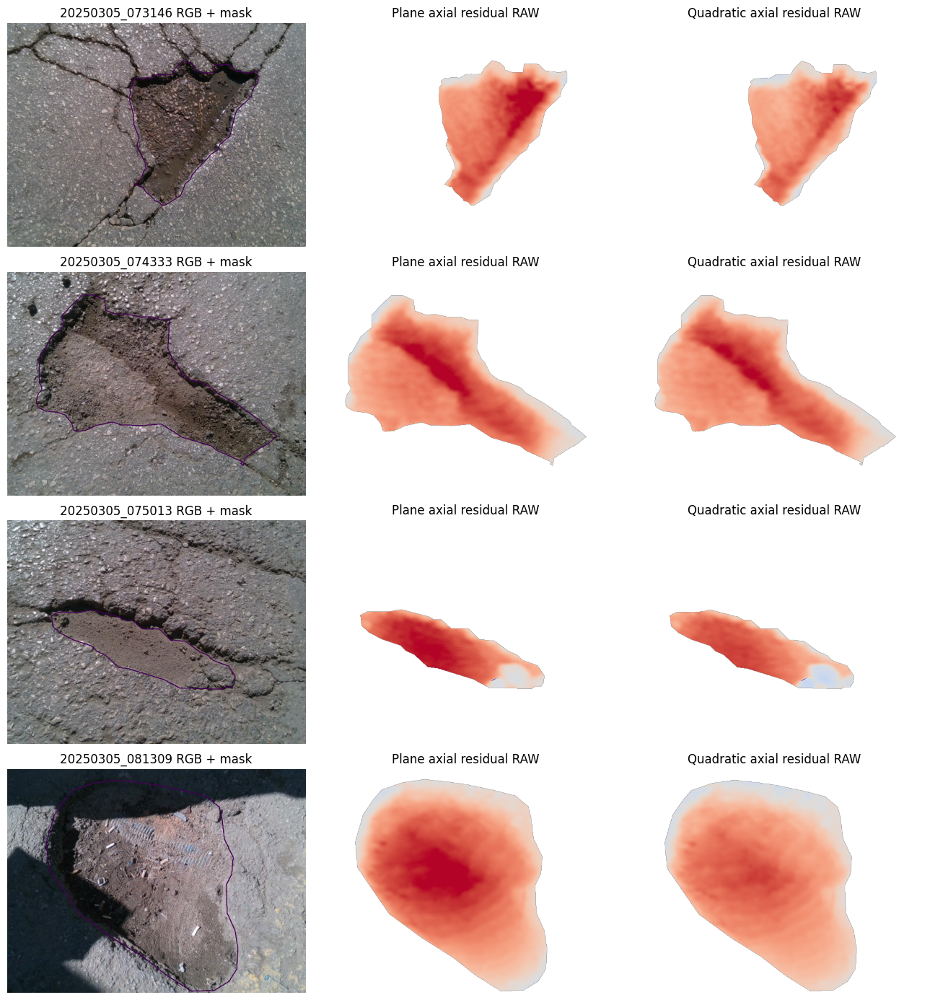


C3-11 SECTION 3 — CONTROLLED REFERENCE ABLATION
Samples: 24
Plane: {'PASS_EXPLORATORY': 5, 'REVIEW': 19}
Quadratic: {'REVIEW': 22, 'PASS_EXPLORATORY': 2}
Paired holdout results: 24
Quadratic lower worst-sector P95: 11
Median worst-sector P95 RAW | plane: 14.605300616017905 | quadratic: 15.354495165001246
Metric units: UNVERIFIED
New training: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-11_section01_RAW_target_pilot_20261021T043311Z_367db5/C3-11_section03_reference_ablation_20261021T045347Z_b3e96e


In [7]:
# ================================================================
# CRDL COMPONENT 3 | C3-11 SECTION 3
# ROAD-REFERENCE MODEL ABLATION
#
# Train-only development pilot
# No new labels | No ML training
# No metric-depth claims
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from scipy.ndimage import distance_transform_edt
from PIL import Image, ImageDraw

import numpy as np
import matplotlib.pyplot as plt
import csv
import json
import hashlib
import uuid


# ================================================================
# 1. RESTORE EXACT SOURCE PATHS
# ================================================================

ROOT = Path('/content/drive/MyDrive')

PROJECT = (
    ROOT / 'crdl_experiments'
    / 'component3_fresh_v1'
)

DATA = (
    ROOT / 'manushi_research_data'
    / 'pothrgbd' / 'PData-main'
)

PILOT = (
    PROJECT / '04_geometry_targets'
    / 'C3-11_section01_RAW_target_pilot_'
      '20261021T043311Z_367db5'
)

C310 = (
    PROJECT / '07_evaluation'
    / 'C3-09_physical_evidence_gate_v2_'
      '20261021T024723Z_ec15d662'
    / 'C3-10_section02_grouped_pilot_protocol_'
      '20261021T042524Z_735c9f'
)

QA = PILOT / 'train_only_target_qa.csv'

ROLES = (
    C310 / 'PROVISIONAL_pilot_role_manifest.csv'
)

assert QA.is_file()
assert ROLES.is_file()


# ================================================================
# 2. LOAD EXACTLY THE SAME 24 TRAINING EXAMPLES
# ================================================================

with QA.open(
    newline='',
    encoding='utf-8'
) as f:

    qa_rows = list(csv.DictReader(f))

with ROLES.open(
    newline='',
    encoding='utf-8'
) as f:

    role_rows = list(csv.DictReader(f))

assert len(qa_rows) == 24

by_id = {
    r['sample_id']: r
    for r in role_rows
}

assert len(by_id) == 996

assert all(

    r['sample_id'] in by_id

    and by_id[r['sample_id']]['pilot_role']
    == 'PILOT_TRAIN'

    for r in qa_rows

), "Non-training sample detected."


# ================================================================
# 3. CREATE A NEW VERSIONED OUTPUT FOLDER
# ================================================================

OUT = PILOT / (

    'C3-11_section03_reference_ablation_'

    + datetime.now(
        timezone.utc
    ).strftime('%Y%m%dT%H%M%SZ_')

    + uuid.uuid4().hex[:6]
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)


# ================================================================
# 4. PREDECLARED COMPARISON CONFIGURATION
# ================================================================

CFG = {

    'ring_inner_px': 8,
    'ring_outer_px': 55,

    'min_healthy_support': 2500,
    'max_sample': 12000,

    'min_mask_pixels': 200,

    'min_coverage': 0.90,
    'min_positive': 0.75,

    'min_signal_ratio': 1.5,

    'max_holdout_to_signal': 0.5,

    'min_sector_test': 150,

    'seed': 20261021,

    'irls_iterations': 8,

    'units': 'UNVERIFIED_RAW_SENSOR',

    'training': False
}

(OUT / 'protocol.json').write_text(

    json.dumps(CFG, indent=2),

    encoding='utf-8'
)


# ================================================================
# 5. DECODE POTHOLE POLYGON MASKS
# ================================================================

def polygon_mask(path, w, h):

    canvas = Image.new(
        'L',
        (w, h),
        0
    )

    draw = ImageDraw.Draw(canvas)

    n = 0

    for line in path.read_text(
        encoding='utf-8'
    ).splitlines():

        if not line.strip():
            continue

        parts = np.fromstring(
            line,
            sep=' ',
            dtype=np.float64
        )

        is_valid = (

            len(parts) >= 7

            and (len(parts) - 1) % 2 == 0

            and np.isfinite(parts).all()

            and parts[0] == 0

            and (parts[1:] >= 0).all()

            and (parts[1:] <= 1).all()
        )

        if not is_valid:

            raise ValueError(
                'Invalid YOLO polygon'
            )

        xy = parts[1:].reshape(-1, 2)

        vertices = [

            (
                round(float(x) * (w - 1)),
                round(float(y) * (h - 1))
            )

            for x, y in xy
        ]

        draw.polygon(vertices, fill=1)

        n += 1

    return np.asarray(
        canvas,
        dtype=bool
    ), n


# ================================================================
# 6. ROAD-REFERENCE DESIGN MATRICES
# ================================================================

def features(u, v, model):

    # Inverse-depth plane:
    # 1/Z = a0 + a1*u + a2*v

    cols = [
        np.ones_like(u),
        u,
        v
    ]

    if model == 'quadratic':

        # Quadratic extension:
        # 1/Z = a0+a1*u+a2*v
        #       +a3*u²+a4*u*v+a5*v²

        cols += [
            u*u,
            u*v,
            v*v
        ]

    elif model != 'plane':

        raise ValueError(model)

    return np.column_stack(cols)


# ================================================================
# 7. ROBUST IRLS FITTING
# ================================================================

def robust_fit(u, v, z, model):

    A = features(u, v, model)

    y = 1.0 / z

    if (

        A.shape[0] < 1000

        or np.linalg.matrix_rank(A) < A.shape[1]

    ):

        raise ValueError(
            'Insufficient/rank-deficient support'
        )

    coef = np.linalg.lstsq(
        A,
        y,
        rcond=None
    )[0]

    for _ in range(CFG['irls_iterations']):

        error = y - A @ coef

        scale = max(

            1.4826 * np.median(
                np.abs(error - np.median(error))
            ),

            1e-12
        )

        weights = np.sqrt(

            np.minimum(

                1.0,

                1.345 * scale
                / (np.abs(error) + 1e-12)
            )
        )

        coef = np.linalg.lstsq(

            A * weights[:, None],

            y * weights,

            rcond=None

        )[0]

    return coef


# ================================================================
# 8. PREDICT THE REFERENCE ROAD DEPTH
# ================================================================

def predict_z(u, v, coef, model):

    inv = features(

        np.asarray(u).ravel(),

        np.asarray(v).ravel(),

        model

    ) @ coef

    z = np.full(
        inv.shape,
        np.nan,
        dtype=float
    )

    valid = (
        np.isfinite(inv)
        & (inv > 1e-10)
    )

    z[valid] = 1.0 / inv[valid]

    return z.reshape(
        np.asarray(u).shape
    )


# ================================================================
# 9. MATCHED MODEL EVALUATION
# ================================================================

def examine(z, mask, model, sid):

    h, w = z.shape

    valid = (
        np.isfinite(z)
        & (z > 0)
    )

    if mask.sum() < CFG['min_mask_pixels']:

        raise ValueError('Too few mask pixels')

    distance = distance_transform_edt(~mask)

    ring = (

        (distance >= CFG['ring_inner_px'])

        & (distance <= CFG['ring_outer_px'])

        & valid
    )

    if ring.sum() < CFG['min_healthy_support']:

        raise ValueError(
            'Too few valid road reference pixels'
        )

    yy, xx = np.indices(z.shape)

    u = 2 * (xx + 0.5) / w - 1
    v = 2 * (yy + 0.5) / h - 1

    sy, sx = np.where(ring)

    # Deterministic sampling of road-support pixels.
    if len(sy) > CFG['max_sample']:

        seed = (
            CFG['seed']
            + int(sid.replace('_', '')) % 1000000
        )

        choice = np.random.default_rng(
            seed
        ).choice(

            len(sy),

            size=CFG['max_sample'],

            replace=False
        )

        sy, sx = sy[choice], sx[choice]

    # Full healthy-road fit.
    coef = robust_fit(

        u[sy, sx],

        v[sy, sx],

        z[sy, sx].astype(float),

        model
    )

    reference = predict_z(
        u, v, coef, model
    )

    usable = (
        valid & np.isfinite(reference)
    )

    inside = mask & usable
    road = ring & usable

    if inside.sum() < 100 or road.sum() < 1000:

        raise ValueError(
            'Invalid fitted road support'
        )

    # Positive residual means farther along
    # the camera optical axis, not necessarily
    # physical road-normal depression.
    residual = z.astype(float) - reference

    signal = float(

        np.median(
            np.abs(residual[inside])
        )
    )

    road_p95 = float(

        np.percentile(
            np.abs(residual[road]),
            95
        )
    )

    signed = float(
        np.median(residual[inside])
    )

    positive_fraction = float(
        np.mean(residual[inside] > 0)
    )

    coverage = float(
        (mask & valid).sum() / mask.sum()
    )

    # ------------------------------------------------
    # Four-sector holdout evaluation
    # ------------------------------------------------

    cy, cx = np.mean(
        np.where(mask),
        axis=1
    )

    sector = (

        (sy >= cy).astype(int) * 2

        + (sx >= cx).astype(int)
    )

    sector_errors = []

    for i in range(4):

        train = sector != i
        test = sector == i

        if (

            train.sum() < 1500

            or test.sum() < CFG['min_sector_test']

        ):

            continue

        candidate = robust_fit(

            u[sy[train], sx[train]],

            v[sy[train], sx[train]],

            z[
                sy[train],
                sx[train]
            ].astype(float),

            model
        )

        predicted = predict_z(

            u[sy[test], sx[test]],

            v[sy[test], sx[test]],

            candidate,

            model
        )

        valid_pred = np.isfinite(predicted)

        if valid_pred.sum() < CFG['min_sector_test']:

            continue

        observed = z[

            sy[test][valid_pred],

            sx[test][valid_pred]

        ].astype(float)

        error = observed - predicted[valid_pred]

        sector_errors.append(

            float(

                np.percentile(
                    np.abs(error),
                    95
                )
            )
        )

    worst = (

        max(sector_errors)

        if sector_errors

        else float('inf')
    )

    ratio = signal / (road_p95 + 1e-9)

    holdout_ratio = worst / (signal + 1e-9)

    # ------------------------------------------------
    # Keep existing exploratory thresholds
    # ------------------------------------------------

    flags = []

    if coverage < CFG['min_coverage']:

        flags.append(
            'LOW_VALID_DEPTH_COVERAGE'
        )

    if positive_fraction < CFG['min_positive']:

        flags.append(
            'UNCERTAIN_DEPRESSION_SIGN'
        )

    if ratio < CFG['min_signal_ratio']:

        flags.append(
            'WEAK_ROAD_RELATIVE_SIGNAL'
        )

    if (

        len(sector_errors) < 4

        or holdout_ratio > CFG['max_holdout_to_signal']

    ):

        flags.append(
            'UNSTABLE_REFERENCE_HOLDOUT'
        )

    # Rim consistency is an additional
    # diagnostic; its value is not yet used
    # to change pass/review thresholds.
    rim = (

        mask

        & (distance_transform_edt(mask) <= 3)

        & usable
    )

    rim_p95 = (

        float(
            np.percentile(
                np.abs(residual[rim]),
                95
            )
        )

        if rim.sum() > 20

        else None
    )

    metrics = {

        'signal_raw': signal,

        'road_p95_raw': road_p95,

        'ratio': ratio,

        'holdout_count': len(sector_errors),

        'holdout_worst_p95_raw':

            float(worst)
            if np.isfinite(worst)
            else None,

        'holdout_ratio':

            float(holdout_ratio)
            if np.isfinite(holdout_ratio)
            else None,

        'median_signed_raw': signed,

        'positive_fraction': positive_fraction,

        'coverage': coverage,

        'rim_abs_p95_raw': rim_p95,

        'flags': flags,

        'qa': (
            'PASS_EXPLORATORY'
            if not flags
            else 'REVIEW'
        )
    }

    return metrics, residual, inside


# ================================================================
# 10. SYNTHETIC MATHEMATICAL SMOKE TEST
# ================================================================

h, w = 96, 128

Y, X = np.indices((h, w))

uu = 2 * (X + 0.5) / w - 1
vv = 2 * (Y + 0.5) / h - 1

true_inverse = (

    0.00095

    + 0.00003 * uu

    - 0.00002 * vv

    + 0.00001 * uu**2
)

true_road = 1.0 / true_inverse

pit = (
    uu**2 + vv**2
) < 0.15

synthetic = true_road + 35 * pit

coef = robust_fit(

    uu[~pit].ravel(),

    vv[~pit].ravel(),

    synthetic[~pit].ravel(),

    'quadratic'
)

recovered = predict_z(

    uu, vv, coef, 'quadratic'
)

assert np.median(

    np.abs(
        recovered[~pit] - true_road[~pit]
    )

) < 1e-4

print('Synthetic quadratic reference test: PASS')


# ================================================================
# 11. RUN THE PAIRED REFERENCE ABLATION
# ================================================================

records = []
plot_samples = []

for j, row in enumerate(qa_rows, start=1):

    sid = row['sample_id']

    source = by_id[sid]

    result = {

        'sample_id': sid,

        'prior_qa': row['qa_status'],

        'role': 'PILOT_TRAIN'
    }

    try:

        paths = {

            key: Path(source[key + '_path'])

            for key in (
                'rgb',
                'depth',
                'label'
            )
        }

        for key, folder in [

            ('rgb', 'images'),

            ('depth', 'depths'),

            ('label', 'labels')

        ]:

            p = paths[key]

            assert p.is_file()
            assert not p.is_symlink()

            assert p.parent.resolve() == (
                DATA / folder
            ).resolve()

        z = np.load(

            paths['depth'],

            allow_pickle=False
        )

        with Image.open(
            paths['rgb']
        ) as im:

            rgb = np.asarray(
                im.convert('RGB')
            )

        if (

            z.ndim != 2

            or z.shape != rgb.shape[:2]

        ):

            raise ValueError(
                'RGB/depth dimensions do not agree'
            )

        mask, npoly = polygon_mask(

            paths['label'],

            z.shape[1],

            z.shape[0]
        )

        if npoly < 1:

            raise ValueError('No valid polygons')

        data = {}

        for method in ('plane', 'quadratic'):

            try:

                data[method] = examine(

                    z, mask, method, sid
                )

            except Exception as ex:

                data[method] = (

                    {

                        'qa': 'ERROR',

                        'flags': [

                            type(ex).__name__
                            + ': '
                            + str(ex)[:120]
                        ]
                    },

                    None,
                    None
                )

            for key, value in data[method][0].items():

                result[
                    method + '_' + key
                ] = (

                    json.dumps(value)

                    if isinstance(value, list)

                    else value
                )

        # Keep at most 4 successful paired
        # reconstructions for direct comparison.
        if (

            len(plot_samples) < 4

            and all(

                data[m][1] is not None

                for m in ('plane', 'quadratic')
            )

        ):

            plot_samples.append((

                sid,
                rgb,
                mask,

                data['plane'][1],

                data['quadratic'][1]
            ))

    except Exception as ex:

        result['load_error'] = (

            type(ex).__name__
            + ': '
            + str(ex)[:140]
        )

    records.append(result)

    print(

        f'{j:02d}/24 {sid} '

        f'| previous={result["prior_qa"]} '

        f'| plane={result.get("plane_qa", "ERROR")} '

        f'| quadratic={result.get("quadratic_qa", "ERROR")}'
    )


# ================================================================
# 12. SAVE PAIRED NUMERICAL RESULTS
# ================================================================

fields = sorted({

    key for row in records

    for key in row
})

with (
    OUT / 'paired_reference_ablation.csv'
).open(
    'w',
    newline='',
    encoding='utf-8'
) as f:

    writer = csv.DictWriter(

        f,
        fieldnames=fields
    )

    writer.writeheader()
    writer.writerows(records)


# ================================================================
# 13. VISUALIZE BOTH METHODS ON MATCHED SCALES
# ================================================================

if plot_samples:

    fig, axes = plt.subplots(

        len(plot_samples),

        3,

        figsize=(
            13,
            3.5 * len(plot_samples)
        ),

        squeeze=False
    )

    for i, (
        sid, rgb, mask, plane, quadratic
    ) in enumerate(plot_samples):

        axes[i, 0].imshow(rgb)

        axes[i, 0].contour(
            mask,
            levels=[0.5],
            linewidths=0.9
        )

        axes[i, 0].set_title(
            sid + ' RGB + mask'
        )

        focus = (

            mask

            & np.isfinite(plane)

            & np.isfinite(quadratic)
        )

        scale = (

            max(

                float(

                    np.percentile(

                        np.abs(

                            np.concatenate([

                                plane[focus],

                                quadratic[focus]
                            ])
                        ),

                        98
                    )
                ),

                1.0
            )

            if focus.sum() > 30

            else 1.0
        )

        for index, residual, title in [

            (1, plane, 'Plane axial residual RAW'),

            (2, quadratic, 'Quadratic axial residual RAW')

        ]:

            axes[i, index].imshow(

                np.ma.masked_where(

                    ~mask | ~np.isfinite(residual),

                    residual
                ),

                cmap='coolwarm',

                vmin=-scale,
                vmax=scale
            )

            axes[i, index].set_title(title)

        for ax in axes[i]:
            ax.axis('off')

    fig.tight_layout()

    fig.savefig(

        OUT / 'plane_quadratic_matched_display.png',

        dpi=145,

        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)


# ================================================================
# 14. COMPARE HOLDOUT PERFORMANCE
# ================================================================

counts = {

    model: dict(

        Counter(

            str(row.get(
                model + '_qa',
                'ERROR'
            ))

            for row in records
        )
    )

    for model in ('plane', 'quadratic')
}

paired_valid = [

    row for row in records

    if (

        isinstance(

            row.get('plane_holdout_worst_p95_raw'),

            (int, float)
        )

        and isinstance(

            row.get('quadratic_holdout_worst_p95_raw'),

            (int, float)
        )
    )
]

quad_wins = sum(

    row['quadratic_holdout_worst_p95_raw']

    < row['plane_holdout_worst_p95_raw']

    for row in paired_valid
)

def median_error(field):

    if not paired_valid:
        return None

    return float(

        np.median([

            row[field]

            for row in paired_valid
        ])
    )

median_plane = median_error(
    'plane_holdout_worst_p95_raw'
)

median_quad = median_error(
    'quadratic_holdout_worst_p95_raw'
)


# ================================================================
# 15. SAVE DECISION — DO NOT AUTOSELECT WINNER
# ================================================================

summary = {

    'stage': 'C3-11_SECTION03',

    'training_samples': len(records),

    'reference_models': [
        'plane',
        'quadratic'
    ],

    'role': 'PILOT_TRAIN_ONLY',

    'unit': 'RAW_SENSOR_UNVERIFIED',

    'counts': counts,

    'n_valid_paired_holdout':
        len(paired_valid),

    'quadratic_has_lower_worst_sector_p95':
        quad_wins,

    'median_plane_worst_sector_p95_raw':
        median_plane,

    'median_quadratic_worst_sector_p95_raw':
        median_quad,

    'selection': 'NOT_AUTOMATIC',

    'new_target_files_generated': 0,

    'new_model_training': False,

    'independent_scene_validation': False,

    'physical_mm_validated': False,

    'scientific_note':
        'Matched training-only evaluation. '
        'More passes alone do not certify '
        'geometric accuracy.'
}

(OUT / 'reference_ablation_summary.json').write_text(

    json.dumps(
        summary,
        indent=2
    ),

    encoding='utf-8'
)


# ================================================================
# 16. CHECKSUM OUTPUT ARTIFACTS
# ================================================================

def sha(path):

    h = hashlib.sha256()

    with path.open('rb') as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):

            h.update(block)

    return h.hexdigest()


receipts = [

    {

        'file': p.name,

        'sha256': sha(p)
    }

    for p in sorted(OUT.iterdir())

    if p.is_file()
    and p.name != 'sha256_manifest.json'
]

(OUT / 'sha256_manifest.json').write_text(

    json.dumps(
        receipts,
        indent=2
    ),

    encoding='utf-8'
)


# ================================================================
# 17. PRINT FINAL RESEARCH RESULT
# ================================================================

print("\n" + "=" * 70)

print("C3-11 SECTION 3 — CONTROLLED REFERENCE ABLATION")

print("=" * 70)

print("Samples:", len(records))

print("Plane:", counts['plane'])

print("Quadratic:", counts['quadratic'])

print(
    "Paired holdout results:",
    len(paired_valid)
)

print(
    "Quadratic lower worst-sector P95:",
    quad_wins
)

print(
    "Median worst-sector P95 RAW | plane:",
    median_plane,
    "| quadratic:",
    median_quad
)

print("Metric units: UNVERIFIED")
print("New training: NO")

print("\nSaved:", OUT)

print("=" * 70)

In [17]:
# ================================================================
# CRDL COMPONENT 3 — C3-11 SECTION 4
# TRAIN-ONLY RELIABILITY-AWARE LABEL FEASIBILITY
#
# STRICT: original quality requirements unchanged
# AUX: exploratory downweighted labels
# REVIEW: not eligible for training
#
# No validation/cross-day depth access
# No physical-unit assumptions
# No ML training in this section
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt

import numpy as np
import csv
import json
import hashlib
import uuid


# ================================================================
# 1. RESTORE PREVIOUS PROJECT PATHS
# ================================================================

ROOT = Path('/content/drive/MyDrive')

PROJECT = (
    ROOT /
    'crdl_experiments' /
    'component3_fresh_v1'
)

DATA = (
    ROOT /
    'manushi_research_data' /
    'pothrgbd' /
    'PData-main'
)

PILOT = (
    PROJECT /
    '04_geometry_targets' /
    'C3-11_section01_RAW_target_pilot_'
    '20261021T043311Z_367db5'
)

C310 = (
    PROJECT /
    '07_evaluation' /
    'C3-09_physical_evidence_gate_v2_'
    '20261021T024723Z_ec15d662' /
    'C3-10_section02_grouped_pilot_protocol_'
    '20261021T042524Z_735c9f'
)

ROLE_FILE = (
    C310 /
    'PROVISIONAL_pilot_role_manifest.csv'
)

REVIEW_FILE = (
    C310 /
    'cross_role_similarity_REVIEW.csv'
)

assert (
    ROLE_FILE.is_file()
    and REVIEW_FILE.is_file()
    and DATA.is_dir()
), 'Missing existing manifests or source folder'


# ================================================================
# 2. BATCH PROCESSING CONFIGURATION
# ================================================================

# Processes at most 60 previously unprocessed images.
MAX_NEW = 60

# Only needed after restarting the Colab runtime.
#
# Set to the exact output path printed by a previous
# Section 4 run to resume that saved experiment.
#
# Otherwise leave as None.

RESUME_RUN = None


# ================================================================
# 3. PREDECLARED EXPERIMENT CONFIGURATION
# ================================================================

CFG = {

    'stage':
        'C3-11_SECTION4_TRAIN_ONLY_LABEL_FEASIBILITY',

    'version':
        '1.0.0',

    'input_role':
        'PILOT_TRAIN',

    'coordinate_target':
        'POSITIVE_AXIAL_ROAD_RESIDUAL_RAW_NOT_ROAD_NORMAL',

    'physical_units_verified':
        False,

    'scene_independence_verified':
        False,

    'ring_inner_px':
        8,

    'ring_outer_px':
        55,

    'min_road_pixels':
        2500,

    'max_road_sample':
        16000,

    'min_mask_pixels':
        200,

    'min_inside_valid':
        100,

    'min_ring_valid':
        1000,

    'min_coverage':
        0.90,

    'min_positive_fraction':
        0.75,

    'min_signal_to_road':
        1.5,

    'min_holdout_sectors':
        4,

    'max_strict_holdout_to_signal':
        0.5,

    # New auxiliary tier — exploratory only.
    'max_aux_holdout_to_signal':
        2.0,

    'min_test_sector':
        150,

    'min_train_sector':
        1500,

    'output_hw':
        [192, 256],

    'min_downsample_valid_pixels':
        60,

    'seed':
        20261021,

    'irls_iterations':
        8,

    'auxiliary_is_exploratory_not_validated':
        True,

    'review_and_rejected_files_not_supervision':
        True
}


# ================================================================
# 4. FILE HELPERS
# ================================================================

def file_sha(path):

    h = hashlib.sha256()

    with open(path, 'rb') as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):
            h.update(chunk)

    return h.hexdigest()


def readcsv(path):

    with open(
        path,
        newline='',
        encoding='utf8'
    ) as f:

        return list(csv.DictReader(f))


# ================================================================
# 5. READ TRAINING ROLE MANIFEST
# ================================================================

rows = readcsv(ROLE_FILE)

assert len(rows) == 996

assert len({
    r['sample_id']
    for r in rows
}) == 996


# ================================================================
# 6. QUARANTINE SUSPECTED CROSS-ROLE PAIR
# ================================================================

suspected = set()

for r in readcsv(REVIEW_FILE):

    suspected.update([
        r['sample_a'],
        r['sample_b']
    ])


train = [

    r for r in rows

    if (
        r['pilot_role'] == 'PILOT_TRAIN'

        and r['sample_id'] not in suspected
    )
]

assert len([

    r for r in rows

    if r['pilot_role'] == 'PILOT_TRAIN'

]) == 489

assert len(train) >= 487

assert all(

    r['capture_day_proxy'] == '2025-03-05'

    for r in train
)

assert all(

    r['temporal_burst_proxy'] in (

        'POTHRGBD_TEMPORAL_0003',

        'POTHRGBD_TEMPORAL_0004'
    )

    for r in train
)


# ================================================================
# 7. DETERMINISTIC PROCESSING ORDER
# ================================================================

# The order is chosen by a fixed hash of sample IDs,
# not by previously observed quality outcomes.

train = sorted(

    train,

    key=lambda r:

        hashlib.sha256(

            f"{CFG['seed']}:{r['sample_id']}".encode()

        ).hexdigest()
)


# ================================================================
# 8. CREATE OR RESUME OUTPUT FOLDER
# ================================================================

if RESUME_RUN is not None:

    RUN = Path(RESUME_RUN)

elif (
    'C3114_RUN' in globals()

    and Path(C3114_RUN).is_dir()
):

    RUN = Path(C3114_RUN)

else:

    RUN = PILOT / (

        'C3-11_section04_weighted_feasibility_'

        + datetime.now(
            timezone.utc
        ).strftime('%Y%m%dT%H%M%SZ_')

        + uuid.uuid4().hex[:6]
    )

    RUN.mkdir(
        parents=True,
        exist_ok=False
    )


C3114_RUN = RUN

assert RUN.resolve().parent == PILOT.resolve()

(RUN / 'cases').mkdir(
    exist_ok=True
)

(RUN / 'targets').mkdir(
    exist_ok=True
)


# ================================================================
# 9. VERIFY EXPERIMENT CONFIGURATION ON RESUME
# ================================================================

protocol_file = (
    RUN / 'protocol.json'
)

if protocol_file.exists():

    assert json.loads(
        protocol_file.read_text()
    ) == CFG, (
        'Existing run has a different protocol'
    )

else:

    assert not list(
        (RUN / 'cases').glob('*.json')
    ), 'Existing run is missing its protocol'

    protocol_file.write_text(

        json.dumps(
            CFG,
            indent=2
        ),

        encoding='utf8'
    )


# ================================================================
# 10. DECODE SEGMENTATION POLYGONS
# ================================================================

def yolo_mask(path, width, height):

    pic = Image.new(
        'L',
        (width, height),
        0
    )

    draw = ImageDraw.Draw(pic)

    n = 0

    for line_no, line in enumerate(

        path.read_text(
            encoding='utf8'
        ).splitlines(),

        1
    ):

        tokens = line.split()

        if not tokens:
            continue

        vals = np.array(

            [float(t) for t in tokens],

            dtype=np.float64
        )

        if not (

            len(vals) >= 7

            and (len(vals) - 1) % 2 == 0

            and np.isfinite(vals).all()

            and vals[0] == 0

            and np.all(
                (0 <= vals[1:])
                & (vals[1:] <= 1)
            )
        ):

            raise ValueError(

                f'Invalid class-0 polygon '
                f'at line {line_no}'
            )

        xy = vals[1:].reshape(-1, 2)

        draw.polygon(

            [

                (
                    round(
                        float(x) * (width - 1)
                    ),

                    round(
                        float(y) * (height - 1)
                    )
                )

                for x, y in xy
            ],

            fill=1
        )

        n += 1

    return np.asarray(
        pic,
        dtype=bool
    ), n


# ================================================================
# 11. ROBUST INVERSE-DEPTH ROAD FITTING
# ================================================================

def fit_inverse_plane(u, v, z):

    A = np.stack(

        [

            np.ones_like(u),

            u,

            v
        ],

        axis=-1

    ).reshape(-1, 3)

    y = 1.0 / np.asarray(

        z,
        dtype=np.float64

    ).ravel()

    if (

        len(y) < CFG['min_train_sector']

        or np.linalg.matrix_rank(A) < 3
    ):

        raise ValueError(

            'Insufficient or rank-deficient '
            'road support'
        )

    c = np.linalg.lstsq(

        A,
        y,
        rcond=None

    )[0]

    for _ in range(
        CFG['irls_iterations']
    ):

        r = y - A @ c

        sigma = max(

            1.4826 * np.median(

                np.abs(
                    r - np.median(r)
                )
            ),

            1e-12
        )

        weights = np.sqrt(

            np.minimum(

                1,

                1.345 * sigma
                / (np.abs(r) + 1e-12)
            )
        )

        c = np.linalg.lstsq(

            A * weights[:, None],

            y * weights,

            rcond=None

        )[0]

    return c


# ================================================================
# 12. MATHEMATICAL SMOKE TEST
# ================================================================

y0, x0 = np.indices(
    (48, 64)
)

u0 = (
    2 * (x0 + 0.5) / 64 - 1
)

v0 = (
    2 * (y0 + 0.5) / 48 - 1
)

z0 = 1 / (

    0.001

    + 0.00002 * u0

    - 0.00001 * v0
)

ct = fit_inverse_plane(

    u0.ravel(),

    v0.ravel(),

    z0.ravel()
)

assert np.allclose(

    ct,

    [0.001, 0.00002, -0.00001],

    rtol=0,

    atol=1e-10
)

print('Synthetic inverse-depth plane test: PASS')


# ================================================================
# 13. VALIDITY-AWARE RESIZING
# ================================================================

def box_resize(arr):

    h, w = CFG['output_hw']

    return np.asarray(

        Image.fromarray(

            np.asarray(
                arr,
                dtype=np.float32
            )

        ).resize(

            (w, h),

            Image.Resampling.BOX
        ),

        dtype=np.float32
    )


# ================================================================
# 14. PROCESS ONE TRAINING EXAMPLE
# ================================================================

def process(row):

    sid = row['sample_id']

    base = {

        'sample_id':
            sid,

        'temporal_burst':
            row['temporal_burst_proxy'],

        'role':
            'PILOT_TRAIN',

        'metric_calibration':
            'UNVERIFIED',

        'scene_independence':
            'UNVERIFIED',

        'tier':
            'REVIEW',

        'flags':
            []
    }

    try:

        paths = {

            k: Path(row[k + '_path'])

            for k in (
                'rgb',
                'depth',
                'label'
            )
        }

        # ------------------------------------------------
        # Verify source paths
        # ------------------------------------------------

        for k, folder in [

            ('rgb', 'images'),

            ('depth', 'depths'),

            ('label', 'labels')
        ]:

            p = paths[k]

            assert (
                p.is_file()

                and not p.is_symlink()

                and p.parent.resolve()
                == (DATA / folder).resolve()
            ), f'Unsafe {k} path'

        # ------------------------------------------------
        # Load raw sensor depth
        # ------------------------------------------------

        z = np.load(

            paths['depth'],

            allow_pickle=False
        )

        with Image.open(
            paths['rgb']
        ) as im:

            shape = (
                im.height,
                im.width
            )

        assert (

            z.ndim == 2

            and z.shape == shape

            and np.issubdtype(
                z.dtype,
                np.number
            )

        ), 'Unusable RGB/depth shape or dtype'

        h, w = z.shape

        # ------------------------------------------------
        # Load damage mask
        # ------------------------------------------------

        mask, npoly = yolo_mask(

            paths['label'],

            w,
            h
        )

        valid = (

            np.isfinite(z)

            & (z > 0)
        )

        base['mask_pixels'] = int(
            mask.sum()
        )

        base['polygon_count'] = npoly

        if (

            npoly < 1

            or mask.sum()
            < CFG['min_mask_pixels']
        ):

            base['flags'] = [
                'FAIL_MASK'
            ]

            return base

        # ------------------------------------------------
        # Identify healthy-road support
        # ------------------------------------------------

        dist = distance_transform_edt(
            ~mask
        )

        ring = (

            (dist >= CFG['ring_inner_px'])

            & (dist <= CFG['ring_outer_px'])

            & valid
        )

        base['ring_valid_count'] = int(
            ring.sum()
        )

        if ring.sum() < CFG['min_road_pixels']:

            base['flags'] = [
                'FAIL_ROAD_SUPPORT'
            ]

            return base

        # ------------------------------------------------
        # Normalized image coordinates
        # ------------------------------------------------

        yy, xx = np.indices(
            (h, w)
        )

        u = (
            2 * (xx + 0.5) / w - 1
        )

        v = (
            2 * (yy + 0.5) / h - 1
        )

        sy, sx = np.where(ring)

        # ------------------------------------------------
        # Deterministic healthy-road sampling
        # ------------------------------------------------

        if len(sy) > CFG['max_road_sample']:

            rng = np.random.default_rng(

                CFG['seed']

                + int(
                    sid.replace('_', '')
                ) % 1000000
            )

            picked = rng.choice(

                len(sy),

                size=CFG['max_road_sample'],

                replace=False
            )

            sy, sx = (
                sy[picked],
                sx[picked]
            )

        # ------------------------------------------------
        # Fit the healthy-road reference
        # ------------------------------------------------

        c = fit_inverse_plane(

            u[sy, sx],

            v[sy, sx],

            z[sy, sx]
        )

        inverse = (

            c[0]

            + c[1] * u

            + c[2] * v
        )

        good = (

            (inverse > 1e-10)

            & np.isfinite(inverse)
        )

        ref = np.full(

            z.shape,

            np.nan,

            dtype=np.float64
        )

        ref[good] = (
            1 / inverse[good]
        )

        inside = (
            mask & good & valid
        )

        support = (
            ring & good
        )

        if (

            inside.sum()
            < CFG['min_inside_valid']

            or support.sum()
            < CFG['min_ring_valid']
        ):

            base['flags'] = [
                'FAIL_REFERENCE'
            ]

            return base

        # ------------------------------------------------
        # Calculate raw axial residual
        # ------------------------------------------------

        residual = (

            z.astype(np.float64)

            - ref
        )

        signal = float(

            np.median(

                np.abs(
                    residual[inside]
                )
            )
        )

        road_p95 = float(

            np.percentile(

                np.abs(
                    residual[support]
                ),

                95
            )
        )

        positive = float(

            np.mean(
                residual[inside] > 0
            )
        )

        coverage = float(

            np.sum(valid & mask)

            / np.sum(mask)
        )

        # ------------------------------------------------
        # Four-sector road holdout test
        # ------------------------------------------------

        cy, cx = np.mean(

            np.where(mask),

            axis=1
        )

        sectors = (

            (sy >= cy).astype(int) * 2

            + (sx >= cx).astype(int)
        )

        errors = []

        for q in range(4):

            tr = sectors != q

            te = sectors == q

            if (

                tr.sum()
                < CFG['min_train_sector']

                or te.sum()
                < CFG['min_test_sector']
            ):

                continue

            c2 = fit_inverse_plane(

                u[sy[tr], sx[tr]],

                v[sy[tr], sx[tr]],

                z[sy[tr], sx[tr]]
            )

            inv2 = (

                c2[0]

                + c2[1] * u[
                    sy[te],
                    sx[te]
                ]

                + c2[2] * v[
                    sy[te],
                    sx[te]
                ]
            )

            ok = (

                np.isfinite(inv2)

                & (inv2 > 1e-10)
            )

            if ok.sum() < CFG['min_test_sector']:
                continue

            e = np.abs(

                z[
                    sy[te][ok],
                    sx[te][ok]
                ].astype(float)

                - 1 / inv2[ok]
            )

            errors.append(

                float(
                    np.percentile(
                        e,
                        95
                    )
                )
            )

        # ------------------------------------------------
        # Calculate quality measurements
        # ------------------------------------------------

        ratio = signal / (
            road_p95 + 1e-9
        )

        hold = (

            max(errors) / (
                signal + 1e-9
            )

            if errors

            else float('inf')
        )

        base.update({

            'signal_raw':
                signal,

            'road_p95_raw':
                road_p95,

            'signal_ratio':
                ratio,

            'coverage':
                coverage,

            'positive_fraction':
                positive,

            'holdout_sector_count':
                len(errors),

            'worst_sector_p95_raw':
                max(errors) if errors
                else None,

            'holdout_to_signal':

                float(hold)

                if np.isfinite(hold)

                else None
        })

        # ------------------------------------------------
        # Original STRICT quality flags
        # ------------------------------------------------

        flags = []

        if coverage < CFG['min_coverage']:

            flags.append(
                'LOW_VALID_DEPTH_COVERAGE'
            )

        if positive < CFG['min_positive_fraction']:

            flags.append(
                'UNCERTAIN_DEPRESSION_SIGN'
            )

        if ratio < CFG['min_signal_to_road']:

            flags.append(
                'WEAK_ROAD_RELATIVE_SIGNAL'
            )

        if (

            len(errors)
            < CFG['min_holdout_sectors']

            or hold
            > CFG['max_strict_holdout_to_signal']
        ):

            flags.append(
                'UNSTABLE_REFERENCE_HOLDOUT'
            )

        base['flags'] = flags

        # ====================================================
        # 15. ASSIGN SUPERVISION TIER
        # ====================================================

        if not flags:

            tier = 'STRICT'

            factor = 1.0

        elif (

            flags == [
                'UNSTABLE_REFERENCE_HOLDOUT'
            ]

            and len(errors) == 4

            and np.isfinite(hold)

            and hold
            <= CFG['max_aux_holdout_to_signal']
        ):

            tier = 'AUX_EXPERIMENTAL'

            # The weight is heuristic, not
            # a calibrated probability.
            factor = float(

                np.clip(

                    CFG['max_strict_holdout_to_signal']

                    / max(hold, 1e-9),

                    0.25,

                    0.5
                )
            )

        else:

            return base

        # ====================================================
        # 16. PREPARE SPATIAL TRAINING TARGET
        # ====================================================

        weight = inside.astype(
            np.float32
        )

        positive_res = np.where(

            inside,

            np.maximum(
                residual,
                0.0
            ),

            0.0

        ).astype(np.float32)

        low_weight = box_resize(
            weight
        )

        low_positive = box_resize(
            positive_res
        )

        small_mask = np.asarray(

            Image.fromarray(

                mask.astype(np.uint8) * 255

            ).resize(

                (
                    CFG['output_hw'][1],

                    CFG['output_hw'][0]
                ),

                Image.Resampling.NEAREST
            )

        ) > 0

        loss = (

            (low_weight >= 0.75)

            & small_mask
        )

        if np.sum(loss) < CFG[
            'min_downsample_valid_pixels'
        ]:

            base['flags'] = flags + [
                'FAIL_DOWNSAMPLED_VALIDITY'
            ]

            return base

        target = np.zeros_like(
            low_positive
        )

        target[loss] = (

            low_positive[loss]

            / np.maximum(

                low_weight[loss],

                1e-6
            )
        )

        if (

            not np.all(
                np.isfinite(target)
            )

            or np.min(target) < 0
        ):

            base['flags'] = flags + [
                'FAIL_TARGET_NUMERIC'
            ]

            return base

        # ------------------------------------------------
        # Per-pixel loss weight
        # ------------------------------------------------

        lw = (

            loss.astype(np.float32)

            * factor
        )

        # ====================================================
        # 17. SAVE TARGET AND VALIDITY MASKS
        # ====================================================

        outfile = (

            RUN /
            'targets' /
            f'{sid}_axial_raw.npz'
        )

        tmp = (

            RUN /
            'targets' /
            f'{sid}_temporary.npz'
        )

        np.savez_compressed(

            tmp,

            target_raw=target,

            loss_mask=loss.astype(
                np.uint8
            ),

            loss_weight=lw,

            pothole_mask=small_mask.astype(
                np.uint8
            ),

            source_hw=np.array(

                [h, w],

                dtype=np.int32
            )
        )

        tmp.replace(outfile)

        # ------------------------------------------------
        # Record complete source provenance
        # ------------------------------------------------

        base.update({

            'tier':
                tier,

            'sample_weight_scalar':
                factor,

            'loss_pixels':
                int(np.sum(loss)),

            'target_relative_path':
                str(
                    outfile.relative_to(RUN)
                ),

            'target_sha256':
                file_sha(outfile),

            'source_rgb_sha256':
                file_sha(paths['rgb']),

            'source_depth_sha256':
                file_sha(paths['depth']),

            'source_label_sha256':
                file_sha(paths['label'])
        })

    except Exception as e:

        base.update({

            'tier':
                'ERROR',

            'error':

                f'{type(e).__name__}: '
                f'{str(e)[:160]}'
        })

    return base


# ================================================================
# 18. RESUME ONLY UNPROCESSED TRAINING CASES
# ================================================================

pending = [

    r for r in train

    if not (

        RUN /
        'cases' /
        f"{r['sample_id']}.json"

    ).is_file()
]

batch = pending[:MAX_NEW]

print("\n" + "=" * 68)
print("C3-11 SECTION 4 — PROCESSING TRAINING BATCH")
print("=" * 68)

print("Run folder:", RUN)
print("New images in this batch:", len(batch))


# ================================================================
# 19. PROCESS AND SAVE EACH RESULT
# ================================================================

for i, r in enumerate(
    batch,
    1
):

    rec = process(r)

    p = (

        RUN /
        'cases' /
        f"{r['sample_id']}.json"
    )

    p.write_text(

        json.dumps(

            rec,

            indent=2,

            allow_nan=False
        ),

        encoding='utf8'
    )

    if (

        i == 1

        or i % 10 == 0

        or i == len(batch)
    ):

        print(

            f'[{i}/{len(batch)}] '

            f'{r["sample_id"]}: '

            f'{rec["tier"]} '

            f'| {rec.get("flags", [])}'
        )


# ================================================================
# 20. REBUILD COMBINED MANIFEST
# ================================================================

all_cases = []

for r in train:

    p = (

        RUN /
        'cases' /
        f"{r['sample_id']}.json"
    )

    if p.is_file():

        all_cases.append(

            json.loads(

                p.read_text(
                    encoding='utf8'
                )
            )
        )


allcols = (

    sorted({

        k

        for r in all_cases

        for k in r
    })

    if all_cases

    else ['sample_id']
)


with (

    RUN /
    'target_eligibility_manifest.csv'

).open(

    'w',

    newline='',

    encoding='utf8'
) as f:

    writer = csv.DictWriter(

        f,

        fieldnames=allcols
    )

    writer.writeheader()

    writer.writerows(
        all_cases
    )


# ================================================================
# 21. SAVE EXPERIMENT SUMMARY
# ================================================================

counts = dict(

    Counter(

        r['tier']

        for r in all_cases
    )
)

flag_counts = dict(

    Counter(

        flag

        for r in all_cases

        for flag in r.get(
            'flags',
            []
        )
    )
)

summary = {

    'stage':
        CFG['stage'],

    'provisional_train_population':
        len(train),

    'processed':
        len(all_cases),

    'remaining':
        len(train) - len(all_cases),

    'counts':
        counts,

    'flags':
        flag_counts,

    'strict_criterion_unchanged':
        True,

    'auxiliary_tier_is_not_validated':
        True,

    'scale_verified':
        False,

    'training_performed':
        False,

    'validation_depths_read':
        False,

    'candidate_split_scene_disjointness_verified':
        False,

    'next':

        'Review eligible coverage; run remaining '
        'batches, then compare strict-only against '
        'weighted exploratory ML training.'
}

(
    RUN /
    'summary.json'
).write_text(

    json.dumps(
        summary,
        indent=2
    ),

    encoding='utf8'
)


# ================================================================
# 22. PRINT FINAL SECTION RESULTS
# ================================================================

print("\n" + "=" * 68)

print(
    "C3-11 SECTION 4 — TRAIN-ONLY SUPERVISION FEASIBILITY"
)

print("=" * 68)

print(

    "Training candidates (minus quarantined):",

    len(train)
)

print(

    "Processed:",

    len(all_cases),

    "Remaining:",

    summary['remaining']
)

print(
    "Tier counts:",
    counts
)

print(
    "Flag counts:",
    flag_counts
)

print(
    "Scale verified: NO | New model trained: NO"
)

print("\nSaved:", RUN)

print("=" * 68)

Synthetic inverse-depth plane test: PASS

C3-11 SECTION 4 — PROCESSING TRAINING BATCH
Run folder: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-11_section01_RAW_target_pilot_20261021T043311Z_367db5/C3-11_section04_weighted_feasibility_20261021T050356Z_383980
New images in this batch: 0

C3-11 SECTION 4 — TRAIN-ONLY SUPERVISION FEASIBILITY
Training candidates (minus quarantined): 489
Processed: 489 Remaining: 0
Tier counts: {'AUX_EXPERIMENTAL': 212, 'STRICT': 84, 'REVIEW': 193}
Flag counts: {'UNSTABLE_REFERENCE_HOLDOUT': 396, 'WEAK_ROAD_RELATIVE_SIGNAL': 151, 'LOW_VALID_DEPTH_COVERAGE': 39, 'FAIL_MASK': 3, 'UNCERTAIN_DEPRESSION_SIGN': 8, 'FAIL_ROAD_SUPPORT': 2}
Scale verified: NO | New model trained: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-11_section01_RAW_target_pilot_20261021T043311Z_367db5/C3-11_section04_weighted_feasibility_20261021T050356Z_383980


C3-12 SECTION 1 — TRAINED CRDL GEOMETRY PILOT
Complete training-target counts: {'AUX_EXPERIMENTAL': 212, 'STRICT': 84, 'REVIEW': 193}
Verified eligible target files: 296

FIT GROUP 0004:
{'AUX_EXPERIMENTAL': 194, 'STRICT': 79}

INNER DIAGNOSTIC GROUP 0003:
{'AUX_EXPERIMENTAL': 18, 'STRICT': 5}

Strict inner-diagnostic samples: 5

Training-only normalization scale: 40.8135871887207 RAW units
PyTorch: 2.11.0+cpu
Training device: cpu

Training output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-12_section01_CRDL_raw_geometry_20261021T052628Z_125b5d

Preloaded supervised examples: 296

-----------------------------------------------------------------
TRAINING: STRICT_ONLY | samples: 79
Epoch 01 | train loss=0.21183 | inner RAW MAE=10.13973789215088
Epoch 02 | train loss=0.12364 | inner RAW MAE=11.625292587280274
Epoch 03 | train loss=0.09988 | inner RAW MAE=7.334577941894532
Epoch 04 | train loss=0.08791 | inner RAW MAE=7.886480808258057
Checkpoint saved

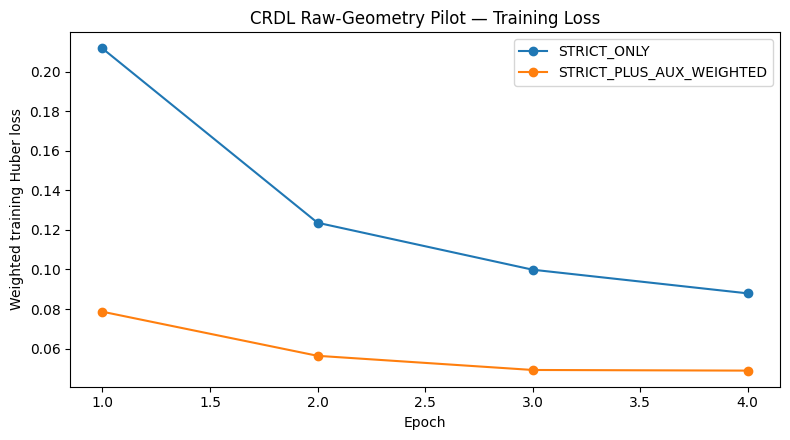


C3-12 SECTION 1 — TRAINED RAW-GEOMETRY ML PILOT
FIT group 0004 eligible samples: 273
FIT strict-only samples: 79
Inner development diagnostic strict samples: 5

New trained model checkpoints: 2
Checkpoint reload smoke tests: PASSED
Physical units verified: NO
Independent scene test completed: NO

SAVED TO:
/content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-12_section01_CRDL_raw_geometry_20261021T052628Z_125b5d


In [18]:
# ================================================================
# CRDL COMPONENT 3 — C3-12 SECTION 1
# FIRST TRAINED ROAD-RELATIVE GEOMETRY ML MODELS
#
# Model A: STRICT_ONLY
# Model B: STRICT_PLUS_AUX_WEIGHTED
#
# REAL PYTORCH TRAINING
# DEVELOPMENT-ONLY EXPERIMENT
# RAW AXIAL DEPTH UNITS — NOT CERTIFIED MILLIMETRES
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

import csv
import json
import hashlib
import random
import uuid
import importlib.util

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader


# ================================================================
# 1. RESTORE EXACT EXISTING PROJECT PATHS
# ================================================================

ROOT = Path('/content/drive/MyDrive')

PROJECT = (
    ROOT / 'crdl_experiments'
    / 'component3_fresh_v1'
)

SOURCE = (
    ROOT / 'manushi_research_data'
    / 'pothrgbd' / 'PData-main'
)

PILOT = (
    PROJECT / '04_geometry_targets'
    / 'C3-11_section01_RAW_target_pilot_'
      '20261021T043311Z_367db5'
)

LABEL_RUN = (
    PILOT /
    'C3-11_section04_weighted_feasibility_'
    '20261021T050356Z_383980'
)

ROLES = (
    PROJECT / '07_evaluation'
    / 'C3-09_physical_evidence_gate_v2_'
      '20261021T024723Z_ec15d662'
    / 'C3-10_section02_grouped_pilot_protocol_'
      '20261021T042524Z_735c9f'
    / 'PROVISIONAL_pilot_role_manifest.csv'
)

LABEL_MANIFEST = (
    LABEL_RUN / 'target_eligibility_manifest.csv'
)

LABEL_PROTOCOL = (
    LABEL_RUN / 'protocol.json'
)

assert all(
    p.is_file()
    for p in (
        LABEL_MANIFEST,
        LABEL_PROTOCOL,
        ROLES
    )
), "Previous training-target files are missing."


# ================================================================
# 2. SOURCE INTEGRITY HELPERS
# ================================================================

def read_csv(path):

    with path.open(
        newline='',
        encoding='utf-8'
    ) as f:

        return list(
            csv.DictReader(f)
        )


def sha256(path):

    h = hashlib.sha256()

    with path.open('rb') as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):

            h.update(block)

    return h.hexdigest()


# ================================================================
# 3. VERIFY THE COMPLETE TARGET MANIFEST
# ================================================================

labels = read_csv(LABEL_MANIFEST)

roles = {

    r['sample_id']: r

    for r in read_csv(ROLES)
}

assert len(labels) == 489
assert len(roles) == 996

assert len({

    r['sample_id']
    for r in labels

}) == 489

counts = Counter(

    r['tier']
    for r in labels
)

assert counts == {

    'STRICT': 84,

    'AUX_EXPERIMENTAL': 212,

    'REVIEW': 193

}, counts

print("=" * 70)
print("C3-12 SECTION 1 — TRAINED CRDL GEOMETRY PILOT")
print("=" * 70)

print("Complete training-target counts:", dict(counts))


# ================================================================
# 4. VERIFY ALL ELIGIBLE TARGET FILES
# ================================================================

eligible = []

for row in labels:

    if row['tier'] not in (
        'STRICT',
        'AUX_EXPERIMENTAL'
    ):
        continue

    sid = row['sample_id']

    role = roles[sid]

    assert role['pilot_role'] == 'PILOT_TRAIN'

    assert (
        role['capture_day_proxy']
        == '2025-03-05'
    )

    assert role['temporal_burst_proxy'] in (

        'POTHRGBD_TEMPORAL_0003',

        'POTHRGBD_TEMPORAL_0004'
    )

    relative = Path(
        row['target_relative_path']
    )

    assert not relative.is_absolute()

    assert len(relative.parts) == 2

    assert relative.parts[0] == 'targets'

    assert relative.name == (
        f'{sid}_axial_raw.npz'
    )

    target_path = LABEL_RUN / relative

    assert target_path.is_file()
    assert not target_path.is_symlink()

    assert sha256(target_path) == (
        row['target_sha256']
    ), f"Target integrity failure: {sid}"

    rgb_path = Path(
        role['rgb_path']
    )

    assert rgb_path.is_file()

    assert not rgb_path.is_symlink()

    assert rgb_path.parent.resolve() == (
        SOURCE / 'images'
    ).resolve()

    eligible.append({

        'sid': sid,

        'tier': row['tier'],

        'burst':
            role['temporal_burst_proxy'],

        'target': target_path,

        'rgb': rgb_path
    })


assert len(eligible) == 296

print("Verified eligible target files:", len(eligible))


# ================================================================
# 5. DEFINE INTERNAL TRAINING / DIAGNOSTIC GROUPS
# ================================================================

# Temporal group 0004 fits the networks.
# Temporal group 0003 is held out from fitting.
#
# These are within the provisional training role,
# NOT proven independent physical scenes.

splits = {

    'FIT': [

        r for r in eligible

        if r['burst']
        == 'POTHRGBD_TEMPORAL_0004'
    ],

    'INNER_DIAGNOSTIC': [

        r for r in eligible

        if r['burst']
        == 'POTHRGBD_TEMPORAL_0003'
    ]
}

fit_strict = [

    r for r in splits['FIT']

    if r['tier'] == 'STRICT'
]

inner_strict = [

    r for r in splits['INNER_DIAGNOSTIC']

    if r['tier'] == 'STRICT'
]

assert len(fit_strict) >= 10

assert len(splits['FIT']) >= 20

print("\nFIT GROUP 0004:")

print(dict(
    Counter(
        r['tier']
        for r in splits['FIT']
    )
))

print("\nINNER DIAGNOSTIC GROUP 0003:")

print(dict(
    Counter(
        r['tier']
        for r in splits['INNER_DIAGNOSTIC']
    )
))

print(
    "\nStrict inner-diagnostic samples:",
    len(inner_strict)
)


# ================================================================
# 6. TRAINING-ONLY TARGET NORMALIZATION
# ================================================================

# Calculate a single normalization scale
# from STRICT examples in the fitting group.
#
# No validation examples contribute.
# Scale remains in unverified RAW units.

strict_p95 = []

for item in fit_strict:

    with np.load(
        item['target'],
        allow_pickle=False
    ) as archive:

        y = np.asarray(
            archive['target_raw'],
            dtype=np.float32
        )

        valid = np.asarray(
            archive['loss_mask'],
            dtype=bool
        )

        assert y.shape == valid.shape == (
            192, 256
        )

        assert valid.sum() >= 60

        strict_p95.append(

            float(
                np.percentile(
                    y[valid],
                    95
                )
            )
        )


SCALE_RAW = max(

    1.0,

    float(
        np.median(strict_p95)
    )
)

print(
    "\nTraining-only normalization scale:",
    SCALE_RAW,
    "RAW units"
)


# ================================================================
# 7. INITIALIZE PYTORCH
# ================================================================

SEED = 20261021

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():

    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(

    'cuda'

    if torch.cuda.is_available()

    else 'cpu'
)

print("PyTorch:", torch.__version__)
print("Training device:", DEVICE)


# ================================================================
# 8. CREATE VERSIONED TRAINING OUTPUT DIRECTORY
# ================================================================

RUN = (
    PROJECT / '05_training_runs' /

    (

        'C3-12_section01_CRDL_raw_geometry_'

        + datetime.now(
            timezone.utc
        ).strftime('%Y%m%dT%H%M%SZ')

        + '_'

        + uuid.uuid4().hex[:6]
    )
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)

print("\nTraining output:", RUN)


# ================================================================
# 9. SAVE REPRODUCIBLE MODEL DEFINITION
# ================================================================

# The model source is saved as a real Python file.
# It can be imported later for backend inference.

MODEL_SOURCE = r'''
import numpy as np
import torch

from torch import nn
from torch.nn import functional as F

from PIL import Image


class ConvBlock(nn.Module):

    def __init__(self, cin, cout):

        super().__init__()

        self.layers = nn.Sequential(

            nn.Conv2d(
                cin, cout, 3, padding=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                cout, cout, 3, padding=1
            ),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        return self.layers(x)


class TinyCRDL(nn.Module):

    def __init__(self, base=16):

        super().__init__()

        self.e1 = ConvBlock(4, base)

        self.e2 = ConvBlock(base, 2 * base)

        self.mid = ConvBlock(
            2 * base, 4 * base
        )

        self.d2 = ConvBlock(
            6 * base, 2 * base
        )

        self.d1 = ConvBlock(
            3 * base, base
        )

        self.head = nn.Conv2d(
            base, 1, 1
        )

    def forward(self, x):

        a = self.e1(x)

        b = self.e2(
            F.avg_pool2d(a, 2)
        )

        mid = self.mid(
            F.avg_pool2d(b, 2)
        )

        up = F.interpolate(

            mid,

            size=b.shape[-2:],

            mode='bilinear',

            align_corners=False
        )

        c = self.d2(
            torch.cat(
                [b, up],
                dim=1
            )
        )

        up = F.interpolate(

            c,

            size=a.shape[-2:],

            mode='bilinear',

            align_corners=False
        )

        output = self.head(

            self.d1(
                torch.cat(
                    [a, up],
                    dim=1
                )
            )
        )

        # Nonnegative output only inside
        # the supplied pothole mask.
        return (
            F.softplus(output)
            * x[:, 3:4]
        )


def preprocess(
    rgb,
    mask,
    size_hw=(192, 256)
):

    h, w = size_hw

    if (
        rgb.ndim != 3
        or rgb.shape[-1] != 3
        or mask.shape != rgb.shape[:2]
    ):

        raise ValueError(
            'Expected aligned RGB and mask'
        )

    pic = np.asarray(

        Image.fromarray(

            np.asarray(
                rgb, dtype=np.uint8
            )

        ).resize(

            (w, h),

            Image.Resampling.BILINEAR
        ),

        dtype=np.float32
    ) / 255.0

    binary_mask = (
        np.asarray(mask) > 0
    ).astype(np.uint8) * 255

    mp = np.asarray(

        Image.fromarray(
            binary_mask
        ).resize(

            (w, h),

            Image.Resampling.NEAREST
        ),

        dtype=np.float32
    ) / 255.0

    x = np.concatenate(

        [

            pic.transpose(2, 0, 1),

            mp[None]
        ],

        axis=0
    )

    return torch.from_numpy(x).float()


def infer_raw(
    model,
    rgb,
    mask,
    scale_raw,
    device='cpu'
):

    x = preprocess(
        rgb, mask
    ).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():

        predicted = model(x).clamp(
            max=8
        )

        raw = (
            float(scale_raw)
            * torch.expm1(predicted)
        )

    return raw[0, 0].cpu().numpy()
'''

MODEL_FILE = (
    RUN / 'model_and_inference.py'
)

MODEL_FILE.write_text(

    MODEL_SOURCE,

    encoding='utf-8'
)

spec = importlib.util.spec_from_file_location(

    'crdl_c312_model',

    MODEL_FILE
)

mod = importlib.util.module_from_spec(
    spec
)

spec.loader.exec_module(mod)


# ================================================================
# 10. FREEZE TRAINING CONFIGURATION
# ================================================================

CONFIG = {

    'stage':
        'C3-12_SECTION01_TRAINED_RAW_GEOMETRY_PILOT',

    'architecture':
        'TinyCRDL_v1',

    'channels':
        'RGB 0..1 plus binary mask',

    'input_hw':
        [192, 256],

    'output':
        'log1p(positive road-relative AXIAL '
        'residual / SCALE_RAW) inside mask',

    'scale_raw_training_only':
        SCALE_RAW,

    'raw_units':
        'UNVERIFIED_POTHRGBD_DEPTH_UNITS',

    'verified_depth_mm':
        False,

    'road_normal_physical_depth':
        False,

    'physical_area_volume_available':
        False,

    'fit_burst':
        'POTHRGBD_TEMPORAL_0004',

    'inner_diagnostic_burst':
        'POTHRGBD_TEMPORAL_0003',

    'inner_diagnostic_is_scene_independent':
        False,

    'cross_day_accessed':
        False,

    'epochs':
        8 if DEVICE.type == 'cuda' else 4,

    'batch_size':
        8 if DEVICE.type == 'cuda' else 4,

    'optimizer':
        'AdamW',

    'learning_rate':
        0.001,

    'seed':
        SEED,

    'label_protocol_sha256':
        sha256(LABEL_PROTOCOL),

    'label_manifest_sha256':
        sha256(LABEL_MANIFEST),

    'role_manifest_sha256':
        sha256(ROLES),

    'weight_conditions': [

        'STRICT_ONLY',

        'STRICT_PLUS_AUX_WEIGHTED'
    ],

    'evaluation':
        'Internal development diagnostic only; '
        'no independent test'
}

(
    RUN / 'training_config.json'
).write_text(

    json.dumps(
        CONFIG,
        indent=2
    ),

    encoding='utf-8'
)


# ================================================================
# 11. LOAD AND VERIFY TRAINING TENSORS
# ================================================================

# Cache source images and targets in RAM
# to avoid repeated Google Drive reads.

cache = {}

for item in eligible:

    with np.load(

        item['target'],

        allow_pickle=False

    ) as archive:

        y = np.asarray(

            archive['target_raw'],

            dtype=np.float32
        )

        m = np.asarray(

            archive['loss_mask'],

            dtype=np.float32
        )

        weight = np.asarray(

            archive['loss_weight'],

            dtype=np.float32
        )

        pm = np.asarray(

            archive['pothole_mask'],

            dtype=np.uint8
        )

        assert (
            y.shape
            == m.shape
            == weight.shape
            == pm.shape
            == (192, 256)
        )

        assert np.isfinite(y).all()

        assert (y >= 0).all()

        assert np.isfinite(weight).all()

        assert (weight >= 0).all()

        assert np.all(
            weight[m == 0] == 0
        )

        assert np.all(
            m <= pm
        )

        assert np.count_nonzero(m) >= 60

        if item['tier'] == 'STRICT':

            assert np.allclose(
                weight[m > 0],
                1.0
            )

        else:

            assert (
                0
                < float(weight[m > 0].min())
                <= 0.5
            )

    with Image.open(
        item['rgb']
    ) as im:

        rgb = np.asarray(

            im.convert('RGB').resize(

                (256, 192),

                Image.Resampling.BILINEAR
            ),

            dtype=np.uint8
        )

    x = np.concatenate(

        [

            rgb.transpose(
                2, 0, 1
            ).astype(np.float32) / 255.0,

            pm[None].astype(np.float32)
        ],

        axis=0
    )

    # Compress target dynamic range for
    # stable neural-network regression.
    transformed_y = np.log1p(
        y / SCALE_RAW
    )

    cache[item['sid']] = (

        torch.from_numpy(x),

        torch.from_numpy(
            transformed_y[None]
        ),

        torch.from_numpy(
            weight[None]
        ),

        torch.from_numpy(
            y[None]
        ),

        torch.from_numpy(
            m[None]
        )
    )


print(
    "\nPreloaded supervised examples:",
    len(cache)
)


# ================================================================
# 12. PYTORCH DATASET
# ================================================================

class CachedData(Dataset):

    def __init__(self, items):

        self.items = items

    def __len__(self):

        return len(self.items)

    def __getitem__(self, index):

        sid = self.items[index]['sid']

        return cache[sid]


# ================================================================
# 13. ROBUST RELIABILITY-WEIGHTED LOSS
# ================================================================

def weighted_loss(
    prediction,
    reference,
    weight
):

    huber = torch.nn.functional.smooth_l1_loss(

        prediction,

        reference,

        reduction='none',

        beta=0.25
    )

    valid = (
        weight > 0
    ).float()

    # Divide by valid-pixel count,
    # NOT by sum of weights.
    #
    # Otherwise an auxiliary sample's
    # uniform reliability factor cancels.

    per_image = (

        (huber * weight)
        .flatten(1)
        .sum(1)

        /

        valid.flatten(1)
        .sum(1)
        .clamp(min=1)
    )

    return per_image.mean()


# ================================================================
# 14. TRAIN BOTH EXPERIMENTAL CONDITIONS
# ================================================================

history = []

conditions = [

    (
        'STRICT_ONLY',

        fit_strict
    ),

    (
        'STRICT_PLUS_AUX_WEIGHTED',

        splits['FIT']
    )
]

for mode, items in conditions:

    # Identical initialization seed.
    torch.manual_seed(SEED)

    net = mod.TinyCRDL(
        base=16
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(

        net.parameters(),

        lr=CONFIG['learning_rate']
    )

    loader = DataLoader(

        CachedData(items),

        batch_size=CONFIG['batch_size'],

        shuffle=True,

        num_workers=0,

        generator=torch.Generator().manual_seed(
            SEED
        )
    )

    print("\n" + "-" * 65)

    print(
        "TRAINING:",
        mode,
        "| samples:",
        len(items)
    )

    for epoch in range(
        1,
        CONFIG['epochs'] + 1
    ):

        net.train()

        loss_sum = 0.0
        n_seen = 0

        for x, y, weight, raw, mask in loader:

            x = x.to(DEVICE)

            y = y.to(DEVICE)

            weight = weight.to(DEVICE)

            optimizer.zero_grad(
                set_to_none=True
            )

            predicted = net(x)

            loss = weighted_loss(

                predicted,

                y,

                weight
            )

            if not torch.isfinite(loss):

                raise RuntimeError(
                    'Non-finite training loss'
                )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(

                net.parameters(),

                max_norm=5.0
            )

            optimizer.step()

            loss_sum += (
                float(loss.item()) * len(x)
            )

            n_seen += len(x)

        record = {

            'mode': mode,

            'epoch': epoch,

            'train_weighted_huber':
                loss_sum / n_seen,

            'inner_strict_raw_mae':
                None,

            'inner_strict_n':
                len(inner_strict)
        }

        # ----------------------------------------
        # Inner development diagnostic
        # ----------------------------------------

        if inner_strict:

            net.eval()

            errors = []

            inner_loader = DataLoader(

                CachedData(inner_strict),

                batch_size=CONFIG['batch_size'],

                shuffle=False
            )

            with torch.no_grad():

                for (
                    x,
                    y,
                    weight,
                    raw,
                    mask
                ) in inner_loader:

                    predicted = net(

                        x.to(DEVICE)

                    ).clamp(max=8)

                    predicted_raw = (

                        SCALE_RAW

                        * torch.expm1(
                            predicted
                        ).cpu()
                    )

                    error = (

                        predicted_raw - raw
                    ).abs()

                    for j in range(len(x)):

                        valid = (
                            mask[j] > 0
                        )

                        errors.append(

                            float(

                                error[j][valid]
                                .mean()
                            )
                        )

            record['inner_strict_raw_mae'] = (

                float(
                    np.mean(errors)
                )
            )

        history.append(record)

        print(

            f'Epoch {epoch:02d} | '

            f'train loss='
            f'{record["train_weighted_huber"]:.5f} | '

            f'inner RAW MAE='
            f'{record["inner_strict_raw_mae"]}'
        )


    # ============================================================
    # 15. SAVE THE ACTUAL TRAINED CHECKPOINT
    # ============================================================

    checkpoint = (

        RUN /

        (mode.lower() + '_last.pt')
    )

    torch.save(

        {

            'state_dict':
                net.state_dict(),

            'model_config': {

                'base': 16,

                'in_channels': 4,

                'input_hw': [192, 256]
            },

            'normalization_scale_raw':
                SCALE_RAW,

            'training_condition':
                mode,

            'epoch':
                CONFIG['epochs'],

            'physical_metric_claim':
                False,

            'label_protocol_sha256':
                CONFIG['label_protocol_sha256']
        },

        checkpoint
    )


    # ============================================================
    # 16. FRESH CHECKPOINT RELOAD AND SMOKE TEST
    # ============================================================

    loaded = mod.TinyCRDL(
        base=16
    ).to(DEVICE)

    checkpoint_data = torch.load(

        checkpoint,

        map_location=DEVICE,

        weights_only=True
    )

    loaded.load_state_dict(

        checkpoint_data['state_dict']
    )

    loaded.eval()
    net.eval()

    source_x, _, _, _, _ = cache[
        items[0]['sid']
    ]

    with torch.no_grad():

        original_output = net(

            source_x[None].to(DEVICE)
        )

        reloaded_output = loaded(

            source_x[None].to(DEVICE)
        )

    max_difference = float(

        (
            original_output
            - reloaded_output
        ).abs().max()
    )

    assert max_difference < 1e-6

    assert torch.isfinite(
        reloaded_output
    ).all()

    assert reloaded_output.shape == (
        1, 1, 192, 256
    )

    smoke = {

        'checkpoint_reloaded':
            True,

        'output_hw':
            [192, 256],

        'max_reloaded_difference':
            max_difference,

        'physical_metric_fields_null':
            True,

        'tested_sample':
            items[0]['sid']
    }

    (
        RUN /
        (mode.lower() + '_smoke.json')
    ).write_text(

        json.dumps(
            smoke,
            indent=2
        ),

        encoding='utf-8'
    )

    print(
        "Checkpoint saved and reload test PASSED:",
        checkpoint.name
    )


# ================================================================
# 17. SAVE TRAINING HISTORY
# ================================================================

with (
    RUN / 'training_history.csv'
).open(
    'w',
    newline='',
    encoding='utf-8'
) as f:

    writer = csv.DictWriter(

        f,

        fieldnames=list(history[0])
    )

    writer.writeheader()

    writer.writerows(history)


# ================================================================
# 18. PLOT LEARNING CURVES
# ================================================================

fig, ax = plt.subplots(
    figsize=(8, 4.5)
)

for condition in CONFIG['weight_conditions']:

    selected_history = [

        r for r in history

        if r['mode'] == condition
    ]

    ax.plot(

        [
            r['epoch']
            for r in selected_history
        ],

        [
            r['train_weighted_huber']
            for r in selected_history
        ],

        marker='o',

        label=condition
    )

ax.set_xlabel('Epoch')

ax.set_ylabel(
    'Weighted training Huber loss'
)

ax.set_title(
    'CRDL Raw-Geometry Pilot — Training Loss'
)

ax.legend()

fig.tight_layout()

fig.savefig(

    RUN / 'training_curves.png',

    dpi=150
)

plt.show()
plt.close(fig)


# ================================================================
# 19. PREPARE BACKEND CONTRACT
# ================================================================

API = {

    'schema_version':
        'crdl-c3/0.3-raw-pilot',

    'inputs': {

        'rgb':
            'HxWx3 uint8 RGB ROI',

        'pothole_mask':
            'HxW bool or uint8 aligned with ROI'
    },

    'outputs': {

        'raw_axial_depression_map':
            '192x256 RAW_UNVERIFIED sensor units',

        'depth_d95_mm':
            None,

        'depth_max_mm':
            None,

        'area_m2':
            None,

        'volume_m3':
            None,

        'severity_physical':
            None,

        'reliability_status':
            'UNVERIFIED_SCALE_AND_SCENE_VALIDATION'
    },

    'training_evidence':
        'Development pilot; no independent '
        'physical measurement validation'
}

(
    RUN / 'api_contract.json'
).write_text(

    json.dumps(
        API,
        indent=2
    ),

    encoding='utf-8'
)


# ================================================================
# 20. SAVE CALIBRATION AND SEVERITY STATUS
# ================================================================

status = {

    'metric_conversion':
        'UNVERIFIED',

    'metric_depth':
        False,

    'road_normal_depth':
        False,

    'severity_physical':
        'NOT_ENABLED',

    'crack_metric_length':
        'NOT_ENABLED',

    'reliability_rule':
        'ABSTAIN_FROM_PHYSICAL_MEASUREMENTS',

    'trained_component':
        'RAW_AXIAL_DEPRESSION_PILOT_ONLY'
}

(
    RUN / 'calibration_and_severity_status.json'
).write_text(

    json.dumps(
        status,
        indent=2
    ),

    encoding='utf-8'
)


# ================================================================
# 21. SHA-256 ARTIFACT MANIFEST
# ================================================================

receipts = []

for path in sorted(
    RUN.iterdir()
):

    if (

        path.is_file()

        and path.name
        != 'sha256_manifest.json'
    ):

        receipts.append({

            'file':
                path.name,

            'bytes':
                path.stat().st_size,

            'sha256':
                sha256(path)
        })

(
    RUN / 'sha256_manifest.json'
).write_text(

    json.dumps(
        receipts,
        indent=2
    ),

    encoding='utf-8'
)


# ================================================================
# 22. FINAL TRAINING MILESTONE SUMMARY
# ================================================================

print("\n" + "=" * 70)

print(
    "C3-12 SECTION 1 — TRAINED RAW-GEOMETRY ML PILOT"
)

print("=" * 70)

print(
    "FIT group 0004 eligible samples:",
    len(splits['FIT'])
)

print(
    "FIT strict-only samples:",
    len(fit_strict)
)

print(
    "Inner development diagnostic strict samples:",
    len(inner_strict)
)

print(
    "\nNew trained model checkpoints:",
    2
)

print(
    "Checkpoint reload smoke tests:",
    "PASSED"
)

print(
    "Physical units verified:",
    "NO"
)

print(
    "Independent scene test completed:",
    "NO"
)

print("\nSAVED TO:")
print(RUN)

print("=" * 70)

C3-12 SECTION 2 — COMMON MODEL EVALUATION
Training experiment: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-12_section01_CRDL_raw_geometry_20261021T052628Z_125b5d
Normalization scale: 40.8135871887207 RAW
Original source integrity: PASS

Strict fitting samples: 79
Common diagnostic samples: 5
Evaluation output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-12_section02_common_raw_diagnostic_20261021T054039Z_404ec2

Training-derived constant baseline: 26.3062 RAW units
Loaded checkpoint: strict_only_last.pt
Loaded checkpoint: strict_plus_aux_weighted_last.pt
Evaluated common diagnostic sample: 20250305_073146
Evaluated common diagnostic sample: 20250305_073411
Evaluated common diagnostic sample: 20250305_080238
Evaluated common diagnostic sample: 20250305_082854
Evaluated common diagnostic sample: 20250305_084055


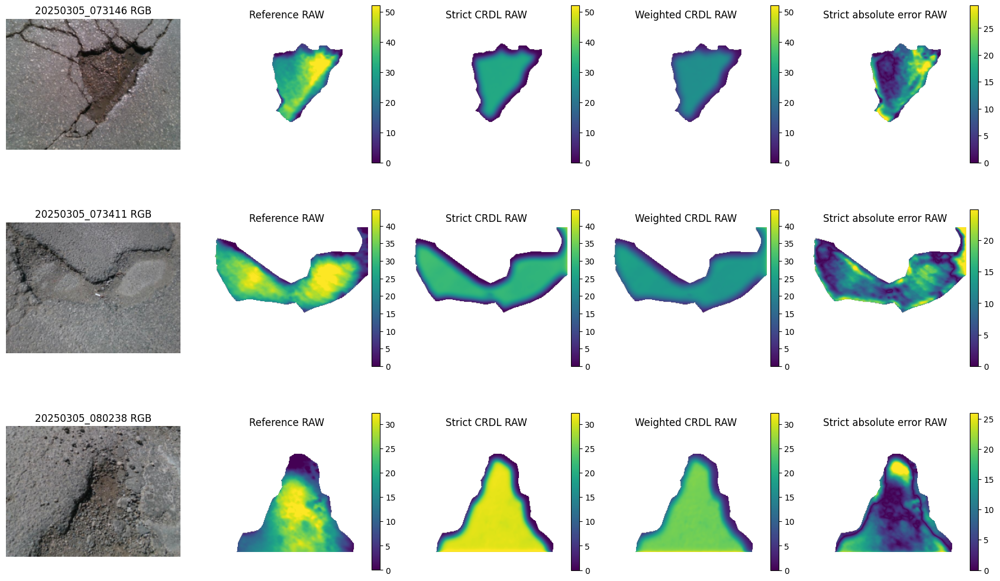


C3-12 SECTION 2 — FROZEN COMMON DIAGNOSTIC
Internal strict diagnostic examples: 5
Train strict baseline examples: 79
Train-only constant baseline RAW: 26.3062

COMMON DIAGNOSTIC COMPARISON
ZERO: MAE=25.0766 RAW | RMSE=27.0600 | D95 abs error=38.8559
TRAIN_CONSTANT: MAE=8.6523 RAW | RMSE=11.1156 | D95 abs error=12.5496
STRICT_ONLY: MAE=7.8865 RAW | RMSE=9.6683 | D95 abs error=8.5863
STRICT_PLUS_AUX_WEIGHTED: MAE=7.9255 RAW | RMSE=9.5121 | D95 abs error=13.4286

Model checkpoints unchanged: YES
Independent test or metric validation: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-12_section02_common_raw_diagnostic_20261021T054039Z_404ec2


In [19]:
# ================================================================
# CRDL COMPONENT 3 — C3-12 SECTION 2
# FROZEN MODEL COMPARISON ON COMMON DIAGNOSTIC CASES
#
# METHODS:
#   1. ZERO baseline
#   2. Training-derived constant baseline
#   3. Trained STRICT_ONLY CRDL
#   4. Trained STRICT_PLUS_AUX_WEIGHTED CRDL
#
# EVALUATION:
#   5 strict examples from temporal group 0003
#
# NO RETRAINING
# NO PROTECTED EVALUATION DATA
# NO PHYSICAL MILLIMETRE CLAIMS
# ================================================================

from pathlib import Path
from datetime import datetime, timezone

import csv
import json
import hashlib
import uuid
import importlib.util

import numpy as np
import torch
import matplotlib.pyplot as plt

from PIL import Image


# ================================================================
# 1. RESTORE EXACT PROJECT PATHS
# ================================================================

ROOT = Path('/content/drive/MyDrive')

PROJECT = (
    ROOT /
    'crdl_experiments' /
    'component3_fresh_v1'
)

SOURCE = (
    ROOT /
    'manushi_research_data' /
    'pothrgbd' /
    'PData-main'
)

LABEL_RUN = (
    PROJECT /
    '04_geometry_targets' /
    'C3-11_section01_RAW_target_pilot_'
    '20261021T043311Z_367db5' /
    'C3-11_section04_weighted_feasibility_'
    '20261021T050356Z_383980'
)

TRAIN_RUN = (
    PROJECT /
    '05_training_runs' /
    'C3-12_section01_CRDL_raw_geometry_'
    '20261021T052628Z_125b5d'
)

ROLE_FILE = (
    PROJECT /
    '07_evaluation' /
    'C3-09_physical_evidence_gate_v2_'
    '20261021T024723Z_ec15d662' /
    'C3-10_section02_grouped_pilot_protocol_'
    '20261021T042524Z_735c9f' /
    'PROVISIONAL_pilot_role_manifest.csv'
)

LABEL_FILE = (
    LABEL_RUN /
    'target_eligibility_manifest.csv'
)

PROTO_FILE = (
    LABEL_RUN /
    'protocol.json'
)

CONFIG_FILE = (
    TRAIN_RUN /
    'training_config.json'
)

MODEL_FILE = (
    TRAIN_RUN /
    'model_and_inference.py'
)

for path in [
    ROLE_FILE,
    LABEL_FILE,
    PROTO_FILE,
    CONFIG_FILE,
    MODEL_FILE
]:
    assert path.is_file(), (
        f'Missing prerequisite: {path}'
    )


# ================================================================
# 2. REPRODUCIBILITY HELPERS
# ================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, 'rb') as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):
            h.update(block)

    return h.hexdigest()


def read_csv(path):

    with open(
        path,
        newline='',
        encoding='utf-8'
    ) as f:

        return list(
            csv.DictReader(f)
        )


# ================================================================
# 3. VERIFY TRAINING CONFIGURATION AND SOURCES
# ================================================================

config = json.loads(
    CONFIG_FILE.read_text(
        encoding='utf-8'
    )
)

assert (
    config['label_manifest_sha256']
    == sha256_file(LABEL_FILE)
)

assert (
    config['label_protocol_sha256']
    == sha256_file(PROTO_FILE)
)

assert (
    config['role_manifest_sha256']
    == sha256_file(ROLE_FILE)
)

assert (
    config['architecture']
    == 'TinyCRDL_v1'
)

assert (
    config['verified_depth_mm']
    is False
)

SCALE_RAW = float(
    config['scale_raw_training_only']
)

assert np.isfinite(SCALE_RAW)
assert SCALE_RAW > 0

print("=" * 70)
print("C3-12 SECTION 2 — COMMON MODEL EVALUATION")
print("=" * 70)

print("Training experiment:", TRAIN_RUN)
print("Normalization scale:", SCALE_RAW, "RAW")
print("Original source integrity: PASS")


# ================================================================
# 4. RECOVER STRICT TRAIN AND DIAGNOSTIC EXAMPLES
# ================================================================

labels = read_csv(LABEL_FILE)

roles = {

    row['sample_id']: row

    for row in read_csv(ROLE_FILE)
}

assert len(labels) == 489
assert len(roles) == 996

fit = sorted(

    [

        row for row in labels

        if (
            row['tier'] == 'STRICT'

            and roles[
                row['sample_id']
            ]['temporal_burst_proxy']
            == 'POTHRGBD_TEMPORAL_0004'
        )
    ],

    key=lambda row: row['sample_id']
)

inner = sorted(

    [

        row for row in labels

        if (
            row['tier'] == 'STRICT'

            and roles[
                row['sample_id']
            ]['temporal_burst_proxy']
            == 'POTHRGBD_TEMPORAL_0003'
        )
    ],

    key=lambda row: row['sample_id']
)

assert len(fit) == 79
assert len(inner) == 5

assert all(

    roles[row['sample_id']]['pilot_role']
    == 'PILOT_TRAIN'

    for row in fit + inner
)

print("\nStrict fitting samples:", len(fit))
print("Common diagnostic samples:", len(inner))


# ================================================================
# 5. CREATE VERSIONED EVALUATION OUTPUT FOLDER
# ================================================================

EVAL = (

    PROJECT /
    '07_evaluation' /
    (

        'C3-12_section02_common_raw_diagnostic_'

        + datetime.now(
            timezone.utc
        ).strftime('%Y%m%dT%H%M%SZ_')

        + uuid.uuid4().hex[:6]
    )
)

EVAL.mkdir(
    parents=True,
    exist_ok=False
)

print("Evaluation output:", EVAL)


# ================================================================
# 6. VERIFIED TARGET LOADER
# ================================================================

def load_target(row):

    sid = row['sample_id']

    relative = Path(
        row['target_relative_path']
    )

    assert not relative.is_absolute()
    assert len(relative.parts) == 2
    assert relative.parts[0] == 'targets'

    assert relative.name == (
        f'{sid}_axial_raw.npz'
    )

    path = LABEL_RUN / relative

    assert path.is_file()
    assert not path.is_symlink()

    assert (
        sha256_file(path)
        == row['target_sha256']
    ), f'Target hash mismatch: {sid}'

    with np.load(
        path,
        allow_pickle=False
    ) as archive:

        target = np.array(

            archive['target_raw'],

            dtype=np.float32
        )

        valid = np.array(

            archive['loss_mask'],

            dtype=bool
        )

        pothole_mask = np.array(

            archive['pothole_mask'],

            dtype=bool
        )

    assert (
        target.shape
        == valid.shape
        == pothole_mask.shape
        == (192, 256)
    )

    assert valid.sum() >= 60

    assert np.isfinite(target).all()
    assert (target >= 0).all()

    assert np.all(
        ~valid | pothole_mask
    )

    return target, valid, pothole_mask


# ================================================================
# 7. BUILD TRAINING-ONLY CONSTANT BASELINE
# ================================================================

# A deliberately simple non-ML baseline.
#
# Calculate each fitting image's median depression.
# Then take the median of those 79 values.
#
# Equal fitting-scene contribution.
# Never use diagnostic targets to fit this baseline.

train_medians = []

for row in fit:

    target, valid, _ = load_target(row)

    train_medians.append(

        float(
            np.median(
                target[valid]
            )
        )
    )

CONSTANT_RAW = float(
    np.median(train_medians)
)

assert CONSTANT_RAW >= 0

print(
    "\nTraining-derived constant baseline:",
    round(CONSTANT_RAW, 4),
    "RAW units"
)


# ================================================================
# 8. IMPORT ACTUAL SAVED MODEL IMPLEMENTATION
# ================================================================

spec = importlib.util.spec_from_file_location(

    'c312_frozen_model',

    MODEL_FILE
)

model_module = importlib.util.module_from_spec(
    spec
)

spec.loader.exec_module(
    model_module
)


# ================================================================
# 9. COLD-LOAD BOTH TRAINED CHECKPOINTS
# ================================================================

CHECKPOINTS = {

    'STRICT_ONLY':
        'strict_only_last.pt',

    'STRICT_PLUS_AUX_WEIGHTED':
        'strict_plus_aux_weighted_last.pt'
}

models = {}
checkpoint_hashes = {}

for name, filename in CHECKPOINTS.items():

    path = TRAIN_RUN / filename

    assert path.is_file()

    checkpoint_hashes[name] = sha256_file(
        path
    )

    checkpoint = torch.load(

        path,

        map_location='cpu',

        weights_only=True
    )

    assert (
        checkpoint['training_condition']
        == name
    )

    assert (
        checkpoint['physical_metric_claim']
        is False
    )

    assert np.isclose(

        checkpoint[
            'normalization_scale_raw'
        ],

        SCALE_RAW,

        rtol=0,
        atol=1e-7
    )

    model = model_module.TinyCRDL(

        base=checkpoint[
            'model_config'
        ]['base']
    ).cpu()

    model.load_state_dict(

        checkpoint['state_dict'],

        strict=True
    )

    model.eval()

    # Check that an empty defect mask
    # produces zero geometry output.
    with torch.inference_mode():

        empty = torch.zeros(
            1, 4, 192, 256
        )

        assert (
            torch.count_nonzero(
                model(empty)
            ) == 0
        )

    models[name] = model

    print(
        'Loaded checkpoint:',
        filename
    )


# ================================================================
# 10. DEFINE COMMON GEOMETRY EVALUATION METRICS
# ================================================================

def calculate_metrics(prediction, truth, valid):

    p = prediction[valid].astype(float)

    t = truth[valid].astype(float)

    assert p.size > 0
    assert np.isfinite(p).all()
    assert (p >= 0).all()

    difference = p - t

    mae = float(
        np.mean(
            np.abs(difference)
        )
    )

    rmse = float(
        np.sqrt(
            np.mean(difference ** 2)
        )
    )

    d95_predicted = float(
        np.percentile(p, 95)
    )

    d95_reference = float(
        np.percentile(t, 95)
    )

    return {

        'mae_raw': mae,

        'rmse_raw': rmse,

        'd95_abs_error_raw':
            abs(
                d95_predicted
                - d95_reference
            ),

        'bias_raw':
            float(
                np.mean(difference)
            )
    }


# ================================================================
# 11. EVALUATE ALL METHODS ON IDENTICAL VALID PIXELS
# ================================================================

per_image = []

preview = []

for row in inner:

    sid = row['sample_id']

    truth, valid, pothole_mask = (
        load_target(row)
    )

    rgb_path = Path(
        roles[sid]['rgb_path']
    )

    assert rgb_path.is_file()
    assert not rgb_path.is_symlink()

    assert rgb_path.parent.resolve() == (
        SOURCE / 'images'
    ).resolve()

    with Image.open(rgb_path) as image:

        rgb = np.asarray(

            image.convert('RGB').resize(

                (256, 192),

                Image.Resampling.BILINEAR
            ),

            dtype=np.uint8
        )

    # Same preprocessing used in C3-12 training.
    x = np.concatenate(

        [

            rgb.transpose(
                2, 0, 1
            ).astype(np.float32) / 255.0,

            pothole_mask[
                None
            ].astype(np.float32)
        ],

        axis=0
    )

    # -------------------------------------------
    # Non-ML baselines
    # -------------------------------------------

    predictions = {

        'ZERO':
            np.zeros_like(truth),

        'TRAIN_CONSTANT':
            pothole_mask.astype(np.float32)
            * CONSTANT_RAW
    }

    # -------------------------------------------
    # Frozen neural-network predictions
    # -------------------------------------------

    with torch.inference_mode():

        input_tensor = torch.from_numpy(
            x
        )[None]

        for name, model in models.items():

            output = model(

                input_tensor

            ).clamp(max=8)

            predicted_raw = (

                SCALE_RAW

                * torch.expm1(
                    output
                )
            )[0, 0].numpy()

            predictions[name] = predicted_raw

    # -------------------------------------------
    # Common evaluation
    # -------------------------------------------

    for method, prediction in predictions.items():

        metrics = calculate_metrics(

            prediction,
            truth,
            valid
        )

        per_image.append({

            'sample_id':
                sid,

            'method':
                method,

            'valid_pixels':
                int(valid.sum()),

            **metrics
        })

    # Retain three sample previews.
    if len(preview) < 3:

        preview.append((

            sid,
            rgb,
            truth,
            valid,
            predictions
        ))

    print(
        'Evaluated common diagnostic sample:',
        sid
    )


# ================================================================
# 12. AGGREGATE RESULTS WITH EQUAL SCENE WEIGHT
# ================================================================

summary = {}

for name in [

    'ZERO',

    'TRAIN_CONSTANT',

    'STRICT_ONLY',

    'STRICT_PLUS_AUX_WEIGHTED'
]:

    subset = [

        row for row in per_image

        if row['method'] == name
    ]

    assert len(subset) == 5

    summary[name] = {

        'n_scenes':
            len(subset),

        'mean_scene_mae_raw':

            float(
                np.mean([

                    row['mae_raw']

                    for row in subset
                ])
            ),

        'median_scene_mae_raw':

            float(
                np.median([

                    row['mae_raw']

                    for row in subset
                ])
            ),

        'mean_scene_rmse_raw':

            float(
                np.mean([

                    row['rmse_raw']

                    for row in subset
                ])
            ),

        'mean_scene_d95_abs_error_raw':

            float(
                np.mean([

                    row['d95_abs_error_raw']

                    for row in subset
                ])
            )
    }


# ================================================================
# 13. SAVE COMPLETE PER-IMAGE EVALUATION
# ================================================================

with (
    EVAL / 'per_image_common_diagnostic.csv'
).open(
    'w',
    newline='',
    encoding='utf-8'
) as f:

    writer = csv.DictWriter(

        f,

        fieldnames=list(
            per_image[0]
        )
    )

    writer.writeheader()

    writer.writerows(
        per_image
    )


# ================================================================
# 14. SAVE SCIENTIFIC EVALUATION SUMMARY
# ================================================================

summary_document = {

    'stage':
        'C3-12_SECTION02',

    'n_inner_strict':
        len(inner),

    'fit_strict_count':
        len(fit),

    'fit_only_baseline_constant_RAW':
        CONSTANT_RAW,

    'models':
        summary,

    'source_checkpoint_sha256':
        checkpoint_hashes,

    'normalization_raw_scale':
        SCALE_RAW,

    'scene_independence_verified':
        False,

    'physical_mm_certified':
        False,

    'diagnostic_group_previously_inspected':
        True,

    'protected_0002_and_cross_day_accessed':
        False,

    'training_performed':
        False,

    'interpretation':

        'Common five-case internal diagnostic. '
        'Cannot establish model superiority or '
        'physical measurement accuracy.'
}

(
    EVAL / 'common_diagnostic_summary.json'
).write_text(

    json.dumps(
        summary_document,
        indent=2
    ),

    encoding='utf-8'
)


# ================================================================
# 15. VISUALIZE ACTUAL MODEL PREDICTIONS
# ================================================================

if preview:

    fig, axes = plt.subplots(

        len(preview),

        5,

        figsize=(
            17,
            3.6 * len(preview)
        ),

        squeeze=False
    )

    for i, (
        sid,
        rgb,
        truth,
        valid,
        predictions
    ) in enumerate(preview):

        axes[i, 0].imshow(rgb)

        axes[i, 0].set_title(
            sid + ' RGB'
        )

        series = [

            (
                'Reference RAW',
                truth
            ),

            (
                'Strict CRDL RAW',
                predictions['STRICT_ONLY']
            ),

            (
                'Weighted CRDL RAW',
                predictions[
                    'STRICT_PLUS_AUX_WEIGHTED'
                ]
            ),

            (
                'Strict absolute error RAW',

                np.abs(

                    predictions['STRICT_ONLY']
                    - truth
                )
            )
        ]

        # Shared display scale across the reference
        # and two predicted geometry maps.
        all_values = np.concatenate([

            truth[valid],

            predictions[
                'STRICT_ONLY'
            ][valid],

            predictions[
                'STRICT_PLUS_AUX_WEIGHTED'
            ][valid]
        ])

        common_hi = max(

            1.0,

            float(
                np.percentile(
                    all_values,
                    98
                )
            )
        )

        for j, (title, array) in enumerate(
            series,
            start=1
        ):

            vmax = (

                common_hi

                if j <= 3

                else max(

                    1.0,

                    float(

                        np.percentile(
                            array[valid],
                            98
                        )
                    )
                )
            )

            plotted = axes[i, j].imshow(

                np.ma.masked_where(

                    ~valid,

                    array
                ),

                cmap='viridis',

                vmin=0,
                vmax=vmax
            )

            axes[i, j].set_title(title)

            fig.colorbar(

                plotted,

                ax=axes[i, j],

                fraction=0.045,
                pad=0.02
            )

        for ax in axes[i]:
            ax.axis('off')

    fig.tight_layout()

    fig.savefig(

        EVAL /
        'common_diagnostic_predictions.png',

        dpi=140,

        bbox_inches='tight'
    )

    plt.show()

    plt.close(fig)


# ================================================================
# 16. SAVE ARTIFACT CHECKSUMS
# ================================================================

receipts = [

    {

        'file':
            path.name,

        'sha256':
            sha256_file(path),

        'bytes':
            path.stat().st_size
    }

    for path in sorted(
        EVAL.iterdir()
    )

    if (
        path.is_file()

        and path.name != 'sha256_manifest.json'
    )
]

(
    EVAL / 'sha256_manifest.json'
).write_text(

    json.dumps(
        receipts,
        indent=2
    ),

    encoding='utf-8'
)

assert all(

    sha256_file(
        EVAL / record['file']
    ) == record['sha256']

    for record in receipts
)

# Confirm evaluation did not alter checkpoints.
assert all(

    sha256_file(

        TRAIN_RUN /
        CHECKPOINTS[name]
    ) == checkpoint_hashes[name]

    for name in CHECKPOINTS
)


# ================================================================
# 17. PRINT FINAL COMPARATIVE RESULTS
# ================================================================

print("\n" + "=" * 70)

print(
    "C3-12 SECTION 2 — FROZEN COMMON DIAGNOSTIC"
)

print("=" * 70)

print(
    "Internal strict diagnostic examples:",
    len(inner)
)

print(
    "Train strict baseline examples:",
    len(fit)
)

print(
    "Train-only constant baseline RAW:",
    round(CONSTANT_RAW, 4)
)

print("\nCOMMON DIAGNOSTIC COMPARISON")

for name, values in summary.items():

    print(

        f"{name}: "

        f"MAE="
        f"{values['mean_scene_mae_raw']:.4f} RAW | "

        f"RMSE="
        f"{values['mean_scene_rmse_raw']:.4f} | "

        f"D95 abs error="
        f"{values['mean_scene_d95_abs_error_raw']:.4f}"
    )

print("\nModel checkpoints unchanged: YES")

print("Independent test or metric validation: NO")

print("\nSaved:", EVAL)

print("=" * 70)

C3-12 SECTION 3 — MASK SHAPE BASELINE
Fitting strict examples: 79
Training-derived constant: 26.306248664855957
Mask-distance coefficients: [11.43450442 39.74112132]
Raw units are NOT verified millimetres.


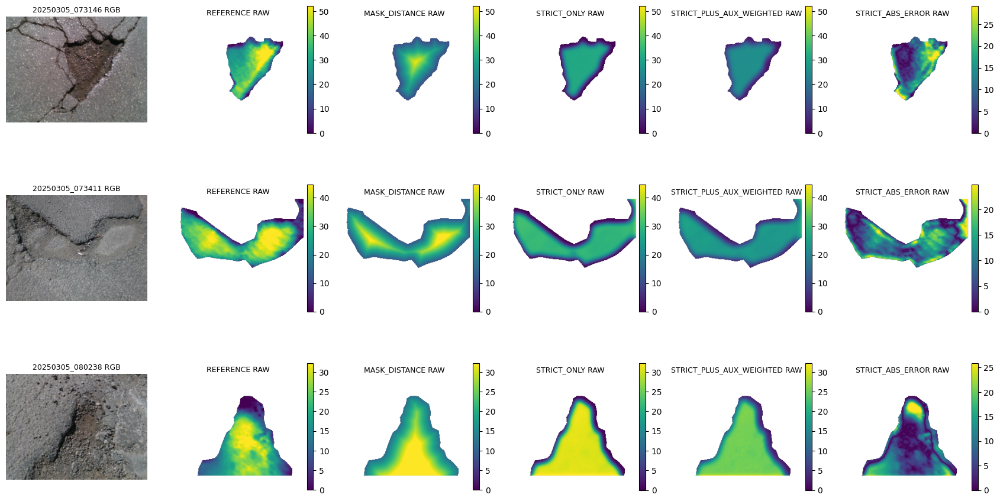


C3-12 SECTION 3 — MASK SHAPE / RGB DEPENDENCY AUDIT
Frozen checkpoint models: 2 | common internal diagnostic cases: 5
Fit-only mask distance coefficients: [11.43450442 39.74112132]

COMMON DIAGNOSTIC COMPARISON
ZERO                        | MAE=25.077 | D95 error=38.856 | mean spatial STD=0.000
TRAIN_CONSTANT              | MAE=8.652 | D95 error=12.550 | mean spatial STD=0.000
TRAIN_MASK_DISTANCE         | MAE=7.831 | D95 error=9.271 | mean spatial STD=9.268
STRICT_ONLY                 | MAE=7.886 | D95 error=8.586 | mean spatial STD=10.297
STRICT_PLUS_AUX_WEIGHTED    | MAE=7.925 | D95 error=13.429 | mean spatial STD=6.899

RGB INPUT SENSITIVITY (NOT CAUSAL PROOF):
STRICT_ONLY_FLAT_RGB | prediction delta RAW= 1.095 | MAE change RAW= 0.177
STRICT_ONLY_SWAPPED_RGB | prediction delta RAW= 1.601 | MAE change RAW= 0.288
STRICT_PLUS_AUX_WEIGHTED_FLAT_RGB | prediction delta RAW= 0.91 | MAE change RAW= 0.106
STRICT_PLUS_AUX_WEIGHTED_SWAPPED_RGB | prediction delta RAW= 1.37 | MAE change RAW= 0

In [20]:
# ================================================================
# CRDL COMPONENT 3 — C3-12 SECTION 3
# MASK-SHAPE BASELINE & RGB CONTRIBUTION AUDIT
# FROZEN CHECKPOINTS | INTERNAL DIAGNOSTIC ONLY
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
from scipy.ndimage import distance_transform_edt
from scipy.optimize import minimize
from PIL import Image

import numpy as np
import torch
import csv
import json
import hashlib
import importlib.util
import uuid
import matplotlib.pyplot as plt


# ================================================================
# 1. RESTORE EXACT PROJECT AND EXPERIMENT PATHS
# ================================================================

ROOT = Path('/content/drive/MyDrive')

PROJECT = (
    ROOT / 'crdl_experiments'
    / 'component3_fresh_v1'
)

SOURCE = (
    ROOT / 'manushi_research_data'
    / 'pothrgbd' / 'PData-main'
)

LABEL_RUN = (
    PROJECT / '04_geometry_targets'
    / 'C3-11_section01_RAW_target_pilot_'
      '20261021T043311Z_367db5'
    / 'C3-11_section04_weighted_feasibility_'
      '20261021T050356Z_383980'
)

TRAIN_RUN = (
    PROJECT / '05_training_runs'
    / 'C3-12_section01_CRDL_raw_geometry_'
      '20261021T052628Z_125b5d'
)

ROLES = (
    PROJECT / '07_evaluation'
    / 'C3-09_physical_evidence_gate_v2_'
      '20261021T024723Z_ec15d662'
    / 'C3-10_section02_grouped_pilot_protocol_'
      '20261021T042524Z_735c9f'
    / 'PROVISIONAL_pilot_role_manifest.csv'
)

LABELS = (
    LABEL_RUN /
    'target_eligibility_manifest.csv'
)

MODEL_SOURCE = (
    TRAIN_RUN /
    'model_and_inference.py'
)

TRAIN_CONFIG = (
    TRAIN_RUN /
    'training_config.json'
)

for p in (ROLES, LABELS, MODEL_SOURCE, TRAIN_CONFIG):
    assert p.is_file(), f'Missing prerequisite: {p}'


# ================================================================
# 2. REPRODUCIBILITY HELPERS
# ================================================================

def file_hash(path):

    h = hashlib.sha256()

    with Path(path).open('rb') as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):
            h.update(block)

    return h.hexdigest()


def csvrows(path):

    with Path(path).open(
        'r',
        encoding='utf-8',
        newline=''
    ) as f:

        return list(csv.DictReader(f))


# ================================================================
# 3. VERIFY TRAINING CONFIGURATION
# ================================================================

config = json.loads(
    TRAIN_CONFIG.read_text(encoding='utf-8')
)

assert (
    file_hash(LABELS)
    == config['label_manifest_sha256']
)

assert (
    file_hash(ROLES)
    == config['role_manifest_sha256']
)

assert (
    file_hash(LABEL_RUN / 'protocol.json')
    == config['label_protocol_sha256']
)

scale_raw = float(
    config['scale_raw_training_only']
)

assert scale_raw > 0
assert np.isfinite(scale_raw)

role_by_id = {

    r['sample_id']: r

    for r in csvrows(ROLES)
}

labels = csvrows(LABELS)

assert len(role_by_id) == 996
assert len(labels) == 489


# ================================================================
# 4. RECOVER EXACT FITTING AND DIAGNOSTIC GROUPS
# ================================================================

strict_fit = sorted(

    (

        r for r in labels

        if r['tier'] == 'STRICT'

        and role_by_id[
            r['sample_id']
        ]['temporal_burst_proxy']
        == 'POTHRGBD_TEMPORAL_0004'
    ),

    key=lambda r: r['sample_id']
)

strict_inner = sorted(

    (

        r for r in labels

        if r['tier'] == 'STRICT'

        and role_by_id[
            r['sample_id']
        ]['temporal_burst_proxy']
        == 'POTHRGBD_TEMPORAL_0003'
    ),

    key=lambda r: r['sample_id']
)

assert len(strict_fit) == 79
assert len(strict_inner) == 5

assert all(

    role_by_id[
        r['sample_id']
    ]['pilot_role'] == 'PILOT_TRAIN'

    for r in strict_fit + strict_inner
)


# ================================================================
# 5. VERIFIED REFERENCE TARGET LOADER
# ================================================================

def get_target(r):

    sid = r['sample_id']

    rel = Path(
        r['target_relative_path']
    )

    assert not rel.is_absolute()
    assert len(rel.parts) == 2
    assert rel.parts[0] == 'targets'

    assert rel.name == (
        f'{sid}_axial_raw.npz'
    )

    p = LABEL_RUN / rel

    assert p.is_file()
    assert not p.is_symlink()

    assert file_hash(p) == (
        r['target_sha256']
    )

    with np.load(
        p,
        allow_pickle=False
    ) as f:

        y = f['target_raw'].astype(
            np.float64
        )

        valid = f['loss_mask'].astype(
            bool
        )

        mask = f['pothole_mask'].astype(
            bool
        )

    assert (
        y.shape
        == valid.shape
        == mask.shape
        == (192, 256)
    )

    assert np.isfinite(y).all()
    assert (y >= 0).all()
    assert valid.sum() >= 60
    assert np.all(~valid | mask)

    return y, valid, mask


# ================================================================
# 6. DEFINE MASK-DISTANCE GEOMETRY FEATURE
# ================================================================

# Predicts a smooth geometric prior based
# on distance from the defect boundary.
#
# This is a non-neural baseline.
# It uses only the segmentation mask.

def mask_distance(mask):

    d = distance_transform_edt(
        mask
    ).astype(np.float64)

    return d / max(
        1.0,
        float(d.max())
    )


# ================================================================
# 7. FIT SHAPE BASELINE ON TRAINING DATA ONLY
# ================================================================

# Model:
#
# predicted depth = a + b * normalized_distance
#
# Constraints:
# a >= 0
# b >= 0
#
# All fitting examples receive equal weight.
# No diagnostic labels are used for fitting.

A = np.zeros(
    (2, 2),
    dtype=np.float64
)

b = np.zeros(
    2,
    dtype=np.float64
)

fit_medians = []

for r in strict_fit:

    y, valid, mask = get_target(r)

    dist = mask_distance(mask)[valid]

    t = y[valid]

    X = np.column_stack((

        np.ones(dist.size),

        dist
    ))

    A += (X.T @ X) / dist.size

    b += (X.T @ t) / dist.size

    fit_medians.append(
        float(np.median(t))
    )


CONSTANT = float(
    np.median(fit_medians)
)


# ================================================================
# 8. SOLVE NONNEGATIVE SHAPE REGRESSION
# ================================================================

opt = minimize(

    lambda x: (

        float(
            x @ A @ x - 2 * b @ x
        ),

        2 * (A @ x - b)
    ),

    x0=[
        CONSTANT,
        0.0
    ],

    jac=True,

    method='L-BFGS-B',

    bounds=[
        (0, None),
        (0, None)
    ],

    options={
        'maxiter': 500,
        'ftol': 1e-12
    }
)

assert opt.success, opt.message

coef = opt.x.astype(float)

assert np.isfinite(coef).all()
assert (coef >= 0).all()


print("=" * 68)
print("C3-12 SECTION 3 — MASK SHAPE BASELINE")
print("=" * 68)

print(
    "Fitting strict examples:",
    len(strict_fit)
)

print(
    "Training-derived constant:",
    CONSTANT
)

print(
    "Mask-distance coefficients:",
    coef
)

print(
    "Raw units are NOT verified millimetres."
)


# ================================================================
# 9. IMPORT THE EXISTING SAVED CRDL ARCHITECTURE
# ================================================================

spec = importlib.util.spec_from_file_location(

    'crdl_c3123',

    MODEL_SOURCE
)

module = importlib.util.module_from_spec(
    spec
)

spec.loader.exec_module(module)


# ================================================================
# 10. COLD-LOAD FROZEN TRAINED CHECKPOINTS
# ================================================================

models = {}

ck_hashes = {}

CHECKPOINT_NAMES = {

    'STRICT_ONLY':
        'strict_only_last.pt',

    'STRICT_PLUS_AUX_WEIGHTED':
        'strict_plus_aux_weighted_last.pt'
}

for label, filename in CHECKPOINT_NAMES.items():

    path = TRAIN_RUN / filename

    ck_hashes[label] = file_hash(path)

    ck = torch.load(

        path,

        map_location='cpu',

        weights_only=True
    )

    assert ck['training_condition'] == label

    assert ck['physical_metric_claim'] is False

    assert abs(

        float(
            ck['normalization_scale_raw']
        )

        - scale_raw

    ) < 1e-6

    model = module.TinyCRDL(

        base=ck['model_config']['base']

    ).eval()

    model.load_state_dict(

        ck['state_dict'],

        strict=True
    )

    models[label] = model


# ================================================================
# 11. CREATE NEW VERSIONED OUTPUT FOLDER
# ================================================================

RUN = (

    PROJECT / '07_evaluation' /

    (

        'C3-12_section03_mask_rgb_dependency_'

        + datetime.now(
            timezone.utc
        ).strftime('%Y%m%dT%H%M%SZ_')

        + uuid.uuid4().hex[:6]
    )
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)


# ================================================================
# 12. LOAD ONLY THE FIVE EXISTING DIAGNOSTIC RGB IMAGES
# ================================================================

inner_rgb = []

for r in strict_inner:

    sid = r['sample_id']

    p = Path(
        role_by_id[sid]['rgb_path']
    )

    assert p.is_file()
    assert not p.is_symlink()

    assert p.parent.resolve() == (
        SOURCE / 'images'
    ).resolve()

    with Image.open(p) as im:

        arr = np.asarray(

            im.convert('RGB').resize(

                (256, 192),

                Image.Resampling.BILINEAR
            ),

            dtype=np.uint8
        )

    inner_rgb.append(arr)


# ================================================================
# 13. DEFINE FROZEN RAW GEOMETRY INFERENCE
# ================================================================

def predict(model, rgb, mask):

    x = np.concatenate(

        [

            rgb.transpose(
                2, 0, 1
            ).astype(np.float32) / 255.0,

            mask[None].astype(np.float32)
        ],

        axis=0
    )

    with torch.inference_mode():

        pred = model(

            torch.from_numpy(
                x[None]
            )

        ).clamp(max=8)

        raw = (

            scale_raw * torch.expm1(pred)

        )[0, 0].cpu().numpy()

    assert raw.shape == (192, 256)
    assert np.isfinite(raw).all()
    assert (raw >= 0).all()

    return raw.astype(np.float64)


# ================================================================
# 14. COMMON EVALUATION METRICS
# ================================================================

def metrics(pred, truth, valid):

    error = (
        pred - truth
    )[valid]

    return {

        'mae_raw':

            float(
                np.abs(error).mean()
            ),

        'rmse_raw':

            float(
                np.sqrt(
                    np.square(error).mean()
                )
            ),

        'd95_abs_raw':

            abs(

                float(

                    np.percentile(
                        pred[valid], 95
                    )

                    - np.percentile(
                        truth[valid], 95
                    )
                )
            ),

        'spatial_std_raw':

            float(
                np.std(pred[valid])
            ),

        'bias_raw':

            float(
                np.mean(error)
            )
    }


# ================================================================
# 15. COMPARE ALL METHODS ON IDENTICAL VALID PIXELS
# ================================================================

rows = []

perturb = []

preview = []

for i, r in enumerate(strict_inner):

    sid = r['sample_id']

    truth, valid, mask = get_target(r)

    rgb = inner_rgb[i]

    # ------------------------------------------
    # Non-ML baselines
    # ------------------------------------------

    methods = {

        'ZERO':

            np.zeros_like(truth),

        'TRAIN_CONSTANT':

            CONSTANT * mask.astype(
                np.float64
            ),

        'TRAIN_MASK_DISTANCE':

            (

                coef[0]

                + coef[1] * mask_distance(mask)

            ) * mask.astype(np.float64)
    }

    # ------------------------------------------
    # Neural network predictions
    # ------------------------------------------

    for name, model in models.items():

        original = predict(
            model,
            rgb,
            mask
        )

        methods[name] = original

        # --------------------------------------
        # RGB ablation 1: flat RGB
        # --------------------------------------

        gray = np.broadcast_to(

            np.rint(

                rgb.mean(

                    axis=(0, 1),

                    keepdims=True
                )
            ).astype(np.uint8),

            rgb.shape

        ).copy()

        # --------------------------------------
        # RGB ablation 2: another RGB scene
        # --------------------------------------

        swapped = inner_rgb[
            (i + 1) % len(inner_rgb)
        ]

        for change, altered in [

            ('FLAT_RGB', gray),

            ('SWAPPED_RGB', swapped)

        ]:

            changed = predict(

                model,

                altered,

                mask
            )

            original_mae = metrics(

                original,
                truth,
                valid

            )['mae_raw']

            changed_mae = metrics(

                changed,
                truth,
                valid

            )['mae_raw']

            mean_change = float(

                np.abs(

                    changed - original

                )[valid].mean()
            )

            perturb.append({

                'sample_id':
                    sid,

                'model':
                    name,

                'perturbation':
                    change,

                'original_mae_raw':
                    original_mae,

                'changed_mae_raw':
                    changed_mae,

                'mean_abs_prediction_change_raw':
                    mean_change,

                'mean_abs_prediction_change_fraction_of_reference_mean':

                    float(

                        mean_change

                        / max(

                            float(
                                np.mean(
                                    truth[valid]
                                )
                            ),

                            1e-6
                        )
                    )
            })


    # ------------------------------------------
    # Common per-scene evaluation
    # ------------------------------------------

    for name, pred in methods.items():

        rows.append({

            'sample_id':
                sid,

            'method':
                name,

            'n_valid':
                int(valid.sum()),

            'reference_spatial_std_raw':

                float(
                    np.std(truth[valid])
                ),

            **metrics(
                pred,
                truth,
                valid
            )
        })

    if i < 3:

        preview.append((

            sid,
            rgb,
            truth,
            valid,
            methods
        ))


# ================================================================
# 16. SAVE TABULAR DATA
# ================================================================

def write_csv(path, data, keys=None):

    if keys is None:

        keys = list(data[0])

    with path.open(

        'w',

        encoding='utf-8',

        newline=''

    ) as f:

        w = csv.DictWriter(

            f,

            fieldnames=keys
        )

        w.writeheader()

        w.writerows(data)


write_csv(

    RUN / 'per_scene_methods.csv',

    rows
)

write_csv(

    RUN / 'rgb_perturbation_diagnostics.csv',

    perturb
)


# ================================================================
# 17. AGGREGATE RESULTS WITH EQUAL SCENE WEIGHT
# ================================================================

summary = {}

for method in dict.fromkeys(

    r['method']
    for r in rows

):

    subset = [

        r for r in rows

        if r['method'] == method
    ]

    summary[method] = {

        key: float(

            np.mean([

                r[key]

                for r in subset
            ])
        )

        for key in (

            'mae_raw',

            'rmse_raw',

            'd95_abs_raw',

            'spatial_std_raw',

            'reference_spatial_std_raw'
        )
    }


# ================================================================
# 18. SUMMARIZE RGB SENSITIVITY
# ================================================================

perturb_summary = {}

for name in models:

    for change in (

        'FLAT_RGB',

        'SWAPPED_RGB'
    ):

        subset = [

            r for r in perturb

            if (

                r['model'] == name

                and r['perturbation'] == change
            )
        ]

        perturb_summary[

            name + '_' + change

        ] = {

            'mean_abs_prediction_change_raw':

                float(

                    np.mean([

                        r[
                            'mean_abs_prediction_change_raw'
                        ]

                        for r in subset
                    ])
                ),

            'mean_changed_minus_original_mae_raw':

                float(

                    np.mean([

                        r['changed_mae_raw']

                        - r['original_mae_raw']

                        for r in subset
                    ])
                )
        }


# ================================================================
# 19. SAVE SCIENTIFIC DECISION DOCUMENT
# ================================================================

report = {

    'stage':
        'C3-12_SECTION03',

    'n_fit_strict':
        len(strict_fit),

    'n_inner_exposed':
        len(strict_inner),

    'train_only_mask_shape_parameters_raw': {

        'intercept':
            float(coef[0]),

        'distance_coef':
            float(coef[1])
    },

    'training_only_constant_raw':
        CONSTANT,

    'model_results':
        summary,

    'rgb_perturbation_results':
        perturb_summary,

    'checkpoint_hashes':
        ck_hashes,

    'meaning':

        'Descriptive five-example development '
        'diagnostic. RGB interventions are '
        'out of distribution. No causal RGB '
        'contribution or independent accuracy '
        'claim is established.',

    'physical_mm_verified':
        False,

    'new_model_training':
        False,

    'scene_disjointness_verified':
        False,

    'protected_groups_used':
        False
}

(
    RUN / 'diagnostic_summary.json'
).write_text(

    json.dumps(
        report,
        indent=2
    ),

    encoding='utf-8'
)


# ================================================================
# 20. PLOT REFERENCE, MASK PRIOR, AND ACTUAL ML
# ================================================================

if preview:

    names = [

        'REFERENCE',

        'MASK_DISTANCE',

        'STRICT_ONLY',

        'STRICT_PLUS_AUX_WEIGHTED',

        'STRICT_ABS_ERROR'
    ]

    fig, axes = plt.subplots(

        len(preview),

        6,

        figsize=(
            17,
            3.2 * len(preview)
        ),

        squeeze=False
    )

    for i, (
        sid,
        rgb,
        truth,
        valid,
        methods
    ) in enumerate(preview):

        axes[i, 0].imshow(rgb)

        axes[i, 0].set_title(
            sid + ' RGB',
            fontsize=9
        )

        scalemax = max(

            1.0,

            float(

                np.percentile(

                    np.concatenate((

                        truth[valid],

                        methods[
                            'STRICT_ONLY'
                        ][valid],

                        methods[
                            'STRICT_PLUS_AUX_WEIGHTED'
                        ][valid]

                    )),

                    98
                )
            )
        )

        arraylist = [

            truth,

            methods[
                'TRAIN_MASK_DISTANCE'
            ],

            methods[
                'STRICT_ONLY'
            ],

            methods[
                'STRICT_PLUS_AUX_WEIGHTED'
            ],

            np.abs(

                methods['STRICT_ONLY']

                - truth
            )
        ]

        for j, (name, arr) in enumerate(

            zip(names, arraylist),

            start=1
        ):

            hi = (

                scalemax

                if j < 5

                else max(

                    1.0,

                    float(

                        np.percentile(

                            arr[valid],

                            98
                        )
                    )
                )
            )

            im = axes[i, j].imshow(

                np.ma.masked_where(

                    ~valid,

                    arr
                ),

                vmin=0,

                vmax=hi,

                cmap='viridis'
            )

            axes[i, j].set_title(

                name + ' RAW',

                fontsize=9
            )

            fig.colorbar(

                im,

                ax=axes[i, j],

                fraction=0.045,

                pad=0.02
            )

        for ax in axes[i]:

            ax.axis('off')

    fig.tight_layout()

    fig.savefig(

        RUN / 'mask_shape_vs_crdl.png',

        dpi=135,

        bbox_inches='tight'
    )

    plt.show()

    plt.close(fig)


# ================================================================
# 21. SAVE ARTIFACT CHECKSUMS
# ================================================================

receipts = []

for p in sorted(
    RUN.iterdir()
):

    if (

        p.is_file()

        and p.name != 'sha256_manifest.json'
    ):

        receipts.append({

            'name':
                p.name,

            'bytes':
                p.stat().st_size,

            'sha256':
                file_hash(p)
        })


(
    RUN / 'sha256_manifest.json'
).write_text(

    json.dumps(
        receipts,
        indent=2
    ),

    encoding='utf-8'
)


# ================================================================
# 22. VERIFY PREVIOUS CHECKPOINTS UNCHANGED
# ================================================================

assert all(

    file_hash(

        TRAIN_RUN / filename

    ) == ck_hashes[name]

    for name, filename in CHECKPOINT_NAMES.items()
)


# ================================================================
# 23. FINAL C3-12 SECTION 3 OUTPUT
# ================================================================

print("\n" + "=" * 68)

print(
    "C3-12 SECTION 3 — MASK SHAPE / RGB DEPENDENCY AUDIT"
)

print("=" * 68)

print(

    "Frozen checkpoint models:",
    len(models),

    "| common internal diagnostic cases:",
    len(strict_inner)
)

print(
    "Fit-only mask distance coefficients:",
    coef
)

print("\nCOMMON DIAGNOSTIC COMPARISON")

for method, r in summary.items():

    print(

        f'{method:27s} | '

        f'MAE={r["mae_raw"]:.3f} | '

        f'D95 error={r["d95_abs_raw"]:.3f} | '

        f'mean spatial STD='
        f'{r["spatial_std_raw"]:.3f}'
    )


print("\nRGB INPUT SENSITIVITY (NOT CAUSAL PROOF):")

for key, value in perturb_summary.items():

    print(

        key,

        '| prediction delta RAW=',

        round(

            value[
                'mean_abs_prediction_change_raw'
            ],

            3
        ),

        '| MAE change RAW=',

        round(

            value[
                'mean_changed_minus_original_mae_raw'
            ],

            3
        )
    )


print("\nSource checkpoints unchanged: YES")

print(
    "Metric units / independent scene "
    "validation verified: NO"
)

print("\nSaved:", RUN)

print("=" * 68)

C3-12 SECTION 4 — MATCHED RGB CONTRIBUTION EXPERIMENT
FIT strict: 79
INNER strict: 5
Fit-only normalization scale: 40.81359 RAW
Quarantined IDs: ['20250227_184251', '20250305_024941']
Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-12_section04_matched_modality_20261021T055603Z_d8dd7d

Training-only mask-distance coefficients: [11.43450442 39.74112132]
Training device: cpu

TRAIN seed=101 mode=MASK_ONLY_TRAINED, examples=79
  Epoch 1/4: Huber=0.15428
  Epoch 2/4: Huber=0.12385
  Epoch 3/4: Huber=0.09037
  Epoch 4/4: Huber=0.08155

TRAIN seed=101 mode=RGB_MASK_TRAINED, examples=79
  Epoch 1/4: Huber=0.14970
  Epoch 2/4: Huber=0.12451
  Epoch 3/4: Huber=0.10044
  Epoch 4/4: Huber=0.08425

TRAIN seed=202 mode=MASK_ONLY_TRAINED, examples=79
  Epoch 1/4: Huber=0.13630
  Epoch 2/4: Huber=0.11854
  Epoch 3/4: Huber=0.08895
  Epoch 4/4: Huber=0.08497

TRAIN seed=202 mode=RGB_MASK_TRAINED, examples=79
  Epoch 1/4: Huber=0.13197
  Epoch 2/4: Huber=0.09279
 

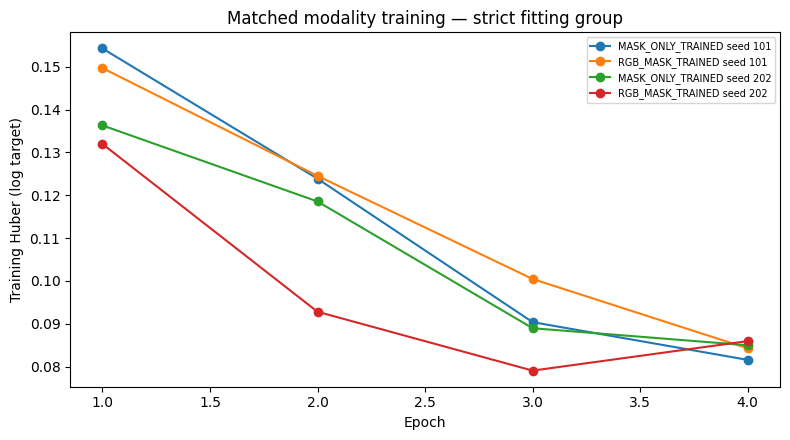


C3-12 SECTION 4 — MATCHED TRAINED MODALITY ABLATION
Strict FIT scenes: 79
Inner exposed diagnostic scenes: 5
MASK_ONLY_TRAINED         | MAE=8.6729 | D95=8.9919
RGB_MASK_TRAINED          | MAE=8.6059 | D95=8.5369
FIT_MASK_DISTANCE         | MAE=7.8310 | D95=9.2706

RGB minus MASK mean scene MAE, by seed: {'101': 0.06505060994645255, '202': -0.19904963229914419}

Trained and reloaded checkpoints: 4
RGB superiority established: NO — internal diagnostic only
Metric units or independent accuracy validated: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-12_section04_matched_modality_20261021T055603Z_d8dd7d


In [21]:
# ================================================================
# CRDL C3-12 SECTION 4 — MATCHED TRAINED MODALITY ABLATION
# RGB+MASK versus MASK-ONLY (RGB zeroed, trained anew)
# FIT: temporal 0004 | diagnostic: temporal 0003
# INTERNAL DEVELOPMENT ONLY | RAW UNITS | NO METRIC CLAIM
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

import csv
import json
import hashlib
import random
import shutil
import uuid
import os
import importlib.util

import numpy as np
import torch

from torch.utils.data import Dataset, DataLoader
from scipy.ndimage import distance_transform_edt
from scipy.optimize import minimize
from PIL import Image

import matplotlib.pyplot as plt


# ================================================================
# 1. RESTORE ORIGINAL PROJECT PATHS
# ================================================================

ROOT = Path('/content/drive/MyDrive')

PROJECT = (
    ROOT / 'crdl_experiments'
    / 'component3_fresh_v1'
)

DATA = (
    ROOT / 'manushi_research_data'
    / 'pothrgbd' / 'PData-main'
)

LABEL_RUN = (
    PROJECT / '04_geometry_targets'
    / 'C3-11_section01_RAW_target_pilot_'
      '20261021T043311Z_367db5'
    / 'C3-11_section04_weighted_feasibility_'
      '20261021T050356Z_383980'
)

TRAIN_RUN = (
    PROJECT / '05_training_runs'
    / 'C3-12_section01_CRDL_raw_geometry_'
      '20261021T052628Z_125b5d'
)

C310 = (
    PROJECT / '07_evaluation'
    / 'C3-09_physical_evidence_gate_v2_'
      '20261021T024723Z_ec15d662'
    / 'C3-10_section02_grouped_pilot_protocol_'
      '20261021T042524Z_735c9f'
)

ROLE_FILE = (
    C310 / 'PROVISIONAL_pilot_role_manifest.csv'
)

LABEL_FILE = (
    LABEL_RUN / 'target_eligibility_manifest.csv'
)

LABEL_PROTOCOL = (
    LABEL_RUN / 'protocol.json'
)

MODEL_FILE = (
    TRAIN_RUN / 'model_and_inference.py'
)

REVIEW_FILE = (
    C310 / 'cross_role_similarity_REVIEW.csv'
)

for p in (
    ROLE_FILE,
    LABEL_FILE,
    LABEL_PROTOCOL,
    MODEL_FILE,
    REVIEW_FILE
):
    assert p.is_file(), f'Missing prerequisite: {p}'


# ================================================================
# 2. REPRODUCIBILITY HELPERS
# ================================================================

def rows_of(p):

    with p.open(
        newline='',
        encoding='utf-8'
    ) as f:

        return list(csv.DictReader(f))


def sha(p):

    h = hashlib.sha256()

    with Path(p).open('rb') as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):
            h.update(chunk)

    return h.hexdigest()


def save_json(p, obj):

    p.write_text(
        json.dumps(
            obj,
            indent=2,
            allow_nan=False,
            default=str
        ),
        encoding='utf-8'
    )


def save_csv(p, rows, fields):

    with p.open(
        'w',
        newline='',
        encoding='utf-8'
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=fields
        )

        writer.writeheader()
        writer.writerows(rows)


# ================================================================
# 3. LOAD AND RESTRICT THE DATASET
# ================================================================

role_by_id = {
    r['sample_id']: r
    for r in rows_of(ROLE_FILE)
}

labels = rows_of(LABEL_FILE)

assert len(role_by_id) == 996
assert len(labels) == 489

assert len({
    r['sample_id']
    for r in labels
}) == 489

quarantine = {

    sid

    for r in rows_of(REVIEW_FILE)

    for sid in (
        r['sample_a'],
        r['sample_b']
    )
}

fit = sorted(
    (
        r for r in labels

        if (
            r['tier'] == 'STRICT'
            and r['sample_id'] not in quarantine
            and role_by_id[
                r['sample_id']
            ]['temporal_burst_proxy']
            == 'POTHRGBD_TEMPORAL_0004'
        )
    ),
    key=lambda x: x['sample_id']
)

inner = sorted(
    (
        r for r in labels

        if (
            r['tier'] == 'STRICT'
            and r['sample_id'] not in quarantine
            and role_by_id[
                r['sample_id']
            ]['temporal_burst_proxy']
            == 'POTHRGBD_TEMPORAL_0003'
        )
    ),
    key=lambda x: x['sample_id']
)

assert len(fit) >= 30
assert len(inner) >= 3

assert all(
    role_by_id[
        r['sample_id']
    ]['pilot_role'] == 'PILOT_TRAIN'

    for r in fit + inner
)

assert set(
    r['sample_id'] for r in fit
).isdisjoint(
    set(r['sample_id'] for r in inner)
)


# ================================================================
# 4. CREATE VERSIONED EXPERIMENT
# ================================================================

RUN = (
    PROJECT / '05_training_runs'
    / (
        'C3-12_section04_matched_modality_'
        + datetime.now(
            timezone.utc
        ).strftime('%Y%m%dT%H%M%SZ_')
        + uuid.uuid4().hex[:6]
    )
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)

shutil.copy2(
    MODEL_FILE,
    RUN / 'model_and_inference.py'
)

spec = importlib.util.spec_from_file_location(
    'crdl_matched_modality_model',
    RUN / 'model_and_inference.py'
)

mod = importlib.util.module_from_spec(spec)

spec.loader.exec_module(mod)


# ================================================================
# 5. FREEZE TRAINING CONFIGURATION
# ================================================================

CFG = {
    'stage': 'C3-12_SECTION04',
    'version': '1.0.0',

    'seeds': [101, 202],
    'epochs': 4,
    'batch_size': 4,
    'lr': 0.001,

    'arch': 'TinyCRDL_v1_base16',
    'input_hw': [192, 256],

    'fit_burst': 'POTHRGBD_TEMPORAL_0004',
    'diagnostic_burst': 'POTHRGBD_TEMPORAL_0003',
    'train_tier': 'STRICT_ONLY',

    'conditions': [
        'MASK_ONLY_TRAINED',
        'RGB_MASK_TRAINED'
    ],

    'loss': (
        'smooth_l1_log1p_raw_beta0.25_'
        'equal_sample_weights'
    ),

    'metric_depth_verified': False,
    'independent_scene_validation': False,

    'data_leakage_note': (
        'Provisional temporal grouping; '
        'physical-scene independence unverified'
    ),

    'label_manifest_sha256': sha(LABEL_FILE),
    'role_manifest_sha256': sha(ROLE_FILE),
    'label_protocol_sha256': sha(LABEL_PROTOCOL),
    'source_model_sha256': sha(MODEL_FILE),

    'suspect_ids_excluded': sorted(quarantine),

    'evaluation_rule': (
        'Fixed final epoch for every seed; '
        'no diagnostic-based checkpoint selection'
    )
}


# ================================================================
# 6. VERIFY AND PRELOAD SUPERVISED DATA
# ================================================================

source = []
target_medians = []

for r in fit + inner:

    sid = r['sample_id']

    relative = Path(r['target_relative_path'])

    assert not relative.is_absolute()

    assert len(relative.parts) == 2
    assert relative.parts[0] == 'targets'

    assert relative.name == (
        f'{sid}_axial_raw.npz'
    )

    target_path = LABEL_RUN / relative

    assert target_path.is_file()
    assert not target_path.is_symlink()

    assert sha(target_path) == r['target_sha256']

    rgb_path = Path(
        role_by_id[sid]['rgb_path']
    )

    assert rgb_path.is_file()
    assert not rgb_path.is_symlink()

    assert rgb_path.parent.resolve() == (
        DATA / 'images'
    ).resolve()

    with np.load(
        target_path,
        allow_pickle=False
    ) as npz:

        y = np.array(
            npz['target_raw'],
            dtype=np.float32
        )

        valid = np.array(
            npz['loss_mask'],
            dtype=bool
        )

        mask = np.array(
            npz['pothole_mask'],
            dtype=bool
        )

    assert (
        y.shape == mask.shape == valid.shape
        == (192, 256)
    )

    assert valid.sum() >= 60
    assert np.all(mask[valid])

    assert np.isfinite(y).all()
    assert (y >= 0).all()

    with Image.open(rgb_path) as im:

        rgb = np.asarray(
            im.convert('RGB').resize(
                (256, 192),
                Image.Resampling.BILINEAR
            ),
            dtype=np.float32
        ) / 255.0

    entry = {
        'sid': sid,
        'rgb': rgb,
        'mask': mask,
        'valid': valid,
        'target': y
    }

    source.append(entry)

    if r in fit:

        target_medians.append(
            float(
                np.percentile(
                    y[valid],
                    95
                )
            )
        )


FIT_IDS = {
    r['sample_id']
    for r in fit
}

INNER_IDS = {
    r['sample_id']
    for r in inner
}

fit_data = [
    r for r in source
    if r['sid'] in FIT_IDS
]

inner_data = [
    r for r in source
    if r['sid'] in INNER_IDS
]

SCALE_RAW = max(
    1.0,
    float(np.median(target_medians))
)

CFG['fit_n'] = len(fit_data)
CFG['inner_n'] = len(inner_data)
CFG['scale_raw_fit_only'] = SCALE_RAW

save_json(
    RUN / 'experiment_config.json',
    CFG
)

print("=" * 72)
print("C3-12 SECTION 4 — MATCHED RGB CONTRIBUTION EXPERIMENT")
print("=" * 72)

print("FIT strict:", len(fit_data))
print("INNER strict:", len(inner_data))

print(
    "Fit-only normalization scale:",
    round(SCALE_RAW, 5),
    "RAW"
)

print("Quarantined IDs:", sorted(quarantine))
print("Saved:", RUN)


# ================================================================
# 7. DEFINE MASK-ONLY AND RGB+MASK DATA LOADERS
# ================================================================

class ModalityData(Dataset):

    def __init__(self, items, mode):

        self.items = items
        self.mode = mode

    def __len__(self):

        return len(self.items)

    def __getitem__(self, i):

        item = self.items[i]

        if self.mode == 'RGB_MASK_TRAINED':

            rgb = item['rgb'].transpose(
                2, 0, 1
            ).copy()

        else:

            rgb = np.zeros(
                (3, 192, 256),
                dtype=np.float32
            )

        x = np.concatenate(
            [
                rgb,
                item['mask'][None].astype(
                    np.float32
                )
            ],
            axis=0
        )

        y = np.log1p(
            item['target'] / SCALE_RAW
        )

        return (
            torch.from_numpy(x),

            torch.from_numpy(
                y[None].astype(np.float32)
            ),

            torch.from_numpy(
                item['valid'][None].astype(
                    np.float32
                )
            )
        )


# ================================================================
# 8. DEFINE MATCHED SUPERVISED LOSS
# ================================================================

def loss_fn(pred, y, valid):

    loss = torch.nn.functional.smooth_l1_loss(
        pred,
        y,
        reduction='none',
        beta=0.25
    )

    per_image = (
        (loss * valid).flatten(1).sum(1)
        /
        valid.flatten(1).sum(1).clamp(min=1)
    )

    return per_image.mean()


# ================================================================
# 9. FROZEN MODEL EVALUATION HELPER
# ================================================================

def eval_model(model, items, mode, device):

    output = []

    model.eval()

    loader = DataLoader(
        ModalityData(items, mode),
        batch_size=2,
        shuffle=False
    )

    with torch.inference_mode():

        for x, _, valid in loader:

            z = model(
                x.to(device)
            ).clamp(max=8)

            raw = (
                SCALE_RAW
                * torch.expm1(z)
            ).cpu().numpy()[:, 0]

            output.extend(list(raw))

    return {
        r['sid']: pred
        for r, pred in zip(items, output)
    }


def score(pred, true, valid):

    p = pred[valid].astype(float)
    t = true[valid].astype(float)

    return {
        'mae_raw': float(
            np.mean(np.abs(p - t))
        ),

        'rmse_raw': float(
            np.sqrt(np.mean((p - t) ** 2))
        ),

        'd95_abs_raw': float(
            abs(
                np.percentile(p, 95)
                - np.percentile(t, 95)
            )
        ),

        'pred_spatial_std_raw': float(
            np.std(p)
        )
    }


# ================================================================
# 10. FIT NON-ML MASK-DISTANCE BASELINE
# ================================================================

# This baseline is fitted only on FIT samples.

matrix = np.zeros(
    (2, 2),
    dtype=float
)

vector = np.zeros(
    2,
    dtype=float
)

for r in fit_data:

    distance = distance_transform_edt(
        r['mask']
    ).astype(float)

    distance /= max(
        1.0,
        distance.max()
    )

    u = distance[r['valid']]

    target = r['target'][
        r['valid']
    ].astype(float)

    X = np.stack(
        [
            np.ones_like(u),
            u
        ],
        axis=1
    )

    matrix += X.T @ X / len(target)

    vector += X.T @ target / len(target)


initial_constant = float(
    np.median([
        np.median(
            r['target'][r['valid']]
        )
        for r in fit_data
    ])
)

result = minimize(
    lambda c: (
        float(
            c @ matrix @ c
            - 2 * vector @ c
        ),
        2 * (matrix @ c - vector)
    ),

    x0=[initial_constant, 0.0],

    jac=True,
    method='L-BFGS-B',

    bounds=[
        (0, None),
        (0, None)
    ],

    options={
        'maxiter': 500,
        'ftol': 1e-12
    }
)

assert result.success, result.message

shape_coef = result.x.astype(float)

print(
    "\nTraining-only mask-distance coefficients:",
    shape_coef
)


# ================================================================
# 11. PREPARE TRAINING DEVICE
# ================================================================

DEVICE = torch.device(
    'cuda'
    if torch.cuda.is_available()
    else 'cpu'
)

if DEVICE.type == 'cpu':

    torch.set_num_threads(
        min(
            4,
            os.cpu_count() or 2
        )
    )

print("Training device:", DEVICE)


# ================================================================
# 12. TRAIN MATCHED MODELS
# ================================================================

model_history = []
scores = []

for seed in CFG['seeds']:

    # Identical initial network weights.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    initial_model = mod.TinyCRDL(base=16)

    initial_weights = {
        k: v.detach().clone()
        for k, v in initial_model.state_dict().items()
    }

    for mode in CFG['conditions']:

        # Identical initialization and batch order.
        torch.manual_seed(seed)

        model = mod.TinyCRDL(
            base=16
        ).to(DEVICE)

        model.load_state_dict(
            initial_weights
        )

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=CFG['lr']
        )

        loader = DataLoader(
            ModalityData(fit_data, mode),

            batch_size=CFG['batch_size'],
            shuffle=True,
            num_workers=0,

            generator=torch.Generator().manual_seed(
                seed
            )
        )

        print(
            f"\nTRAIN seed={seed} mode={mode}, "
            f"examples={len(fit_data)}",
            flush=True
        )

        for epoch in range(
            1,
            CFG['epochs'] + 1
        ):

            model.train()

            n_seen = 0
            loss_sum = 0.0

            for xb, yb, vb in loader:

                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)
                vb = vb.to(DEVICE)

                optimizer.zero_grad(
                    set_to_none=True
                )

                prediction = model(xb)

                loss = loss_fn(
                    prediction,
                    yb,
                    vb
                )

                if not torch.isfinite(loss):

                    raise RuntimeError(
                        f'Nonfinite loss: {mode}, seed {seed}'
                    )

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    5.0
                )

                optimizer.step()

                loss_sum += (
                    float(loss.item()) * len(xb)
                )

                n_seen += len(xb)

            record = {
                'seed': seed,
                'mode': mode,
                'epoch': epoch,
                'train_huber': loss_sum / n_seen,
                'updates_per_epoch': len(loader)
            }

            model_history.append(record)

            print(
                f"  Epoch {epoch}/{CFG['epochs']}: "
                f"Huber={record['train_huber']:.5f}",
                flush=True
            )

        # ========================================================
        # 13. SAVE GENUINELY TRAINED MODEL
        # ========================================================

        checkpoint_path = (
            RUN /
            f'{mode.lower()}_seed{seed}_last.pt'
        )

        torch.save(
            {
                'state_dict': model.state_dict(),
                'base': 16,
                'mode': mode,
                'seed': seed,
                'epoch': CFG['epochs'],
                'scale_raw': SCALE_RAW,

                'source_model_sha256': sha(
                    RUN / 'model_and_inference.py'
                ),

                'physical_units_verified': False
            },
            checkpoint_path
        )

        # ========================================================
        # 14. RELOAD AND CHECK CHECKPOINT
        # ========================================================

        checkpoint = torch.load(
            checkpoint_path,
            map_location='cpu',
            weights_only=True
        )

        loaded_model = mod.TinyCRDL(
            base=checkpoint['base']
        ).to(DEVICE)

        loaded_model.load_state_dict(
            checkpoint['state_dict'],
            strict=True
        )

        loaded_model.eval()

        predictions = eval_model(
            loaded_model,
            inner_data,
            mode,
            DEVICE
        )

        model.eval()

        with torch.inference_mode():

            sample_x = next(
                iter(
                    DataLoader(
                        ModalityData(
                            inner_data,
                            mode
                        ),
                        batch_size=1
                    )
                )
            )[0].to(DEVICE)

            difference = float(
                (
                    model(sample_x)
                    - loaded_model(sample_x)
                ).abs().max().item()
            )

        assert difference < 1e-6

        assert set(predictions) == INNER_IDS

        for r in inner_data:

            scores.append({
                'seed': seed,

                'method': mode,

                'sample_id': r['sid'],

                **score(
                    predictions[r['sid']],
                    r['target'],
                    r['valid']
                )
            })

        del model, loaded_model

        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()


# ================================================================
# 15. EVALUATE MASK-DISTANCE BASELINE
# ================================================================

for r in inner_data:

    mask = r['mask']
    valid = r['valid']

    distance = distance_transform_edt(
        mask
    ).astype(float)

    distance /= max(
        1.0,
        distance.max()
    )

    predicted = (
        shape_coef[0]
        + shape_coef[1] * distance
    ) * mask

    scores.append({
        'seed': -1,

        'method': 'FIT_MASK_DISTANCE',

        'sample_id': r['sid'],

        **score(
            predicted,
            r['target'],
            valid
        )
    })


# ================================================================
# 16. SAVE HISTORY AND PER-SCENE RESULTS
# ================================================================

save_csv(
    RUN / 'matched_training_history.csv',
    model_history,
    list(model_history[0])
)

save_csv(
    RUN / 'matched_per_scene_scores.csv',
    scores,
    list(scores[0])
)


# ================================================================
# 17. PAIRED RGB-MINUS-MASK COMPARISON
# ================================================================

paired = []

for seed in CFG['seeds']:

    for sid in sorted(INNER_IDS):

        mask_result = next(
            x for x in scores
            if (
                x['seed'] == seed
                and x['sample_id'] == sid
                and x['method'] == 'MASK_ONLY_TRAINED'
            )
        )

        rgb_result = next(
            x for x in scores
            if (
                x['seed'] == seed
                and x['sample_id'] == sid
                and x['method'] == 'RGB_MASK_TRAINED'
            )
        )

        paired.append({
            'seed': seed,
            'sample_id': sid,

            'rgb_minus_mask_mae_raw': (
                rgb_result['mae_raw']
                - mask_result['mae_raw']
            ),

            'rgb_minus_mask_d95_error_raw': (
                rgb_result['d95_abs_raw']
                - mask_result['d95_abs_raw']
            )
        })


save_csv(
    RUN / 'paired_rgb_minus_mask.csv',
    paired,
    list(paired[0])
)


# ================================================================
# 18. AGGREGATE RESULTS
# ================================================================

summary = {}

for method in (
    list(CFG['conditions'])
    + ['FIT_MASK_DISTANCE']
):

    subset = [
        s for s in scores
        if s['method'] == method
    ]

    summary[method] = {
        'n_records': len(subset),

        'n_unique_scenes': len({
            r['sample_id']
            for r in subset
        }),

        'seeds': sorted({
            r['seed']
            for r in subset
        }),

        'mean_scene_mae_raw': float(
            np.mean([
                r['mae_raw']
                for r in subset
            ])
        ),

        'mean_scene_rmse_raw': float(
            np.mean([
                r['rmse_raw']
                for r in subset
            ])
        ),

        'mean_scene_d95_abs_raw': float(
            np.mean([
                r['d95_abs_raw']
                for r in subset
            ])
        )
    }


mean_diffs = {
    str(seed): float(
        np.mean([
            r['rgb_minus_mask_mae_raw']
            for r in paired
            if r['seed'] == seed
        ])
    )
    for seed in CFG['seeds']
}


# ================================================================
# 19. SAVE SCIENTIFIC REPORT
# ================================================================

report = {
    'stage': (
        'C3-12_SECTION04_MATCHED_'
        'TRAINED_MODALITY_ABLATION'
    ),

    'mode': 'RAW_AXIS_DEPENDENT_DEVELOPMENT',

    'fit_strict': len(fit_data),
    'inner_strict': len(inner_data),

    'frozen_configuration': CFG,

    'model_comparison': summary,

    'rgb_minus_mask_mean_scene_mae_by_seed':
        mean_diffs,

    'mask_prior_coefficients_fit_only':
        shape_coef.tolist(),

    'interpretation': (
        'Repeatedly inspected five-case internal '
        'diagnostic. Different random seeds do not '
        'create independent evaluation scenes.'
    ),

    'rgb_superiority_established': False,
    'physical_mm_verified': False,
    'scene_independence_verified': False,

    'no_extra_validation_or_crossday_data_used':
        True,

    'model_checkpoint_count': (
        len(CFG['seeds'])
        * len(CFG['conditions'])
    )
}

save_json(
    RUN / 'comparison_summary.json',
    report
)


# ================================================================
# 20. DISPLAY MATCHED TRAINING CURVES
# ================================================================

fig, ax = plt.subplots(
    figsize=(8, 4.5)
)

for seed in CFG['seeds']:

    for mode in CFG['conditions']:

        hist = [
            r for r in model_history
            if (
                r['seed'] == seed
                and r['mode'] == mode
            )
        ]

        ax.plot(
            [r['epoch'] for r in hist],
            [r['train_huber'] for r in hist],

            marker='o',
            label=f'{mode} seed {seed}'
        )

ax.set_xlabel('Epoch')

ax.set_ylabel(
    'Training Huber (log target)'
)

ax.set_title(
    'Matched modality training — strict fitting group'
)

ax.legend(fontsize=7)

fig.tight_layout()

fig.savefig(
    RUN / 'matched_training_curves.png',
    dpi=150
)

plt.show()
plt.close(fig)


# ================================================================
# 21. GENERATE ARTIFACT CHECKSUMS
# ================================================================

receipts = []

for p in sorted(RUN.iterdir()):

    if (
        p.is_file()
        and p.name != 'sha256_manifest.json'
    ):

        receipts.append({
            'filename': p.name,
            'bytes': p.stat().st_size,
            'sha256': sha(p)
        })


save_json(
    RUN / 'sha256_manifest.json',
    receipts
)


# ================================================================
# 22. FINAL RESEARCH SUMMARY
# ================================================================

print("\n" + "=" * 72)

print(
    "C3-12 SECTION 4 — MATCHED TRAINED MODALITY ABLATION"
)

print("=" * 72)

print(
    "Strict FIT scenes:",
    len(fit_data)
)

print(
    "Inner exposed diagnostic scenes:",
    len(inner_data)
)

for name, values in summary.items():

    print(
        f'{name:25s} | '
        f'MAE={values["mean_scene_mae_raw"]:.4f} | '
        f'D95={values["mean_scene_d95_abs_raw"]:.4f}'
    )

print(
    "\nRGB minus MASK mean scene MAE, by seed:",
    mean_diffs
)

print(
    "\nTrained and reloaded checkpoints:",
    report['model_checkpoint_count']
)

print(
    "RGB superiority established: NO — "
    "internal diagnostic only"
)

print(
    "Metric units or independent accuracy "
    "validated: NO"
)

print("\nSaved:", RUN)

print("=" * 72)

Loaded 100 / 278
Loaded 200 / 278

C3-12 SECTION 5 — MAIN CRDL TRAINING
Training device: cuda
GPU: Tesla T4
Epochs per model: 10
Batch size: 8
Fitting: 273 = 79 STRICT + 194 AUX
Inner diagnostic: 5
Training normalization: 40.8135871887207 RAW units
Geometry-prior coefficients: [11.434503555297852, 39.74112319946289]
Output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-12_section05_main_training_20261021T062404Z_3206b0
DIRECT_RGB_MASK    epoch 01/10 loss=0.08294 | saved
DIRECT_RGB_MASK    epoch 02/10 loss=0.05882 | saved
DIRECT_RGB_MASK    epoch 03/10 loss=0.05052 | saved
DIRECT_RGB_MASK    epoch 04/10 loss=0.04807 | saved
DIRECT_RGB_MASK    epoch 05/10 loss=0.04961 | saved
DIRECT_RGB_MASK    epoch 06/10 loss=0.05006 | saved
DIRECT_RGB_MASK    epoch 07/10 loss=0.04561 | saved
DIRECT_RGB_MASK    epoch 08/10 loss=0.04449 | saved
DIRECT_RGB_MASK    epoch 09/10 loss=0.04358 | saved
DIRECT_RGB_MASK    epoch 10/10 loss=0.05047 | saved
PRIOR_RGB_MASK     epoc

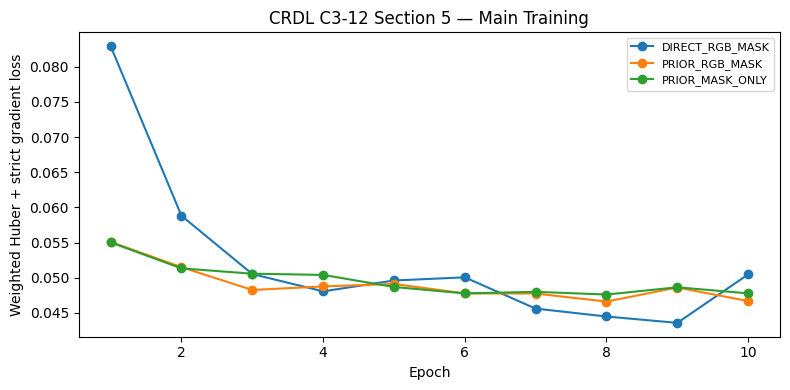

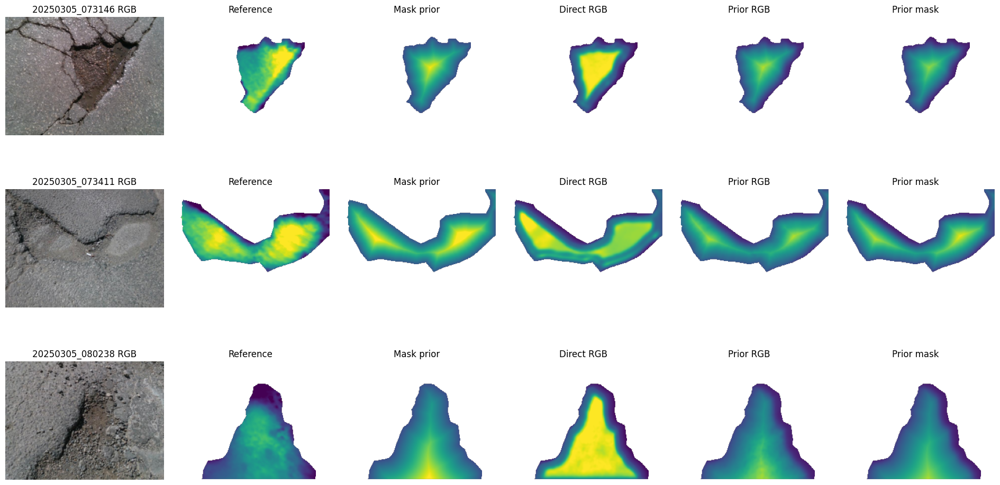


C3-12 SECTION 5 — MAIN TRAINING COMPLETE
Trained models: ['DIRECT_RGB_MASK', 'PRIOR_RGB_MASK', 'PRIOR_MASK_ONLY']
Epochs: 10
Device: cuda

COMMON INTERNAL DIAGNOSTIC:
ZERO                   MAE=25.077 RAW | D95 error=38.856 RAW
TRAIN_CONSTANT         MAE=8.652 RAW | D95 error=12.550 RAW
TRAIN_MASK_DISTANCE    MAE=7.831 RAW | D95 error=9.271 RAW
DIRECT_RGB_MASK        MAE=11.466 RAW | D95 error=9.613 RAW
PRIOR_RGB_MASK         MAE=8.365 RAW | D95 error=8.129 RAW
PRIOR_MASK_ONLY        MAE=8.446 RAW | D95 error=7.903 RAW

Checkpoint cold-load smoke tests: PASS
Verified metric units: NO
Independent scene validation: NO

Saved to:
/content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-12_section05_main_training_20261021T062404Z_3206b0


In [2]:
# ================================================================
# CRDL COMPONENT 3 — C3-12 SECTION 5
# MAIN TRAINING: DIRECT CRDL + LEARNED GEOMETRY CORRECTION
#
# ALL CODE IN THIS CELL — NO FILE PICKER OR UPLOAD
#
# Training:
#   A. Direct RGB + mask CRDL
#   B. Geometry-prior + RGB correction
#   C. Geometry-prior + mask-only correction
#
# FIT: 273 examples, including 79 strict and 194 auxiliary
# INTERNAL DIAGNOSTIC: 5 strict examples
#
# Saves: trained checkpoints, inference implementation,
# training plots, evaluation, configuration, checksums
#
# PHYSICAL SCALE UNVERIFIED | NO INDEPENDENT TEST
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import csv, json, hashlib, random, uuid, os, importlib.util

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from scipy.ndimage import distance_transform_edt
from scipy.optimize import minimize
import matplotlib.pyplot as plt


# ================================================================
# 1. MOUNT DRIVE AND RESTORE ALL EXISTING LOCATIONS
# ================================================================

ROOT = Path("/content/drive/MyDrive")

if not ROOT.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT = (
    ROOT / "crdl_experiments" / "component3_fresh_v1"
)

SOURCE = (
    ROOT / "manushi_research_data" / "pothrgbd" / "PData-main"
)

LABEL_RUN = (
    PROJECT / "04_geometry_targets"
    / "C3-11_section01_RAW_target_pilot_20261021T043311Z_367db5"
    / "C3-11_section04_weighted_feasibility_20261021T050356Z_383980"
)

ROLE_FILE = (
    PROJECT / "07_evaluation"
    / "C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662"
    / "C3-10_section02_grouped_pilot_protocol_20261021T042524Z_735c9f"
    / "PROVISIONAL_pilot_role_manifest.csv"
)

LABEL_FILE = LABEL_RUN / "target_eligibility_manifest.csv"
PROTOCOL = LABEL_RUN / "protocol.json"

assert ROLE_FILE.is_file()
assert LABEL_FILE.is_file()
assert PROTOCOL.is_file()
assert SOURCE.is_dir()


# ================================================================
# 2. REPRODUCIBILITY UTILITIES
# ================================================================

def readcsv(path):
    with path.open(newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))


def sha(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def write_json(path, obj):
    path.write_text(
        json.dumps(obj, indent=2, allow_nan=False, default=str),
        encoding="utf-8"
    )


def write_csv(path, rows):
    if not rows:
        return

    with path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


# ================================================================
# 3. VERIFY PREVIOUS TRAINING-TARGET MANIFEST
# ================================================================

roles = {
    r["sample_id"]: r
    for r in readcsv(ROLE_FILE)
}

labels = readcsv(LABEL_FILE)

assert len(roles) == 996
assert len(labels) == 489

assert Counter(r["tier"] for r in labels) == {
    "STRICT": 84,
    "AUX_EXPERIMENTAL": 212,
    "REVIEW": 193
}

review_file = (
    ROLE_FILE.parent / "cross_role_similarity_REVIEW.csv"
)

quarantine = {
    sid
    for r in readcsv(review_file)
    for sid in (r["sample_a"], r["sample_b"])
}


# ================================================================
# 4. RECOVER THE 273 FITTING EXAMPLES
# ================================================================

items = []

for row in labels:

    if row["tier"] not in ("STRICT", "AUX_EXPERIMENTAL"):
        continue

    sid = row["sample_id"]
    role = roles[sid]

    assert role["pilot_role"] == "PILOT_TRAIN"
    assert role["capture_day_proxy"] == "2025-03-05"
    assert sid not in quarantine

    burst = role["temporal_burst_proxy"]

    assert burst in (
        "POTHRGBD_TEMPORAL_0003",
        "POTHRGBD_TEMPORAL_0004"
    )

    relative = Path(row["target_relative_path"])

    assert not relative.is_absolute()
    assert len(relative.parts) == 2
    assert relative.parts[0] == "targets"
    assert relative.name == f"{sid}_axial_raw.npz"

    target_path = LABEL_RUN / relative
    rgb_path = Path(role["rgb_path"])

    assert target_path.is_file()
    assert not target_path.is_symlink()
    assert sha(target_path) == row["target_sha256"]

    assert rgb_path.is_file()
    assert not rgb_path.is_symlink()
    assert rgb_path.parent.resolve() == (
        SOURCE / "images"
    ).resolve()

    items.append({
        "sid": sid,
        "tier": row["tier"],
        "burst": burst,
        "target_path": target_path,
        "rgb_path": rgb_path
    })


fit = sorted(
    [r for r in items if r["burst"].endswith("0004")],
    key=lambda r: r["sid"]
)

inner = sorted(
    [
        r for r in items
        if r["burst"].endswith("0003")
        and r["tier"] == "STRICT"
    ],
    key=lambda r: r["sid"]
)

assert len(fit) == 273
assert len(inner) == 5

assert Counter(r["tier"] for r in fit) == {
    "STRICT": 79,
    "AUX_EXPERIMENTAL": 194
}


# ================================================================
# 5. CREATE A VERSIONED TRAINING RUN
# ================================================================

# To resume after a runtime restart, replace None with
# the exact RUN path printed during the previous execution.
# No upload or file picker is ever needed.

RESUME_RUN = None

if RESUME_RUN is not None:
    RUN = Path(RESUME_RUN)

elif (
    "C3125_RUN" in globals()
    and Path(C3125_RUN).is_dir()
):
    RUN = Path(C3125_RUN)

else:
    RUN = (
        PROJECT / "05_training_runs"
        / (
            "C3-12_section05_main_training_"
            + datetime.now(timezone.utc).strftime(
                "%Y%m%dT%H%M%SZ_"
            )
            + uuid.uuid4().hex[:6]
        )
    )

    RUN.mkdir(parents=True, exist_ok=False)

C3125_RUN = RUN

assert RUN.is_dir()
assert RUN.parent.resolve() == (
    PROJECT / "05_training_runs"
).resolve()


# ================================================================
# 6. CONFIGURE GPU TRAINING
# ================================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 2))

SEED = 101

EPOCHS = 10 if DEVICE.type == "cuda" else 5
BATCH = 8 if DEVICE.type == "cuda" else 4

MODES = [
    "DIRECT_RGB_MASK",
    "PRIOR_RGB_MASK",
    "PRIOR_MASK_ONLY"
]

CFG = {
    "version": "C3-12_section05_v1",
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH,
    "lr": 0.001,
    "modes": MODES,
    "fit_burst": "POTHRGBD_TEMPORAL_0004",
    "inner_burst": "POTHRGBD_TEMPORAL_0003",
    "fit_n": len(fit),
    "inner_strict_n": len(inner),
    "target_units": "UNVERIFIED_RAW_AXIAL_SENSOR_UNITS",
    "physical_mm_certified": False,
    "scene_independence_certified": False,
    "label_manifest_sha256": sha(LABEL_FILE),
    "role_manifest_sha256": sha(ROLE_FILE),
    "protocol_sha256": sha(PROTOCOL),
    "gradient_strict_lambda": 0.05,
    "strict_aux_loss_weights": "precomputed_in_targets",
    "checkpoint_selection": "FIXED_LAST_EPOCH",
    "early_stopping": False
}


# ================================================================
# 7. DEFINE AND SAVE THE TRAINABLE MODEL ARCHITECTURE
# ================================================================

# The source implementation is created INSIDE this cell.
# Colab automatically writes it to the versioned RUN folder.
# There is nothing to download or upload.

MODEL_SOURCE = r'''
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from PIL import Image
from scipy.ndimage import distance_transform_edt


class ConvBlock(nn.Module):

    def __init__(self, cin, cout):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class RoadRelativeCRDL(nn.Module):

    def __init__(self, base=16, mode="DIRECT_RGB_MASK"):

        super().__init__()

        assert mode in (
            "DIRECT_RGB_MASK",
            "PRIOR_RGB_MASK",
            "PRIOR_MASK_ONLY"
        )

        self.mode = mode

        self.e1 = ConvBlock(4, base)
        self.e2 = ConvBlock(base, 2 * base)

        self.mid = ConvBlock(2 * base, 4 * base)

        self.d2 = ConvBlock(6 * base, 2 * base)
        self.d1 = ConvBlock(3 * base, base)

        self.head = nn.Conv2d(base, 1, 1)

        nn.init.zeros_(self.head.weight)

        nn.init.constant_(
            self.head.bias,
            -1.5 if mode == "DIRECT_RGB_MASK" else 0.0
        )

    def forward(self, x, prior_raw, scale_raw):

        mask = x[:, 3:4]

        if self.mode == "PRIOR_MASK_ONLY":

            x = torch.cat(
                (torch.zeros_like(x[:, :3]), mask),
                dim=1
            )

        a = self.e1(x)

        b = self.e2(F.avg_pool2d(a, 2))

        mid = self.mid(F.avg_pool2d(b, 2))

        c = self.d2(
            torch.cat(
                (
                    b,
                    F.interpolate(
                        mid,
                        size=b.shape[-2:],
                        mode="bilinear",
                        align_corners=False
                    )
                ),
                dim=1
            )
        )

        decoded = self.d1(
            torch.cat(
                (
                    a,
                    F.interpolate(
                        c,
                        size=a.shape[-2:],
                        mode="bilinear",
                        align_corners=False
                    )
                ),
                dim=1
            )
        )

        logits = self.head(decoded)

        if self.mode != "DIRECT_RGB_MASK":

            # At zero learned correction:
            # softplus(log(prior / scale))
            # = log1p(prior / scale)

            logits = logits + torch.log(
                (prior_raw / float(scale_raw)).clamp(
                    min=1e-6
                )
            )

        return F.softplus(logits) * mask


def mask_prior(mask, coef):

    mask = np.asarray(mask, dtype=bool)

    distance = distance_transform_edt(
        mask
    ).astype(np.float32)

    distance /= max(float(distance.max()), 1.0)

    prior = (
        float(coef[0])
        + float(coef[1]) * distance
    )

    return (prior * mask).astype(np.float32)


def prepare_inputs(rgb, mask, coef, size_hw=(192, 256)):

    rgb = np.asarray(rgb)
    mask = np.asarray(mask)

    if (
        rgb.ndim != 3
        or rgb.shape[2] != 3
        or mask.shape != rgb.shape[:2]
    ):
        raise ValueError(
            "Expected aligned RGB(H,W,3) and mask(H,W)"
        )

    h, w = size_hw

    image = np.asarray(
        Image.fromarray(
            rgb.astype(np.uint8)
        ).resize(
            (w, h),
            Image.Resampling.BILINEAR
        ),
        dtype=np.float32
    ) / 255.0

    binary = np.asarray(
        Image.fromarray(
            (mask > 0).astype(np.uint8) * 255
        ).resize(
            (w, h),
            Image.Resampling.NEAREST
        )
    ) > 0

    x = np.concatenate(
        (
            image.transpose(2, 0, 1),
            binary[None].astype(np.float32)
        ),
        axis=0
    )

    prior = mask_prior(binary, coef)

    return (
        torch.from_numpy(x).float(),
        torch.from_numpy(prior[None]).float()
    )


def infer_raw(model, rgb, mask, scale_raw, coef, device="cpu"):

    x, prior = prepare_inputs(
        rgb,
        mask,
        coef
    )

    model.eval()

    with torch.inference_mode():

        z = model(
            x[None].to(device),
            prior[None].to(device),
            scale_raw
        ).clamp(max=8)

        output = float(scale_raw) * torch.expm1(z)

    return output[0, 0].cpu().numpy().astype(
        np.float32
    )
'''

model_file = RUN / "model_and_inference.py"

if model_file.exists():

    assert model_file.read_text(
        encoding="utf-8"
    ) == MODEL_SOURCE, "Model source mismatch on resume"

else:

    model_file.write_text(
        MODEL_SOURCE,
        encoding="utf-8"
    )

spec = importlib.util.spec_from_file_location(
    "c3125_saved_arch",
    model_file
)

mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)


# ================================================================
# 8. LOAD REAL RGB INPUTS AND TARGETS INTO MEMORY
# ================================================================

cache = {}
fit_p95 = []

for j, r in enumerate(fit + inner, 1):

    with np.load(
        r["target_path"],
        allow_pickle=False
    ) as d:

        target = np.array(
            d["target_raw"],
            dtype=np.float32
        )

        valid = np.array(
            d["loss_mask"],
            dtype=bool
        )

        weight = np.array(
            d["loss_weight"],
            dtype=np.float32
        )

        mask = np.array(
            d["pothole_mask"],
            dtype=bool
        )

    assert (
        target.shape
        == valid.shape
        == weight.shape
        == mask.shape
        == (192, 256)
    )

    assert valid.sum() >= 60
    assert np.isfinite(target).all()
    assert np.all(target >= 0)
    assert np.isfinite(weight).all()
    assert np.all(weight >= 0)
    assert np.all(weight[~valid] == 0)
    assert np.all(~valid | mask)

    if r["tier"] == "STRICT":

        assert np.allclose(weight[valid], 1.0)

    else:

        assert (weight[valid] > 0).all()
        assert (weight[valid] <= 0.5 + 1e-6).all()

    with Image.open(r["rgb_path"]) as im:

        rgb = np.asarray(
            im.convert("RGB").resize(
                (256, 192),
                Image.Resampling.BILINEAR
            ),
            dtype=np.float32
        ) / 255.0

    x = np.concatenate(
        [
            rgb.transpose(2, 0, 1),
            mask[None].astype(np.float32)
        ],
        axis=0
    )

    cache[r["sid"]] = {
        "x": x,
        "raw": target,
        "valid": valid,
        "weight": weight,
        "mask": mask,
        "tier": r["tier"]
    }

    if (
        r["burst"].endswith("0004")
        and r["tier"] == "STRICT"
    ):

        fit_p95.append(
            float(
                np.percentile(
                    target[valid],
                    95
                )
            )
        )

    if j % 100 == 0:
        print(
            "Loaded", j, "/", len(fit) + len(inner),
            flush=True
        )

SCALE_RAW = max(
    1.0,
    float(np.median(fit_p95))
)


# ================================================================
# 9. FIT MASK-DISTANCE GEOMETRY PRIOR
# ================================================================

# Fitted only on the 79 strict FIT examples.
# The five inner diagnostic examples do not
# contribute to the baseline parameters.

AA = np.zeros((2, 2), dtype=np.float64)
bb = np.zeros(2, dtype=np.float64)

train_medians = []

for r in fit:

    if r["tier"] != "STRICT":
        continue

    rec = cache[r["sid"]]

    distance = distance_transform_edt(
        rec["mask"]
    ).astype(np.float64)

    distance /= max(float(distance.max()), 1.0)

    vals = distance[rec["valid"]]

    tgt = rec["raw"][rec["valid"]].astype(
        np.float64
    )

    XX = np.column_stack(
        (
            np.ones(vals.size),
            vals
        )
    )

    AA += (XX.T @ XX) / len(tgt)
    bb += (XX.T @ tgt) / len(tgt)

    train_medians.append(
        float(np.median(tgt))
    )

CONSTANT = float(np.median(train_medians))

opt = minimize(
    lambda p: (
        float(p @ AA @ p - 2 * bb @ p),
        2 * (AA @ p - bb)
    ),
    [CONSTANT, 0.0],
    jac=True,
    method="L-BFGS-B",
    bounds=[(0, None), (0, None)],
    options={"maxiter": 500}
)

assert opt.success, opt.message

COEF = np.asarray(
    opt.x,
    dtype=np.float32
)

for sid, rec in cache.items():

    rec["prior"] = mod.mask_prior(
        rec["mask"],
        COEF
    )

    rec["y"] = np.log1p(
        rec["raw"] / SCALE_RAW
    ).astype(np.float32)


# ================================================================
# 10. SAVE THE FROZEN TRAINING CONFIGURATION
# ================================================================

CFG.update({
    "scale_raw_fit_only": SCALE_RAW,
    "mask_prior_coef_fit_only": COEF.tolist(),
    "source_code_sha256": sha(model_file),
    "fit_strict_count": 79,
    "fit_aux_count": 194,
    "torch_version": torch.__version__,
    "device_at_creation": str(DEVICE)
})

config_file = RUN / "experiment_config.json"

if config_file.exists():

    old = json.loads(
        config_file.read_text(encoding="utf-8")
    )

    for k, v in CFG.items():

        if k not in ("device_at_creation", "torch_version"):

            assert old.get(k) == v, (
                f"Resume configuration mismatch: {k}"
            )

else:

    write_json(config_file, CFG)


print("\n" + "=" * 72)
print("C3-12 SECTION 5 — MAIN CRDL TRAINING")
print("=" * 72)

print("Training device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Epochs per model:", EPOCHS)
print("Batch size:", BATCH)

print(
    "Fitting:",
    len(fit),
    "= 79 STRICT + 194 AUX"
)

print("Inner diagnostic:", len(inner))

print(
    "Training normalization:",
    SCALE_RAW,
    "RAW units"
)

print("Geometry-prior coefficients:", COEF.tolist())

print("Output:", RUN)
print("=" * 72, flush=True)


# ================================================================
# 11. DEFINE THE PYTORCH DATASET
# ================================================================

class CachedDataset(Dataset):

    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):

        rec = cache[self.rows[index]["sid"]]

        return (
            torch.from_numpy(rec["x"]),

            torch.from_numpy(
                rec["prior"][None]
            ),

            torch.from_numpy(
                rec["y"][None]
            ),

            torch.from_numpy(
                rec["weight"][None]
            ),

            torch.from_numpy(
                rec["valid"][None].astype(np.float32)
            ),

            torch.tensor(
                float(rec["tier"] == "STRICT"),
                dtype=torch.float32
            )
        )


# ================================================================
# 12. RELIABILITY-WEIGHTED GEOMETRY TRAINING LOSS
# ================================================================

def objective(pred, y, weight, valid, is_strict):

    # Primary robust regression loss.
    elementwise = torch.nn.functional.smooth_l1_loss(
        pred,
        y,
        beta=0.25,
        reduction="none"
    )

    # Normalization by valid pixel count preserves
    # the auxiliary downweighting.
    main = (
        (
            (elementwise * weight)
            .flatten(1)
            .sum(1)
        )
        /
        valid.flatten(1).sum(1).clamp(min=1)
    ).mean()

    # Gradient consistency on STRICT supervision.
    gradient_terms = []

    for dim in (-1, -2):

        p_diff = pred.diff(dim=dim)
        y_diff = y.diff(dim=dim)

        if dim == -1:

            adjacent = (
                valid[:, :, :, 1:]
                * valid[:, :, :, :-1]
            )

        else:

            adjacent = (
                valid[:, :, 1:, :]
                * valid[:, :, :-1, :]
            )

        gradient_error = (
            torch.nn.functional.smooth_l1_loss(
                p_diff,
                y_diff,
                beta=0.25,
                reduction="none"
            )
        )

        per_image = (
            (gradient_error * adjacent)
            .flatten(1)
            .sum(1)
            /
            adjacent.flatten(1)
            .sum(1)
            .clamp(min=1)
        )

        strict_gradient = (
            (per_image * is_strict).sum()
            /
            is_strict.sum().clamp(min=1)
        )

        gradient_terms.append(strict_gradient)

    return (
        main
        + 0.05 * sum(gradient_terms) / 2
    )


# ================================================================
# 13. DEFINE COMMON EVALUATION METRICS
# ================================================================

def metric(pred, target, valid):

    p = np.asarray(
        pred[valid],
        dtype=np.float64
    )

    t = np.asarray(
        target[valid],
        dtype=np.float64
    )

    error = p - t

    return {
        "mae_raw": float(
            np.abs(error).mean()
        ),

        "rmse_raw": float(
            np.sqrt(
                (error * error).mean()
            )
        ),

        "d95_abs_raw": float(
            abs(
                np.percentile(p, 95)
                - np.percentile(t, 95)
            )
        )
    }


# ================================================================
# 14. PREPARE REPRODUCIBLE MODEL INITIALIZATION
# ================================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

initial_weights = {}

for mode in MODES:

    torch.manual_seed(SEED)

    initial_weights[mode] = {
        k: v.detach().cpu().clone()

        for k, v in mod.RoadRelativeCRDL(
            base=16,
            mode=mode
        ).state_dict().items()
    }


# ================================================================
# 15. TRAIN ALL THREE MODELS
# ================================================================

for mode in MODES:

    torch.manual_seed(SEED)

    model = mod.RoadRelativeCRDL(
        base=16,
        mode=mode
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001
    )

    checkpoint_path = (
        RUN / f"{mode.lower()}_last.pt"
    )

    start_epoch = 1

    # ------------------------------------------------------------
    # Resume from the previous completed epoch if applicable.
    # ------------------------------------------------------------

    if checkpoint_path.exists():

        ck = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        assert ck["mode"] == mode
        assert ck["config_sha256"] == sha(config_file)

        model.load_state_dict(
            ck["state_dict"],
            strict=True
        )

        optimizer.load_state_dict(
            ck["optimizer_state"]
        )

        for state in optimizer.state.values():
            for k, value in state.items():
                if isinstance(value, torch.Tensor):
                    state[k] = value.to(DEVICE)

        start_epoch = int(ck["epoch"]) + 1

        print(
            "RESUMING", mode,
            "from epoch", start_epoch - 1,
            flush=True
        )

    else:

        model.load_state_dict(
            initial_weights[mode]
        )

    # ------------------------------------------------------------
    # Actual neural network training loop.
    # ------------------------------------------------------------

    for epoch in range(start_epoch, EPOCHS + 1):

        model.train()

        total = 0.0
        seen = 0

        loader = DataLoader(
            CachedDataset(fit),
            batch_size=BATCH,
            shuffle=True,
            num_workers=0,
            generator=torch.Generator().manual_seed(
                SEED + epoch
            )
        )

        for batch in loader:

            x, prior, y, weight, valid, strict = [
                tensor.to(DEVICE)
                for tensor in batch
            ]

            optimizer.zero_grad(set_to_none=True)

            prediction = model(
                x,
                prior,
                SCALE_RAW
            )

            loss = objective(
                prediction,
                y,
                weight,
                valid,
                strict
            )

            assert bool(torch.isfinite(loss)), (
                f"Non-finite loss: {mode}, epoch {epoch}"
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                5.0
            )

            optimizer.step()

            total += float(loss.detach().item()) * len(x)
            seen += len(x)

        mean_loss = total / seen

        # --------------------------------------------------------
        # Save or update the loss history.
        # --------------------------------------------------------

        history_file = RUN / "training_history.csv"

        history = (
            readcsv(history_file)
            if history_file.exists()
            else []
        )

        history = [
            r for r in history
            if not (
                r["mode"] == mode
                and int(r["epoch"]) == epoch
            )
        ]

        history.append({
            "mode": mode,
            "epoch": epoch,
            "train_loss": mean_loss,
            "n_fit": seen
        })

        history.sort(
            key=lambda r: (
                r["mode"],
                int(r["epoch"])
            )
        )

        write_csv(history_file, history)

        # --------------------------------------------------------
        # Save actual weights and optimizer for resumption.
        # --------------------------------------------------------

        temporary_path = checkpoint_path.with_suffix(
            ".pt.tmp"
        )

        torch.save(
            {
                "state_dict": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "mode": mode,
                "epoch": epoch,
                "base": 16,
                "scale_raw": SCALE_RAW,
                "prior_coefficients": COEF.tolist(),
                "config_sha256": sha(config_file),
                "physical_units_verified": False
            },
            temporary_path
        )

        os.replace(
            temporary_path,
            checkpoint_path
        )

        print(
            f"{mode:18s} "
            f"epoch {epoch:02d}/{EPOCHS} "
            f"loss={mean_loss:.5f} | saved",
            flush=True
        )

    del model, optimizer

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


# ================================================================
# 16. VERIFY COMPLETED TRAINING CHECKPOINTS
# ================================================================

for mode in MODES:

    path = RUN / f"{mode.lower()}_last.pt"

    ck = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    assert ck["mode"] == mode
    assert ck["epoch"] == EPOCHS
    assert ck["config_sha256"] == sha(config_file)

print("\nAll three training checkpoints verified.")


# ================================================================
# 17. FROZEN COMMON DIAGNOSTIC EVALUATION
# ================================================================

results = []
previews = []

for r in inner:

    rec = cache[r["sid"]]

    truth = rec["raw"]
    valid = rec["valid"]
    mask = rec["mask"]

    predictions = {
        "ZERO": np.zeros_like(truth),

        "TRAIN_CONSTANT": (
            CONSTANT * mask.astype(np.float32)
        ),

        "TRAIN_MASK_DISTANCE": rec["prior"]
    }

    for mode in MODES:

        ck = torch.load(
            RUN / f"{mode.lower()}_last.pt",
            map_location=DEVICE,
            weights_only=True
        )

        net = mod.RoadRelativeCRDL(
            base=16,
            mode=mode
        ).to(DEVICE)

        net.load_state_dict(
            ck["state_dict"],
            strict=True
        )

        net.eval()

        with torch.inference_mode():

            x = torch.from_numpy(
                rec["x"][None]
            ).to(DEVICE)

            prior = torch.from_numpy(
                rec["prior"][None, None]
            ).to(DEVICE)

            pred_log = net(
                x,
                prior,
                SCALE_RAW
            ).clamp(max=8)

            pred_raw = (
                SCALE_RAW * torch.expm1(pred_log)
            )[0, 0].cpu().numpy()

        assert np.isfinite(pred_raw).all()
        assert (pred_raw >= 0).all()

        predictions[mode] = pred_raw

        # Cold-loaded checkpoint smoke test.
        empty = x.clone()
        empty[:, 3] = 0

        with torch.inference_mode():

            empty_prediction = net(
                empty,
                torch.zeros_like(prior),
                SCALE_RAW
            )

            assert (
                torch.count_nonzero(empty_prediction) == 0
            )

        del net

    for method, pred in predictions.items():

        results.append({
            "sid": r["sid"],
            "method": method,
            "valid_pixels": int(valid.sum()),
            **metric(pred, truth, valid)
        })

    if len(previews) < 3:

        previews.append(
            (
                r["sid"],
                rec["x"][:3].transpose(1, 2, 0),
                truth,
                valid,
                predictions
            )
        )


# ================================================================
# 18. SAVE PER-SCENE EVALUATION
# ================================================================

write_csv(
    RUN / "per_scene_diagnostic.csv",
    results
)

summary = {}

for method in (
    [
        "ZERO",
        "TRAIN_CONSTANT",
        "TRAIN_MASK_DISTANCE"
    ]
    + MODES
):

    subset = [
        r for r in results
        if r["method"] == method
    ]

    summary[method] = {
        key: float(
            np.mean([
                r[key] for r in subset
            ])
        )

        for key in (
            "mae_raw",
            "rmse_raw",
            "d95_abs_raw"
        )
    }


report = {
    "status": "TRAINED_AND_COLD_LOADED",
    "run": str(RUN),
    "fit_n": len(fit),
    "inner_n": len(inner),
    "models": summary,
    "metric_units_verified": False,
    "road_normal_depth_verified": False,
    "independent_scene_validation": False,
    "final_winner_established": False,
    "interpretation": (
        "Five repeatedly inspected development scenes. "
        "Not independent generalization evidence."
    )
}

write_json(
    RUN / "evaluation_summary.json",
    report
)


# ================================================================
# 19. BACKEND-FACING RAW PILOT CONTRACT
# ================================================================

write_json(
    RUN / "api_contract_raw_pilot.json",
    {
        "version": "crdl-c3/0.5-raw-pilot",

        "inputs": {
            "rgb": "uint8 HxWx3 RGB",
            "pothole_mask": "HxW aligned binary mask"
        },

        "outputs": {
            "raw_axial_depression_map": (
                "192x256 raw sensor units"
            ),
            "d95_mm": None,
            "depth_max_mm": None,
            "area_m2": None,
            "volume_m3": None,
            "physical_severity": None,
            "reliability_status": (
                "RELATIVE_ONLY_UNVERIFIED_CALIBRATION"
            )
        },

        "integration_status": (
            "MODEL_SMOKE_TESTED; "
            "SYSTEM_NOT_YET_VALIDATED"
        )
    }
)


# ================================================================
# 20. PLOT TRAINING CURVES
# ================================================================

history = readcsv(
    RUN / "training_history.csv"
)

fig, ax = plt.subplots(figsize=(8, 4))

for mode in MODES:

    subset = [
        r for r in history
        if r["mode"] == mode
    ]

    ax.plot(
        [int(r["epoch"]) for r in subset],
        [float(r["train_loss"]) for r in subset],
        marker="o",
        label=mode
    )

ax.set_xlabel("Epoch")
ax.set_ylabel(
    "Weighted Huber + strict gradient loss"
)

ax.set_title(
    "CRDL C3-12 Section 5 — Main Training"
)

ax.legend(fontsize=8)

fig.tight_layout()

fig.savefig(
    RUN / "training_curves.png",
    dpi=150
)

plt.show()
plt.close(fig)


# ================================================================
# 21. VISUALIZE ACTUAL TRAINED GEOMETRY PREDICTIONS
# ================================================================

if previews:

    fig, axes = plt.subplots(
        len(previews),
        6,
        figsize=(19, 3.5 * len(previews)),
        squeeze=False
    )

    for i, (sid, rgb, truth, valid, pred) in enumerate(
        previews
    ):

        axes[i, 0].imshow(rgb)
        axes[i, 0].set_title(sid + " RGB")

        names = [
            "Reference",
            "Mask prior",
            "Direct RGB",
            "Prior RGB",
            "Prior mask"
        ]

        images = [
            truth,
            pred["TRAIN_MASK_DISTANCE"],
            pred["DIRECT_RGB_MASK"],
            pred["PRIOR_RGB_MASK"],
            pred["PRIOR_MASK_ONLY"]
        ]

        vmax = max(
            1.0,
            float(
                np.percentile(
                    np.concatenate([
                        arr[valid]
                        for arr in images
                    ]),
                    98
                )
            )
        )

        for j, (name, arr) in enumerate(
            zip(names, images),
            start=1
        ):

            axes[i, j].imshow(
                np.ma.masked_where(~valid, arr),
                cmap="viridis",
                vmin=0,
                vmax=vmax
            )

            axes[i, j].set_title(name)

        for a in axes[i]:
            a.axis("off")

    fig.tight_layout()

    fig.savefig(
        RUN / "prediction_comparison.png",
        dpi=135
    )

    plt.show()
    plt.close(fig)


# ================================================================
# 22. GENERATE ARTIFACT CHECKSUMS
# ================================================================

receipts = []

for path in sorted(RUN.iterdir()):

    if (
        path.is_file()
        and path.name != "sha256_manifest.json"
        and not path.name.endswith(".tmp")
    ):

        receipts.append({
            "file": path.name,
            "bytes": path.stat().st_size,
            "sha256": sha(path)
        })

write_json(
    RUN / "sha256_manifest.json",
    receipts
)


# ================================================================
# 23. FINAL TRAINING RESULTS
# ================================================================

print("\n" + "=" * 72)
print("C3-12 SECTION 5 — MAIN TRAINING COMPLETE")
print("=" * 72)

print("Trained models:", MODES)
print("Epochs:", EPOCHS)
print("Device:", DEVICE)

print("\nCOMMON INTERNAL DIAGNOSTIC:")

for method, value in summary.items():

    print(
        f"{method:22s} "
        f"MAE={value['mae_raw']:.3f} RAW | "
        f"D95 error={value['d95_abs_raw']:.3f} RAW"
    )

print("\nCheckpoint cold-load smoke tests: PASS")

print("Verified metric units: NO")
print("Independent scene validation: NO")

print("\nSaved to:")
print(RUN)

print("=" * 72)

Original reference-quality protocol: VERIFIED

CRDL C3-13 — FROZEN DEVELOPMENT EVALUATION
Source group 0002: 275
Quarantined IDs in this group: 1
Models loaded: ['DIRECT_RGB_MASK', 'PRIOR_RGB_MASK', 'PRIOR_MASK_ONLY']
Device: cuda
Output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-13_section01_frozen_dev_20261021T063918Z_9fee2e
Frozen reference regression test: PASS
Processed 25/275 | 20250305_031236: AUX_EXPERIMENTAL
Processed 50/275 | 20250305_035737: AUX_EXPERIMENTAL
Processed 75/275 | 20250305_043049: AUX_EXPERIMENTAL
Processed 100/275 | 20250305_045931: REVIEW
Processed 125/275 | 20250305_052425: AUX_EXPERIMENTAL
Processed 150/275 | 20250305_053230: STRICT
Processed 175/275 | 20250305_053907: STRICT
Processed 200/275 | 20250305_054753: AUX_EXPERIMENTAL
Processed 225/275 | 20250305_055718: STRICT
Processed 250/275 | 20250305_060721: AUX_EXPERIMENTAL
Processed 275/275 | 20250305_064858: AUX_EXPERIMENTAL


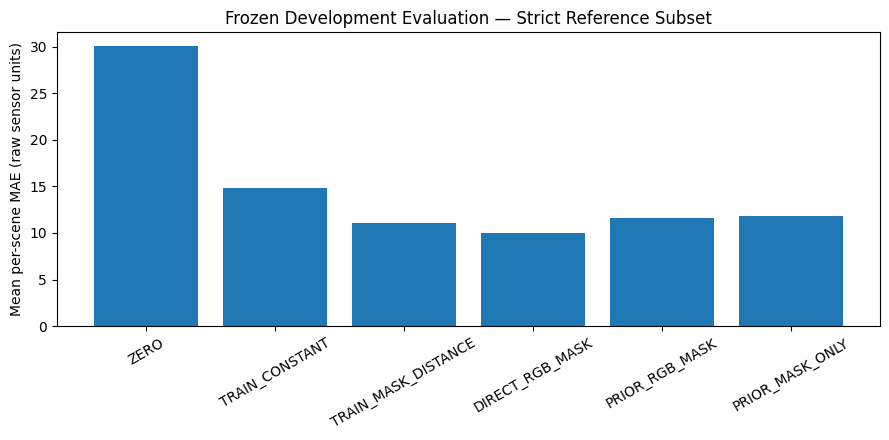


C3-13 SECTION 1 — FROZEN DEVELOPMENT EVALUATION COMPLETE
Development frames: 275
Eligibility counts: {'AUX_EXPERIMENTAL': 174, 'REVIEW': 23, 'ERROR': 5, 'STRICT': 72, 'QUARANTINED': 1}
Strict coverage: 26.2%
Quality flags: {'UNSTABLE_REFERENCE_HOLDOUT': 197, 'WEAK_ROAD_RELATIVE_SIGNAL': 23, 'AssertionError: ': 4, 'CROSS_ROLE_SIMILARITY_SUSPECT': 1, 'ValueError: No valid class-0 polygon': 1}

MODEL COMPARISON:
ZERO                   | MAE=30.039 RAW | D95 error=51.233 RAW | n=72
TRAIN_CONSTANT         | MAE=14.803 RAW | D95 error=25.436 RAW | n=72
TRAIN_MASK_DISTANCE    | MAE=11.067 RAW | D95 error=14.503 RAW | n=72
DIRECT_RGB_MASK        | MAE=9.951 RAW | D95 error=12.929 RAW | n=72
PRIOR_RGB_MASK         | MAE=11.592 RAW | D95 error=16.662 RAW | n=72
PRIOR_MASK_ONLY        | MAE=11.858 RAW | D95 error=16.969 RAW | n=72

Checkpoint integrity: PASS
Physical metric units certified: NO
Independent scene test completed: NO
Model retraining performed: NO

Saved:
/content/drive/MyDrive/crdl

In [3]:
# ============================================================
# CRDL C3-13 / SECTION 1
# FROZEN DEVELOPMENT EVALUATION
#
# PothRGBD temporal group 0002
# 275 provisional development samples
#
# NO TRAINING
# NO HYPERPARAMETER CHANGES
# NO PHYSICAL MILLIMETRE CLAIMS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt

import numpy as np
import torch
import csv
import json
import hashlib
import uuid
import os
import importlib.util
import matplotlib.pyplot as plt


# ============================================================
# 1. RESTORE EXACT GOOGLE DRIVE PATHS
# ============================================================

ROOT = Path("/content/drive/MyDrive")

if not ROOT.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT = (
    ROOT / "crdl_experiments"
    / "component3_fresh_v1"
)

DATA = (
    ROOT / "manushi_research_data"
    / "pothrgbd" / "PData-main"
)

PREV = (
    PROJECT / "04_geometry_targets"
    / "C3-11_section01_RAW_target_pilot_20261021T043311Z_367db5"
    / "C3-11_section04_weighted_feasibility_20261021T050356Z_383980"
)

C310 = (
    PROJECT / "07_evaluation"
    / "C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662"
    / "C3-10_section02_grouped_pilot_protocol_20261021T042524Z_735c9f"
)

TRAIN = (
    PROJECT / "05_training_runs"
    / "C3-12_section05_main_training_20261021T062404Z_3206b0"
)

ROLE = C310 / "PROVISIONAL_pilot_role_manifest.csv"

SUSPECTS = C310 / "cross_role_similarity_REVIEW.csv"

PROTO = PREV / "protocol.json"

LAB = PREV / "target_eligibility_manifest.csv"

CONFIG = TRAIN / "experiment_config.json"

MODSRC = TRAIN / "model_and_inference.py"

for p in [
    ROLE, SUSPECTS, PROTO, LAB, CONFIG, MODSRC
]:
    assert p.is_file(), f"Missing previous artifact: {p}"


# ============================================================
# 2. REPRODUCIBILITY HELPERS
# ============================================================

def readcsv(path):

    with path.open(
        newline="",
        encoding="utf-8"
    ) as f:
        return list(csv.DictReader(f))


def sha(path):

    h = hashlib.sha256()

    with path.open("rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def savejson(path, value):

    path.write_text(
        json.dumps(
            value,
            indent=2,
            allow_nan=False,
            default=str
        ),
        encoding="utf-8"
    )


def savecsv(path, records, columns=None):

    if not records and columns is None:
        return

    cols = columns or sorted(
        set().union(*(r.keys() for r in records))
    )

    with path.open(
        "w",
        newline="",
        encoding="utf-8"
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=cols
        )

        writer.writeheader()
        writer.writerows(records)


# ============================================================
# 3. VERIFY RESERVED DEVELOPMENT GROUP
# ============================================================

roles = readcsv(ROLE)

assert len(roles) == 996

assert len({
    r["sample_id"] for r in roles
}) == 996

excluded = {
    sid
    for r in readcsv(SUSPECTS)
    for sid in (
        r["sample_a"],
        r["sample_b"]
    )
}

dev = sorted(
    (
        r for r in roles
        if r["pilot_role"] == "PILOT_DEV_VAL"
    ),
    key=lambda r: r["sample_id"]
)

assert len(dev) == 275

assert all(
    r["temporal_burst_proxy"]
    == "POTHRGBD_TEMPORAL_0002"
    for r in dev
)


# ============================================================
# 4. VERIFY FROZEN TRAINING EVIDENCE
# ============================================================

cfg = json.loads(
    CONFIG.read_text(encoding="utf-8")
)

protocol = json.loads(
    PROTO.read_text(encoding="utf-8")
)

assert cfg["label_manifest_sha256"] == sha(LAB)
assert cfg["role_manifest_sha256"] == sha(ROLE)
assert cfg["protocol_sha256"] == sha(PROTO)
assert cfg["source_code_sha256"] == sha(MODSRC)

assert cfg["fit_n"] == 273
assert cfg["inner_strict_n"] == 5
assert cfg["physical_mm_certified"] is False

scale = float(cfg["scale_raw_fit_only"])

coef = cfg["mask_prior_coef_fit_only"]

assert scale > 0
assert len(coef) == 2


# ============================================================
# 5. VERIFY ORIGINAL REFERENCE-QUALITY THRESHOLDS
# ============================================================

EXPECTED = {
    "ring_inner_px": 8,
    "ring_outer_px": 55,
    "min_road_pixels": 2500,
    "max_road_sample": 16000,
    "min_mask_pixels": 200,
    "min_coverage": 0.90,
    "min_positive_fraction": 0.75,
    "min_signal_to_road": 1.5,
    "min_holdout_sectors": 4,
    "max_strict_holdout_to_signal": 0.5,
    "min_train_sector": 1500,
    "min_test_sector": 150,
    "min_downsample_valid_pixels": 60,
    "seed": 20261021,
    "irls_iterations": 8,
    "output_hw": [192, 256]
}

for key, value in EXPECTED.items():

    assert protocol[key] == value, (
        f"Frozen protocol changed: {key}"
    )

print("Original reference-quality protocol: VERIFIED")


# ============================================================
# 6. RECOVER TRAINING-ONLY CONSTANT BASELINE
# ============================================================

role_by_id = {
    r["sample_id"]: r
    for r in roles
}

fitstrict = [
    r for r in readcsv(LAB)
    if (
        r["tier"] == "STRICT"
        and role_by_id[
            r["sample_id"]
        ]["temporal_burst_proxy"]
        == "POTHRGBD_TEMPORAL_0004"
    )
]

assert len(fitstrict) == 79

medians = []

for r in fitstrict:

    relative = Path(
        r["target_relative_path"]
    )

    assert len(relative.parts) == 2
    assert relative.parts[0] == "targets"

    path = PREV / relative

    assert path.is_file()
    assert sha(path) == r["target_sha256"]

    with np.load(
        path,
        allow_pickle=False
    ) as archive:

        y = archive["target_raw"]

        m = archive["loss_mask"].astype(bool)

        medians.append(
            float(np.median(y[m]))
        )

constant = float(
    np.median(medians)
)

assert abs(
    constant - 26.306248664855957
) < 1e-3


# ============================================================
# 7. IMPORT PREVIOUSLY TRAINED MODEL IMPLEMENTATION
# ============================================================

spec = importlib.util.spec_from_file_location(
    "crdl_c313_frozen",
    MODSRC
)

mod = importlib.util.module_from_spec(spec)

spec.loader.exec_module(mod)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)


# ============================================================
# 8. COLD-LOAD ALL THREE FROZEN CHECKPOINTS
# ============================================================

models = {}

checkpoint_hashes = {}

for mode in cfg["modes"]:

    path = TRAIN / (
        mode.lower() + "_last.pt"
    )

    assert path.is_file()

    checkpoint_hashes[mode] = sha(path)

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    assert checkpoint["mode"] == mode

    assert checkpoint["epoch"] == cfg["epochs"]

    assert checkpoint["config_sha256"] == sha(CONFIG)

    assert abs(
        float(checkpoint["scale_raw"]) - scale
    ) < 1e-6

    network = mod.RoadRelativeCRDL(
        base=checkpoint["base"],
        mode=mode
    )

    network.load_state_dict(
        checkpoint["state_dict"],
        strict=True
    )

    models[mode] = network.to(device).eval()

    del checkpoint


# ============================================================
# 9. CREATE VERSIONED EVALUATION OUTPUT
# ============================================================

# For resuming after Colab restarts, set RESUME_RUN
# to the exact output folder previously printed.

RESUME_RUN = None

if RESUME_RUN is not None:

    RUN = Path(RESUME_RUN)

elif (
    "C313_RUN" in globals()
    and Path(C313_RUN).is_dir()
):

    RUN = Path(C313_RUN)

else:

    RUN = (
        PROJECT / "07_evaluation"
        / (
            "C3-13_section01_frozen_dev_"
            + datetime.now(
                timezone.utc
            ).strftime("%Y%m%dT%H%M%SZ_")
            + uuid.uuid4().hex[:6]
        )
    )

    RUN.mkdir(
        parents=True,
        exist_ok=False
    )

C313_RUN = RUN

assert RUN.parent.resolve() == (
    PROJECT / "07_evaluation"
).resolve()

for sub in (
    "cases",
    "strict_targets",
    "figures"
):

    (RUN / sub).mkdir(exist_ok=True)


# ============================================================
# 10. SAVE FROZEN EVALUATION RECEIPT
# ============================================================

receipt = {
    "stage": "C3-13_SECTION01",
    "role": "PILOT_DEV_VAL",
    "burst": "POTHRGBD_TEMPORAL_0002",
    "source_count": 275,
    "frozen_label_sha256": sha(PROTO),
    "training_config_sha256": sha(CONFIG),
    "checkpoints": checkpoint_hashes,
    "unit": "UNVERIFIED_RAW_AXIAL",
    "scene_independent": False,
    "physical_mm_validated": False,
    "candidate_overlap_quarantine": sorted(excluded),
    "trained_model_selection": False,
    "baseline_constant_fit_only_raw": constant,
    "mask_distance_coef_fit_only": coef
}

receipt_path = RUN / "protocol_receipt.json"

if receipt_path.exists():

    assert json.loads(
        receipt_path.read_text()
    ) == receipt

else:

    savejson(receipt_path, receipt)

print("\n" + "=" * 72)
print("CRDL C3-13 — FROZEN DEVELOPMENT EVALUATION")
print("=" * 72)

print("Source group 0002:", len(dev))

print(
    "Quarantined IDs in this group:",
    len(
        set(r["sample_id"] for r in dev)
        & excluded
    )
)

print("Models loaded:", list(models))

print("Device:", device)

print("Output:", RUN)


# ============================================================
# 11. DECODE YOLO SEGMENTATION POLYGONS
# ============================================================

def mask_from_yolo(path, w, h):

    canvas = Image.new(
        "L",
        (w, h),
        0
    )

    draw = ImageDraw.Draw(canvas)

    count = 0

    for lineno, line in enumerate(
        path.read_text(
            encoding="utf-8"
        ).splitlines(),
        1
    ):

        tokens = line.split()

        if not tokens:
            continue

        values = np.array(
            [float(x) for x in tokens],
            dtype=np.float64
        )

        valid = (
            len(values) >= 7
            and (len(values) - 1) % 2 == 0
            and np.isfinite(values).all()
            and values[0] == 0
            and np.all(
                (values[1:] >= 0)
                & (values[1:] <= 1)
            )
        )

        if not valid:
            raise ValueError(
                f"Invalid polygon at line {lineno}"
            )

        vertices = [
            (
                round(float(x) * (w - 1)),
                round(float(y) * (h - 1))
            )
            for x, y in values[1:].reshape(-1, 2)
        ]

        draw.polygon(
            vertices,
            fill=1
        )

        count += 1

    return np.asarray(
        canvas,
        dtype=bool
    ), count


# ============================================================
# 12. FROZEN ROBUST INVERSE-DEPTH REFERENCE
# ============================================================

def irls(u, v, z):

    A = np.stack(
        [
            np.ones_like(u),
            u,
            v
        ],
        axis=-1
    ).reshape(-1, 3)

    yy = (
        1.0
        / np.asarray(
            z,
            dtype=np.float64
        ).ravel()
    )

    if (
        len(yy) < 1500
        or np.linalg.matrix_rank(A) < 3
    ):

        raise ValueError(
            "Insufficient road-plane support"
        )

    c = np.linalg.lstsq(
        A,
        yy,
        rcond=None
    )[0]

    for _ in range(8):

        residual = yy - A @ c

        sigma = max(
            1.4826 * np.median(
                np.abs(
                    residual - np.median(residual)
                )
            ),
            1e-12
        )

        weights = np.sqrt(
            np.minimum(
                1.0,
                1.345 * sigma
                / (np.abs(residual) + 1e-12)
            )
        )

        c = np.linalg.lstsq(
            A * weights[:, None],
            yy * weights,
            rcond=None
        )[0]

    return c


# ============================================================
# 13. FROZEN VALIDITY-AWARE DOWNSAMPLING
# ============================================================

def box_resize(array):

    h, w = protocol["output_hw"]

    return np.asarray(
        Image.fromarray(
            np.asarray(
                array,
                dtype=np.float32
            )
        ).resize(
            (w, h),
            Image.Resampling.BOX
        ),
        dtype=np.float32
    )


# ============================================================
# 14. GENERATE DEVELOPMENT REFERENCE UNDER FROZEN RULES
# ============================================================

def build_reference(z, mask, sid):

    h, w = z.shape

    qa = {
        "sample_id": sid,
        "tier": "REVIEW",
        "flags": []
    }

    valid_depth = (
        np.isfinite(z)
        & (z > 0)
    )

    if mask.sum() < 200:

        qa["flags"] = ["FAIL_MASK"]

        return qa, None, None, None

    distance = distance_transform_edt(
        ~mask
    )

    ring = (
        (distance >= 8)
        & (distance <= 55)
        & valid_depth
    )

    qa["ring_valid_count"] = int(
        ring.sum()
    )

    if ring.sum() < 2500:

        qa["flags"] = ["FAIL_ROAD_SUPPORT"]

        return qa, None, None, None

    yy, xx = np.indices(
        (h, w)
    )

    u = 2 * (xx + 0.5) / w - 1

    v = 2 * (yy + 0.5) / h - 1

    sy, sx = np.where(ring)

    if len(sy) > 16000:

        rng = np.random.default_rng(
            20261021
            + int(
                sid.replace("_", "")
            ) % 1000000
        )

        pick = rng.choice(
            len(sy),
            size=16000,
            replace=False
        )

        sy, sx = sy[pick], sx[pick]

    c = irls(
        u[sy, sx],
        v[sy, sx],
        z[sy, sx]
    )

    inverse = (
        c[0]
        + c[1] * u
        + c[2] * v
    )

    good = (
        np.isfinite(inverse)
        & (inverse > 1e-10)
    )

    reference = np.full(
        z.shape,
        np.nan,
        dtype=np.float64
    )

    reference[good] = (
        1 / inverse[good]
    )

    inside = (
        mask & good & valid_depth
    )

    support = ring & good

    if (
        inside.sum() < 100
        or support.sum() < 1000
    ):

        qa["flags"] = ["FAIL_REFERENCE"]

        return qa, None, None, None

    residual = (
        z.astype(np.float64)
        - reference
    )

    signal = float(
        np.median(
            np.abs(
                residual[inside]
            )
        )
    )

    road_p95 = float(
        np.percentile(
            np.abs(
                residual[support]
            ),
            95
        )
    )

    positive = float(
        np.mean(
            residual[inside] > 0
        )
    )

    coverage = float(
        (valid_depth & mask).sum()
        / mask.sum()
    )

    # Four-sector spatial reference holdout.
    cy, cx = np.mean(
        np.where(mask),
        axis=1
    )

    sectors = (
        (sy >= cy).astype(int) * 2
        + (sx >= cx).astype(int)
    )

    errors = []

    for q in range(4):

        tr = sectors != q
        te = sectors == q

        if (
            tr.sum() < 1500
            or te.sum() < 150
        ):
            continue

        other = irls(
            u[sy[tr], sx[tr]],
            v[sy[tr], sx[tr]],
            z[sy[tr], sx[tr]]
        )

        inv2 = (
            other[0]
            + other[1] * u[
                sy[te], sx[te]
            ]
            + other[2] * v[
                sy[te], sx[te]
            ]
        )

        ok = (
            np.isfinite(inv2)
            & (inv2 > 1e-10)
        )

        if ok.sum() < 150:
            continue

        observed = z[
            sy[te][ok],
            sx[te][ok]
        ].astype(float)

        error = np.abs(
            observed - 1 / inv2[ok]
        )

        errors.append(
            float(
                np.percentile(
                    error,
                    95
                )
            )
        )

    ratio = signal / (
        road_p95 + 1e-9
    )

    holdout = (
        max(errors) / (signal + 1e-9)
        if errors
        else float("inf")
    )

    qa.update({
        "signal_raw": signal,
        "road_p95_raw": road_p95,
        "signal_ratio": ratio,
        "coverage": coverage,
        "positive_fraction": positive,
        "holdout_sector_count": len(errors),
        "holdout_to_signal": (
            float(holdout)
            if np.isfinite(holdout)
            else None
        )
    })

    flags = []

    if coverage < 0.90:

        flags.append(
            "LOW_VALID_DEPTH_COVERAGE"
        )

    if positive < 0.75:

        flags.append(
            "UNCERTAIN_DEPRESSION_SIGN"
        )

    if ratio < 1.5:

        flags.append(
            "WEAK_ROAD_RELATIVE_SIGNAL"
        )

    if (
        len(errors) < 4
        or holdout > 0.5
    ):

        flags.append(
            "UNSTABLE_REFERENCE_HOLDOUT"
        )

    qa["flags"] = flags

    if flags:

        if (
            flags == [
                "UNSTABLE_REFERENCE_HOLDOUT"
            ]
            and len(errors) == 4
            and np.isfinite(holdout)
            and holdout <= 2.0
        ):

            qa["tier"] = "AUX_EXPERIMENTAL"

        return qa, None, None, None

    # Original strict-target downsampling.
    h2, w2 = protocol["output_hw"]

    low_weight = box_resize(
        inside.astype(np.float32)
    )

    positive_residual = np.where(
        inside,
        np.maximum(residual, 0),
        0
    ).astype(np.float32)

    low_positive = box_resize(
        positive_residual
    )

    small_mask = np.asarray(
        Image.fromarray(
            mask.astype(np.uint8) * 255
        ).resize(
            (w2, h2),
            Image.Resampling.NEAREST
        )
    ) > 0

    loss_mask = (
        (low_weight >= 0.75)
        & small_mask
    )

    if loss_mask.sum() < 60:

        qa["flags"] = [
            "FAIL_DOWNSAMPLED_VALIDITY"
        ]

        return qa, None, None, None

    target = np.zeros(
        (h2, w2),
        dtype=np.float32
    )

    target[loss_mask] = (
        low_positive[loss_mask]
        / np.maximum(
            low_weight[loss_mask],
            1e-6
        )
    )

    if (
        not np.isfinite(target).all()
        or target.min() < 0
    ):

        qa["flags"] = [
            "FAIL_TARGET_NUMERIC"
        ]

        return qa, None, None, None

    qa["tier"] = "STRICT"

    qa["valid_loss_pixels"] = int(
        loss_mask.sum()
    )

    return qa, target, loss_mask, small_mask


# ============================================================
# 15. VERIFY REFERENCE IMPLEMENTATION AGAINST SAVED TARGETS
# ============================================================

# Important regression check:
# Before reading development depth, reconstruct two
# previously saved STRICT fitting targets.
#
# The new reference implementation must reproduce
# their existing masks and values.

for previous in fitstrict[:2]:

    sid = previous["sample_id"]

    role = role_by_id[sid]

    depth_path = Path(
        role["depth_path"]
    )

    label_path = Path(
        role["label_path"]
    )

    assert depth_path.parent.resolve() == (
        DATA / "depths"
    ).resolve()

    assert label_path.parent.resolve() == (
        DATA / "labels"
    ).resolve()

    z = np.load(
        depth_path,
        allow_pickle=False
    )

    old_mask, n = mask_from_yolo(
        label_path,
        z.shape[1],
        z.shape[0]
    )

    assert n > 0

    qa, target, valid, small = build_reference(
        z,
        old_mask,
        sid
    )

    assert qa["tier"] == "STRICT", (
        f"Reference QA divergence: {sid}"
    )

    old_path = (
        PREV / previous["target_relative_path"]
    )

    with np.load(
        old_path,
        allow_pickle=False
    ) as archive:

        assert np.array_equal(
            valid,
            archive["loss_mask"].astype(bool)
        )

        assert np.array_equal(
            small,
            archive["pothole_mask"].astype(bool)
        )

        assert np.allclose(
            target,
            archive["target_raw"],
            rtol=1e-5,
            atol=1e-4
        ), (
            f"Frozen target mismatch: {sid}"
        )

print(
    "Frozen reference regression test: PASS"
)


# ============================================================
# 16. COMMON EVALUATION METRICS
# ============================================================

def metrics(pred, target, valid):

    p = pred[valid].astype(
        np.float64
    )

    t = target[valid].astype(
        np.float64
    )

    error = p - t

    return {
        "mae_raw": float(
            np.abs(error).mean()
        ),
        "rmse_raw": float(
            np.sqrt(
                (error ** 2).mean()
            )
        ),
        "d95_abs_raw": float(
            abs(
                np.percentile(p, 95)
                - np.percentile(t, 95)
            )
        ),
        "bias_raw": float(
            error.mean()
        )
    }


# ============================================================
# 17. PROCESS THE DEVELOPMENT GROUP
# ============================================================

for idx, row in enumerate(
    dev,
    1
):

    sid = row["sample_id"]

    output_file = (
        RUN / "cases"
        / f"{sid}.json"
    )

    # Resume safely.
    if output_file.is_file():
        continue

    record = {
        "sample_id": sid,
        "role": "PILOT_DEV_VAL",
        "burst": "POTHRGBD_TEMPORAL_0002",
        "physical_units": "UNVERIFIED_RAW",
        "scene_independent": False,
        "scores": {}
    }

    try:

        if sid in excluded:

            record.update({
                "tier": "QUARANTINED",
                "flags": [
                    "CROSS_ROLE_SIMILARITY_SUSPECT"
                ]
            })

        else:

            rgb_path = Path(
                row["rgb_path"]
            )

            depth_path = Path(
                row["depth_path"]
            )

            label_path = Path(
                row["label_path"]
            )

            for path, folder in [
                (rgb_path, "images"),
                (depth_path, "depths"),
                (label_path, "labels")
            ]:

                assert path.is_file()
                assert not path.is_symlink()

                assert path.parent.resolve() == (
                    DATA / folder
                ).resolve()

            depth = np.load(
                depth_path,
                allow_pickle=False
            )

            assert depth.ndim == 2

            assert np.issubdtype(
                depth.dtype,
                np.number
            )

            with Image.open(rgb_path) as im:

                rgb = np.asarray(
                    im.convert("RGB")
                )

            assert depth.shape == rgb.shape[:2]

            mask, n_polygons = mask_from_yolo(
                label_path,
                depth.shape[1],
                depth.shape[0]
            )

            if n_polygons < 1:

                raise ValueError(
                    "No valid class-0 polygon"
                )

            qa, target, valid, small = (
                build_reference(
                    depth,
                    mask,
                    sid
                )
            )

            record.update(qa)

            if record["tier"] == "STRICT":

                # --------------------------------
                # Input preprocessing is from
                # the previously frozen model.
                # --------------------------------

                x, prior = mod.prepare_inputs(
                    rgb,
                    mask,
                    coef,
                    size_hw=(192, 256)
                )

                assert np.array_equal(
                    x[3].numpy().astype(bool),
                    small
                )

                predictions = {
                    "ZERO":
                        np.zeros_like(target),

                    "TRAIN_CONSTANT":
                        constant
                        * small.astype(np.float32),

                    "TRAIN_MASK_DISTANCE":
                        prior[0].numpy()
                }

                # --------------------------------
                # Frozen neural-network inference
                # --------------------------------

                with torch.inference_mode():

                    for mode, network in models.items():

                        log_prediction = network(
                            x[None].to(device),
                            prior[None].to(device),
                            scale
                        ).clamp(max=8)

                        predicted_raw = (
                            scale * torch.expm1(
                                log_prediction
                            )
                        )[0, 0].cpu().numpy()

                        assert np.isfinite(
                            predicted_raw
                        ).all()

                        assert (
                            predicted_raw >= 0
                        ).all()

                        predictions[mode] = predicted_raw

                record["scores"] = {
                    name: metrics(
                        prediction,
                        target,
                        valid
                    )
                    for name, prediction
                    in predictions.items()
                }

                # --------------------------------
                # Save exact accepted reference
                # --------------------------------

                target_path = (
                    RUN / "strict_targets"
                    / f"{sid}_target.npz"
                )

                np.savez_compressed(
                    target_path,
                    target_raw=target,
                    loss_mask=valid.astype(
                        np.uint8
                    ),
                    pothole_mask=small.astype(
                        np.uint8
                    )
                )

                record["strict_target_sha256"] = (
                    sha(target_path)
                )

                record["source_rgb_sha256"] = (
                    sha(rgb_path)
                )

                record["source_depth_sha256"] = (
                    sha(depth_path)
                )

                record["source_label_sha256"] = (
                    sha(label_path)
                )

    except Exception as error:

        record.update({
            "tier": "ERROR",
            "flags": [
                type(error).__name__
                + ": "
                + str(error)[:180]
            ],
            "scores": {}
        })

    # Save each completed sample immediately.
    temporary = output_file.with_suffix(
        ".tmp"
    )

    savejson(
        temporary,
        record
    )

    os.replace(
        temporary,
        output_file
    )

    if idx % 25 == 0:

        print(
            f"Processed {idx}/{len(dev)} | "
            f"{sid}: {record['tier']}",
            flush=True
        )


# ============================================================
# 18. AGGREGATE SAVED QA RECORDS
# ============================================================

records = [
    json.loads(
        p.read_text(
            encoding="utf-8"
        )
    )
    for p in sorted(
        (RUN / "cases").glob("*.json")
    )
]

assert len(records) == len(dev)

counts = dict(
    Counter(
        r["tier"]
        for r in records
    )
)

flags = dict(
    Counter(
        flag
        for r in records
        for flag in r.get(
            "flags", []
        )
    )
)


# ============================================================
# 19. GENERATE PER-SCENE EVALUATION TABLE
# ============================================================

per_scene = []

for rec in records:

    for method, score in rec.get(
        "scores", {}
    ).items():

        per_scene.append({
            "sample_id": rec["sample_id"],
            "method": method,
            **score
        })


savecsv(
    RUN / "per_case_qa.csv",
    [
        {
            key: (
                json.dumps(value)
                if isinstance(
                    value,
                    (dict, list)
                )
                else value
            )
            for key, value in r.items()
            if key != "scores"
        }
        for r in records
    ]
)

savecsv(
    RUN / "strict_per_scene_metrics.csv",
    per_scene,
    columns=[
        "sample_id",
        "method",
        "mae_raw",
        "rmse_raw",
        "d95_abs_raw",
        "bias_raw"
    ]
)


# ============================================================
# 20. COMMON STRICT-SCENE METRIC SUMMARY
# ============================================================

methods = [
    "ZERO",
    "TRAIN_CONSTANT",
    "TRAIN_MASK_DISTANCE"
] + list(models)

summary = {}

for method in methods:

    subset = [
        r for r in per_scene
        if r["method"] == method
    ]

    if not subset:
        continue

    summary[method] = {
        key: float(
            np.mean([
                r[key]
                for r in subset
            ])
        )
        for key in (
            "mae_raw",
            "rmse_raw",
            "d95_abs_raw",
            "bias_raw"
        )
    }

    summary[method][
        "n_strict_scenes"
    ] = len(subset)


# ============================================================
# 21. SAVE FINAL RESEARCH EVALUATION
# ============================================================

final = {
    "stage": "C3-13_SECTION01_FROZEN_DEV",
    "source_count": len(dev),
    "counts": counts,
    "flags": flags,
    "n_scored_strict": counts.get(
        "STRICT", 0
    ),
    "strict_coverage_of_all": (
        counts.get("STRICT", 0)
        / len(dev)
    ),
    "score_summary": summary,
    "quarantined": counts.get(
        "QUARANTINED", 0
    ),
    "scene_independence_verified": False,
    "metric_units_verified": False,
    "physically_validated_accuracy": False,
    "fit_or_model_updates": False,
    "limitations": (
        "Same-date provisional temporal group; "
        "raw axial reference-derived labels; "
        "scene independence unverified. "
        "Descriptive development evaluation only."
    )
}

savejson(
    RUN / "frozen_dev_summary.json",
    final
)


# ============================================================
# 22. PLOT COMMON DEVELOPMENT RESULTS
# ============================================================

if summary:

    fig, ax = plt.subplots(
        figsize=(9, 4.5)
    )

    names = list(summary)

    values = [
        summary[name]["mae_raw"]
        for name in names
    ]

    ax.bar(
        names,
        values
    )

    ax.set_ylabel(
        "Mean per-scene MAE (raw sensor units)"
    )

    ax.set_title(
        "Frozen Development Evaluation — "
        "Strict Reference Subset"
    )

    ax.tick_params(
        axis="x",
        rotation=30
    )

    fig.tight_layout()

    fig.savefig(
        RUN / "frozen_dev_mae.png",
        dpi=150
    )

    plt.show()

    plt.close(fig)


# ============================================================
# 23. ARTIFACT SHA256 MANIFEST
# ============================================================

receipts = []

for p in sorted(
    RUN.rglob("*")
):

    if (
        p.is_file()
        and p.name != "sha256_manifest.json"
    ):

        receipts.append({
            "relative_path": str(
                p.relative_to(RUN)
            ),
            "sha256": sha(p),
            "bytes": p.stat().st_size
        })

savejson(
    RUN / "sha256_manifest.json",
    receipts
)

assert all(
    sha(
        TRAIN / (
            mode.lower() + "_last.pt"
        )
    ) == checkpoint_hashes[mode]
    for mode in models
)


# ============================================================
# 24. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 72)
print(
    "C3-13 SECTION 1 — "
    "FROZEN DEVELOPMENT EVALUATION COMPLETE"
)
print("=" * 72)

print(
    "Development frames:",
    len(dev)
)

print(
    "Eligibility counts:",
    counts
)

print(
    "Strict coverage:",
    f"{100 * final['strict_coverage_of_all']:.1f}%"
)

print(
    "Quality flags:",
    flags
)

print("\nMODEL COMPARISON:")

for name, score in summary.items():

    print(
        f"{name:22s} | "
        f"MAE={score['mae_raw']:.3f} RAW | "
        f"D95 error={score['d95_abs_raw']:.3f} RAW | "
        f"n={score['n_strict_scenes']}"
    )

if not summary:
    print(
        "No strict-quality development references "
        "were available for numerical scoring."
    )

print("\nCheckpoint integrity: PASS")

print("Physical metric units certified: NO")

print("Independent scene test completed: NO")

print("Model retraining performed: NO")

print("\nSaved:")
print(RUN)

print("=" * 72)

In [4]:
# ================================================================
# CRDL COMPONENT 3 — C3-14 SECTION 1
# PAIRED MODEL SELECTION + BACKEND PROTOTYPE PACKAGE
#
# NO ADDITIONAL TRAINING
# NO UPLOADS OR FILE PICKERS
# NO PREVIOUS EXPERIMENTS OVERWRITTEN
#
# SELECTED MODEL: DEVELOPMENT MAE CRITERION
# PHYSICAL METRIC CLAIMS: DISABLED
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

import csv
import json
import hashlib
import uuid
import shutil
import sys
import importlib.util

import numpy as np
import torch


# ================================================================
# 1. RESTORE EXISTING GOOGLE DRIVE PATHS
# ================================================================

ROOT = Path("/content/drive/MyDrive")

if not ROOT.is_dir():

    from google.colab import drive

    drive.mount("/content/drive")

PROJECT = (
    ROOT
    / "crdl_experiments"
    / "component3_fresh_v1"
)

TRAIN = (
    PROJECT
    / "05_training_runs"
    / "C3-12_section05_main_training_20261021T062404Z_3206b0"
)

EVAL = (
    PROJECT
    / "07_evaluation"
    / "C3-13_section01_frozen_dev_20261021T063918Z_9fee2e"
)

ROLE = (
    PROJECT
    / "07_evaluation"
    / "C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662"
    / "C3-10_section02_grouped_pilot_protocol_20261021T042524Z_735c9f"
    / "PROVISIONAL_pilot_role_manifest.csv"
)

SCORES = EVAL / "strict_per_scene_metrics.csv"

QA = EVAL / "per_case_qa.csv"

CONFIG = TRAIN / "experiment_config.json"

ARCH = TRAIN / "model_and_inference.py"

for p in (SCORES, QA, CONFIG, ARCH, ROLE):

    assert p.is_file(), (
        f"Missing existing research file: {p}"
    )


# ================================================================
# 2. REPRODUCIBILITY UTILITIES
# ================================================================

def read_csv(path):

    with path.open(
        newline="",
        encoding="utf8"
    ) as f:

        return list(csv.DictReader(f))


def digest(path):

    h = hashlib.sha256()

    with Path(path).open("rb") as f:

        for block in iter(
            lambda: f.read(1048576),
            b""
        ):

            h.update(block)

    return h.hexdigest()


def write_json(path, obj):

    path.write_text(

        json.dumps(
            obj,
            indent=2,
            allow_nan=False
        ),

        encoding="utf8"
    )


def write_csv(path, rows, headers):

    with path.open(
        "w",
        newline="",
        encoding="utf8"
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=headers
        )

        writer.writeheader()

        writer.writerows(rows)


# ================================================================
# 3. VERIFY THE FROZEN DEVELOPMENT RESULTS
# ================================================================

scores = read_csv(SCORES)

qa = read_csv(QA)

roles = {

    r["sample_id"]: r

    for r in read_csv(ROLE)
}

methods = [

    "ZERO",
    "TRAIN_CONSTANT",
    "TRAIN_MASK_DISTANCE",
    "DIRECT_RGB_MASK",
    "PRIOR_RGB_MASK",
    "PRIOR_MASK_ONLY"
]

assert len(qa) == 275

assert len(roles) == 996

assert len(scores) == 72 * len(methods)

assert Counter(
    r["tier"] for r in qa
) == {

    "STRICT": 72,
    "AUX_EXPERIMENTAL": 174,
    "REVIEW": 23,
    "ERROR": 5,
    "QUARANTINED": 1
}


# ================================================================
# 4. VERIFY IDENTICAL EVALUATION EXAMPLES
# ================================================================

by_method = {

    m: {}

    for m in methods
}

for r in scores:

    method = r["method"]

    sid = r["sample_id"]

    assert method in by_method

    assert sid not in by_method[method]

    assert roles[sid]["pilot_role"] == (
        "PILOT_DEV_VAL"
    )

    assert roles[sid]["temporal_burst_proxy"] == (
        "POTHRGBD_TEMPORAL_0002"
    )

    by_method[method][sid] = {

        key: float(r[key])

        for key in (

            "mae_raw",
            "rmse_raw",
            "d95_abs_raw",
            "bias_raw"
        )
    }

common = set(
    by_method[methods[0]]
)

assert len(common) == 72

assert all(

    set(by_method[m]) == common

    for m in methods
)

assert common == {

    r["sample_id"]

    for r in qa

    if r["tier"] == "STRICT"
}


# ================================================================
# 5. SELECT PROVISIONAL DEVELOPMENT CANDIDATE
# ================================================================

mean_mae = {

    method: float(

        np.mean([

            by_method[method][sid]["mae_raw"]

            for sid in sorted(common)
        ])
    )

    for method in methods
}

trained_candidates = [

    "DIRECT_RGB_MASK",
    "PRIOR_RGB_MASK",
    "PRIOR_MASK_ONLY"
]

chosen = min(

    trained_candidates,

    key=lambda m: mean_mae[m]
)

assert chosen == "DIRECT_RGB_MASK", (

    f"Unexpected changed development selection: "
    f"{chosen}"
)


# ================================================================
# 6. PAIRED COMPARISON WITH MASK-DISTANCE BASELINE
# ================================================================

paired = []

for sid in sorted(common):

    baseline = by_method[
        "TRAIN_MASK_DISTANCE"
    ][sid]

    selected = by_method[chosen][sid]

    gain_mae = (

        baseline["mae_raw"]

        - selected["mae_raw"]
    )

    gain_d95 = (

        baseline["d95_abs_raw"]

        - selected["d95_abs_raw"]
    )

    # Exploratory temporal block proxy only.
    # Does not establish physical defect identity.
    minute = int(
        sid[11:13]
    )

    block = (

        sid[:11]

        + str(
            (minute // 15) * 15
        ).zfill(2)
    )

    paired.append({

        "sample_id": sid,

        "baseline_mae_raw":
            baseline["mae_raw"],

        "selected_mae_raw":
            selected["mae_raw"],

        "baseline_minus_selected_mae_raw":
            gain_mae,

        "baseline_d95_raw":
            baseline["d95_abs_raw"],

        "selected_d95_raw":
            selected["d95_abs_raw"],

        "baseline_minus_selected_d95_raw":
            gain_d95,

        "time_block_proxy_15min":
            block
    })


differences = np.array(

    [

        r["baseline_minus_selected_mae_raw"]

        for r in paired
    ],

    dtype=float
)

assert len(differences) == 72


# ================================================================
# 7. DESCRIPTIVE RESAMPLING SENSITIVITY
# ================================================================

# These intervals are illustrative.
# They are NOT independently valid
# inferential confidence intervals because
# physical scene identities remain unverified.

rng = np.random.default_rng(20261021)

frame_draws = np.mean(

    rng.choice(

        differences,

        size=(1500, len(differences)),

        replace=True
    ),

    axis=1
)

blocks = {}

for r in paired:

    key = r["time_block_proxy_15min"]

    blocks.setdefault(
        key,
        []
    ).append(

        r["baseline_minus_selected_mae_raw"]
    )

block_keys = sorted(blocks)

block_draws = []

for _ in range(1500):

    sampled = rng.choice(

        len(block_keys),

        size=len(block_keys),

        replace=True
    )

    values = [

        v

        for j in sampled

        for v in blocks[block_keys[j]]
    ]

    block_draws.append(

        float(np.mean(values))
    )


# ================================================================
# 8. BUILD THE RESEARCH SELECTION RECORD
# ================================================================

report = {

    "stage":
        "C3-14_SECTION01_PROVISIONAL_BUNDLE",

    "model_selection_basis":
        "Mean per-scene MAE on the same "
        "72 strict development references",

    "selected_model":
        chosen,

    "comparison":
        "TRAIN_MASK_DISTANCE",

    "selected_mean_mae_raw":
        mean_mae[chosen],

    "baseline_mean_mae_raw":
        mean_mae["TRAIN_MASK_DISTANCE"],

    "relative_mae_reduction_percent":

        100 * (

            mean_mae["TRAIN_MASK_DISTANCE"]

            - mean_mae[chosen]

        ) / mean_mae["TRAIN_MASK_DISTANCE"],

    "n_strict":
        len(paired),

    "n_dev_total":
        len(qa),

    "wins":
        int(np.count_nonzero(differences > 0)),

    "losses":
        int(np.count_nonzero(differences < 0)),

    "ties":
        int(np.count_nonzero(differences == 0)),

    "mean_paired_gain_raw":
        float(np.mean(differences)),

    "median_paired_gain_raw":
        float(np.median(differences)),

    "frame_bootstrap_illustrative_interval_RAW":

        [

            float(v)

            for v in np.percentile(

                frame_draws,

                [2.5, 97.5]
            )
        ],

    "temporal_block_illustrative_interval_RAW":

        [

            float(v)

            for v in np.percentile(

                block_draws,

                [2.5, 97.5]
            )
        ],

    "time_block_proxies":
        len(block_keys),

    "physical_defect_independence_verified":
        False,

    "inferential_confidence_interval_valid":
        False,

    "physical_scale_verified":
        False,

    "model_training_performed":
        False,

    "development_data_used_for_selection":
        True,

    "final_independent_test_performed":
        False,

    "reason":
        "Temporal frame correlation and "
        "actual independent defect groups "
        "remain unverified."
}


# ================================================================
# 9. CREATE A VERSIONED INTEGRATION BUNDLE
# ================================================================

RUN = (

    PROJECT

    / "08_integration"

    / (

        "C3-14_provisional_component3_"

        + datetime.now(
            timezone.utc
        ).strftime("%Y%m%dT%H%M%SZ_")

        + uuid.uuid4().hex[:6]
    )
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)

write_csv(

    RUN / "paired_selection_evidence.csv",

    paired,

    list(paired[0])
)

write_json(

    RUN / "selection_evidence.json",

    report
)


# ================================================================
# 10. KEEP ALL ERROR / QUARANTINE CASES TRACEABLE
# ================================================================

problem_cases = [

    {

        "sample_id":
            r["sample_id"],

        "tier":
            r["tier"],

        "flags":
            r.get("flags", "")
    }

    for r in qa

    if r["tier"] in (
        "ERROR",
        "QUARANTINED"
    )
]

write_csv(

    RUN / "development_errors_for_followup.csv",

    problem_cases,

    [
        "sample_id",
        "tier",
        "flags"
    ]
)


# ================================================================
# 11. LOAD THE ACTUAL TRAINED CHECKPOINT
# ================================================================

cfg = json.loads(

    CONFIG.read_text(
        encoding="utf8"
    )
)

ck_source = (

    TRAIN

    / (
        chosen.lower()
        + "_last.pt"
    )
)

assert ck_source.is_file()

ck_source_hash_before = digest(
    ck_source
)

ck = torch.load(

    ck_source,

    map_location="cpu",

    weights_only=True
)

assert ck["mode"] == chosen

assert ck["epoch"] == cfg["epochs"]

assert ck["physical_units_verified"] is False

assert ck["config_sha256"] == digest(CONFIG)

assert abs(

    float(ck["scale_raw"])

    - float(
        cfg["scale_raw_fit_only"]
    )

) < 1e-6


# ================================================================
# 12. SAVE THE ORIGINAL ARCHITECTURE
# ================================================================

shutil.copy2(

    ARCH,

    RUN / "model_and_inference.py"
)


# ================================================================
# 13. EXPORT THE INFERENCE-ONLY CHECKPOINT
# ================================================================

# Exclude optimizer state.
# Keep the actually trained weights.

ck_small = {

    "state_dict":
        ck["state_dict"],

    "mode":
        ck["mode"],

    "base":
        ck["base"],

    "epoch":
        ck["epoch"],

    "scale_raw":
        float(ck["scale_raw"]),

    "prior_coefficients":
        [
            float(x)
            for x in ck["prior_coefficients"]
        ],

    "physical_units_verified":
        False
}

torch.save(

    ck_small,

    RUN / "selected_model.pt"
)


# ================================================================
# 14. CREATE THE BACKEND INFERENCE SERVICE
# ================================================================

# This Python module is generated automatically
# inside Google Drive. No manual upload required.

SERVICE_SOURCE = r'''
from pathlib import Path
import json
import hashlib
import importlib.util

import numpy as np
import torch

from scipy.ndimage import label


def sha256(path):

    h = hashlib.sha256()

    with Path(path).open("rb") as f:

        for block in iter(
            lambda: f.read(1048576),
            b""
        ):
            h.update(block)

    return h.hexdigest()


class Component3Prototype:

    def __init__(self, bundle_path, device="cpu"):

        self.root = Path(bundle_path)

        meta = json.loads(
            (self.root / "bundle_config.json")
            .read_text(encoding="utf8")
        )

        self.meta = meta

        assert meta["physical_units_verified"] is False

        assert sha256(
            self.root / "selected_model.pt"
        ) == meta["selected_checkpoint_sha256"]

        assert sha256(
            self.root / "model_and_inference.py"
        ) == meta["architecture_sha256"]

        spec = importlib.util.spec_from_file_location(
            "crdl_bundle_model",
            self.root / "model_and_inference.py"
        )

        module = importlib.util.module_from_spec(spec)

        spec.loader.exec_module(module)

        self.module = module

        self.device = torch.device(device)

        ck = torch.load(
            self.root / "selected_model.pt",
            map_location="cpu",
            weights_only=True
        )

        assert ck["mode"] == meta["selected_mode"]

        self.scale_raw = float(ck["scale_raw"])

        self.prior_coef = ck["prior_coefficients"]

        self.model = module.RoadRelativeCRDL(
            base=ck["base"],
            mode=ck["mode"]
        )

        self.model.load_state_dict(
            ck["state_dict"],
            strict=True
        )

        self.model.to(self.device).eval()


    def predict(
        self,
        rgb,
        pothole_mask,
        crack_mask=None,
        include_map=False
    ):

        rgb = np.asarray(rgb)
        mask = np.asarray(pothole_mask)

        if (
            rgb.ndim != 3
            or rgb.shape[-1] != 3
            or rgb.dtype != np.uint8
        ):
            raise ValueError(
                "RGB must be HxWx3 uint8"
            )

        if mask.shape != rgb.shape[:2]:
            raise ValueError(
                "Pothole segmentation mask must align with RGB"
            )

        mask = (
            np.isfinite(mask)
            & (mask > 0)
        )

        # ----------------------------------------
        # Optional crack measurements (pixel only)
        # ----------------------------------------

        if crack_mask is not None:

            crack = np.asarray(crack_mask)

            if crack.shape != mask.shape:
                raise ValueError(
                    "Crack mask must align with RGB"
                )

            crack = (
                np.isfinite(crack)
                & (crack > 0)
            )

            comps = int(
                label(
                    crack,
                    np.ones(
                        (3, 3),
                        dtype=int
                    )
                )[1]
            )

            crack_result = {

                "crack_mask_area_px":
                    int(crack.sum()),

                "connected_components_8":
                    comps,

                "skeleton_length_px_approx":
                    None,

                "physical_length_mm":
                    None,

                "physical_width_mm":
                    None
            }

            try:

                from skimage.morphology import skeletonize

                sk = skeletonize(crack)

                edges = float(

                    (
                        sk[:, :-1]
                        & sk[:, 1:]
                    ).sum()

                    + (
                        sk[:-1, :]
                        & sk[1:, :]
                    ).sum()

                    + np.sqrt(2) * (
                        sk[:-1, :-1]
                        & sk[1:, 1:]
                    ).sum()

                    + np.sqrt(2) * (
                        sk[1:, :-1]
                        & sk[:-1, 1:]
                    ).sum()
                )

                crack_result[
                    "skeleton_length_px_approx"
                ] = edges

            except ImportError:

                pass

        else:

            crack_result = None

        # ----------------------------------------
        # Research reliability requirements
        # ----------------------------------------

        reasons = [

            "PHYSICAL_DEPTH_SCALE_UNVERIFIED",

            "SCENE_GENERALIZATION_UNVERIFIED",

            "REFERENCE_LABEL_COVERAGE_LIMITED",

            "UNCERTAINTY_NOT_CALIBRATED"
        ]

        result = {

            "schema_version":
                "crdl-c3/0.6-prototype",

            "model_version":
                self.meta["selected_mode"],

            "reliability_status":
                "REVIEW_ONLY",

            "reasons":
                reasons,

            "geometry_raw":
                None,

            "crack_geometry_px":
                crack_result,

            "physical_measurements": {

                "depth_d95_mm": None,
                "depth_max_mm": None,
                "area_m2": None,
                "volume_m3": None,
                "crack_length_mm": None
            },

            "severity": {

                "physical_level": None,
                "visual_level": None
            },

            "model_uncertainty":
                None
        }

        # ----------------------------------------
        # Empty mask safeguard
        # ----------------------------------------

        if not mask.any():

            result["reliability_status"] = (
                "UNSUPPORTED_EMPTY_MASK"
            )

            if include_map:

                result["raw_axial_depression_map"] = [

                    [0.0] * 256

                    for _ in range(192)
                ]

            return result

        # ----------------------------------------
        # Actual model inference
        # ----------------------------------------

        x, prior = self.module.prepare_inputs(

            rgb,
            mask,
            self.prior_coef,

            size_hw=(192, 256)
        )

        with torch.inference_mode():

            prediction = self.model(

                x[None].to(self.device),

                prior[None].to(self.device),

                self.scale_raw
            ).clamp(max=8)

            raw = (

                self.scale_raw

                * torch.expm1(prediction)

            )[0, 0].cpu().numpy().astype(
                np.float32
            )

        valid = (
            x[3].numpy() > 0
        )

        raw = np.where(
            valid,
            raw,
            0
        ).astype(np.float32)

        if (
            not np.isfinite(raw).all()
            or (raw < 0).any()
        ):
            raise RuntimeError(
                "Invalid model output"
            )

        values = raw[valid]

        result["geometry_raw"] = {

            "units":
                "UNVERIFIED_RAW_AXIAL_SENSOR_UNITS",

            "map_height":
                192,

            "map_width":
                256,

            "source_pothole_area_px":
                int(mask.sum()),

            "d95_raw":
                float(
                    np.percentile(
                        values,
                        95
                    )
                ),

            "mean_raw":
                float(values.mean()),

            "max_raw":
                float(values.max()),

            "trained_reference":
                "PothRGBD road-relative "
                "optical-axis residual"
        }

        if include_map:

            result["raw_axial_depression_map"] = (
                raw.tolist()
            )

        return result
'''

SERVICE_FILE = (
    RUN / "component3_service.py"
)

SERVICE_FILE.write_text(

    SERVICE_SOURCE,

    encoding="utf8"
)


# ================================================================
# 15. SAVE BUNDLE CONFIGURATION
# ================================================================

write_json(

    RUN / "bundle_config.json",

    {

        "bundle_version":
            "C3-14.1.0-development-prototype",

        "selected_mode":
            chosen,

        "source_training_checkpoint":
            str(ck_source),

        "source_training_checkpoint_sha256":
            digest(ck_source),

        "source_dev_metrics_sha256":
            digest(SCORES),

        "selected_checkpoint_sha256":
            digest(RUN / "selected_model.pt"),

        "architecture_sha256":
            digest(
                RUN / "model_and_inference.py"
            ),

        "input":
            "RGB uint8 HxWx3 and aligned "
            "binary pothole mask, optional "
            "crack mask",

        "output":
            "Raw optical-axis depression "
            "in unverified sensor units",

        "physical_units_verified":
            False,

        "road_normal_depth_verified":
            False,

        "severity_validated":
            False,

        "uncertainty_calibrated":
            False,

        "development_selected":
            True,

        "independent_scene_test_passed":
            False,

        "requires_component1_component2_handoff_test":
            True
    }
)


# ================================================================
# 16. COLD-LOAD THE NEW BACKEND BUNDLE
# ================================================================

spec = importlib.util.spec_from_file_location(

    "crdl_local_service",

    SERVICE_FILE
)

service_module = importlib.util.module_from_spec(
    spec
)

spec.loader.exec_module(
    service_module
)

service = service_module.Component3Prototype(

    RUN,

    device="cpu"
)


# ================================================================
# 17. SYNTHETIC END-TO-END INPUT SMOKE TEST
# ================================================================

# Synthetic masks verify software operation.
# They do not verify physical prediction accuracy.

xx, yy = np.meshgrid(

    np.arange(256),

    np.arange(192)
)

test_mask = (

    (
        (xx - 128) ** 2 / 45**2
    )

    + (
        (yy - 96) ** 2 / 32**2
    )

) < 1

test_rgb = np.zeros(

    (192, 256, 3),

    dtype=np.uint8
)

test_rgb[..., 0] = (
    xx % 256
).astype(np.uint8)

test_rgb[..., 1] = (
    yy % 192
).astype(np.uint8)

test_rgb[..., 2] = 60

test_crack = np.zeros(

    (192, 256),

    dtype=bool
)

test_crack[90, 100:140] = True


# ================================================================
# 18. VERIFY REAL MODEL INFERENCE
# ================================================================

output = service.predict(

    test_rgb,

    test_mask,

    crack_mask=test_crack,

    include_map=True
)

assert output["reliability_status"] == (
    "REVIEW_ONLY"
)

assert len(
    output["raw_axial_depression_map"]
) == 192

assert len(
    output["raw_axial_depression_map"][0]
) == 256

assert (

    output["geometry_raw"][
        "source_pothole_area_px"
    ]

    == int(test_mask.sum())
)

assert all(

    value is None

    for value in output[
        "physical_measurements"
    ].values()
)

assert output[
    "severity"
]["physical_level"] is None

predicted_array = np.array(

    output["raw_axial_depression_map"]
)

assert np.isfinite(
    predicted_array
).all()

assert (
    predicted_array >= 0
).all()

assert np.all(

    predicted_array[~test_mask] == 0
)


# ================================================================
# 19. VERIFY EMPTY-DEFECT ABSTENTION
# ================================================================

empty = service.predict(

    test_rgb,

    np.zeros_like(test_mask),

    include_map=False
)

assert empty["reliability_status"] == (
    "UNSUPPORTED_EMPTY_MASK"
)

assert empty[
    "physical_measurements"
]["area_m2"] is None


# ================================================================
# 20. SAVE TEST RESULTS
# ================================================================

write_json(

    RUN / "smoke_tests.json",

    {

        "cold_load_inference":
            "PASS",

        "real_trained_weights_used":
            True,

        "synthetic_aligned_input":
            "PASS",

        "optional_crack_input":
            "PASS",

        "empty_mask_abstention":
            "PASS",

        "no_fabricated_metric_fields":
            "PASS",

        "model_d95_raw_on_synthetic_input":

            output[
                "geometry_raw"
            ]["d95_raw"]
    }
)


# ================================================================
# 21. SAVE API / INTEGRATION CONTRACT
# ================================================================

write_json(

    RUN / "api_contract.json",

    {

        "schema_version":
            "crdl-c3/0.6-prototype",

        "interface":

            "Component3Prototype(bundle_path)"
            ".predict(rgb, pothole_mask, "
            "crack_mask=None, include_map=False)",

        "inputs": {

            "rgb":
                "HxWx3 uint8 RGB, not BGR",

            "pothole_mask":
                "HxW aligned binary mask",

            "crack_mask":
                "Optional HxW aligned crack mask"
        },

        "outputs": {

            "geometry_raw":
                "Raw optical-axis geometry summary",

            "raw_axial_depression_map":
                "Optional 192x256 array",

            "crack_geometry_px":
                "Pixel-domain crack geometry",

            "physical_measurements":
                "Null until calibration and validation",

            "severity":
                "Null until validated model/rules",

            "reliability_status":
                "REVIEW_ONLY or UNSUPPORTED_EMPTY_MASK"
        },

        "integration_scope":
            "Prototype Python handoff, "
            "not finished production API"
    }
)


# ================================================================
# 22. SAVE ENVIRONMENT EVIDENCE
# ================================================================

write_json(

    RUN / "environment.json",

    {

        "python":
            sys.version.split()[0],

        "torch":
            torch.__version__,

        "numpy":
            np.__version__,

        "source_bundle":
            "Frozen original training run"
    }
)


# ================================================================
# 23. SHA256 ARTIFACT MANIFEST
# ================================================================

receipts = []

for path in sorted(
    RUN.iterdir()
):

    if (

        path.is_file()

        and path.name
        != "sha256_manifest.json"
    ):

        receipts.append({

            "file":
                path.name,

            "bytes":
                path.stat().st_size,

            "sha256":
                digest(path)
        })

write_json(

    RUN / "sha256_manifest.json",

    receipts
)


# ================================================================
# 24. VERIFY ORIGINAL CHECKPOINT WAS NOT ALTERED
# ================================================================

assert digest(ck_source) == ck_source_hash_before, (
    "Original trained checkpoint changed"
)


# ================================================================
# 25. FINAL OUTPUT
# ================================================================

print("\n" + "=" * 72)

print(
    "C3-14 SECTION 1 — "
    "PAIRED SELECTION AND PROTOTYPE BUNDLE COMPLETE"
)

print("=" * 72)

print(
    "Chosen development candidate:",
    chosen
)

print(
    "Paired strict scenes:",
    len(paired)
)

print(
    "Wins:",
    report["wins"],

    "Losses:",
    report["losses"],

    "Ties:",
    report["ties"]
)

print(
    "Baseline minus model mean paired MAE:",
    round(
        report["mean_paired_gain_raw"],
        4
    ),
    "RAW"
)

print(
    "Mean MAE improvement vs mask prior:",
    round(
        report["relative_mae_reduction_percent"],
        2
    ),
    "%"
)

print(
    "Illustrative temporal-block interval:",
    report[
        "temporal_block_illustrative_interval_RAW"
    ]
)

print(
    "Error and quarantined QA cases:",
    len(problem_cases)
)

print(
    "Cold-load service smoke: PASS"
)

print(
    "Metric physical measures: UNAVAILABLE"
)

print(
    "Reliability status: REVIEW_ONLY"
)

print("\nBundle saved:")

print(RUN)

print("=" * 72)


C3-14 SECTION 1 — PAIRED SELECTION AND PROTOTYPE BUNDLE COMPLETE
Chosen development candidate: DIRECT_RGB_MASK
Paired strict scenes: 72
Wins: 45 Losses: 27 Ties: 0
Baseline minus model mean paired MAE: 1.1155 RAW
Mean MAE improvement vs mask prior: 10.08 %
Illustrative temporal-block interval: [0.4869883863833365, 1.6559149439109866]
Error and quarantined QA cases: 6
Cold-load service smoke: PASS
Metric physical measures: UNAVAILABLE
Reliability status: REVIEW_ONLY

Bundle saved:
/content/drive/MyDrive/crdl_experiments/component3_fresh_v1/08_integration/C3-14_provisional_component3_20261021T065928Z_c144de



CRDL C3-15 — DEPTH-FIRST ML BASELINE
Device: cuda
Training candidates: 273
Reserved strict references: 72
Output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-15_depth_first_baseline_20261021T071213Z_af6506
Loaded training depth 75/273
Loaded training depth 150/273
Loaded training depth 225/273
DEPTH_FIRST epoch 01/10 | loss=0.037115 | checkpoint saved
DEPTH_FIRST epoch 02/10 | loss=0.037072 | checkpoint saved
DEPTH_FIRST epoch 03/10 | loss=0.037226 | checkpoint saved
DEPTH_FIRST epoch 04/10 | loss=0.036970 | checkpoint saved
DEPTH_FIRST epoch 05/10 | loss=0.037053 | checkpoint saved
DEPTH_FIRST epoch 06/10 | loss=0.036932 | checkpoint saved
DEPTH_FIRST epoch 07/10 | loss=0.036701 | checkpoint saved
DEPTH_FIRST epoch 08/10 | loss=0.036719 | checkpoint saved
DEPTH_FIRST epoch 09/10 | loss=0.036844 | checkpoint saved
DEPTH_FIRST epoch 10/10 | loss=0.036707 | checkpoint saved

Cold-load checkpoint test: PASS
Evaluated 18/72
Evaluated 36/72
Evaluated 54/

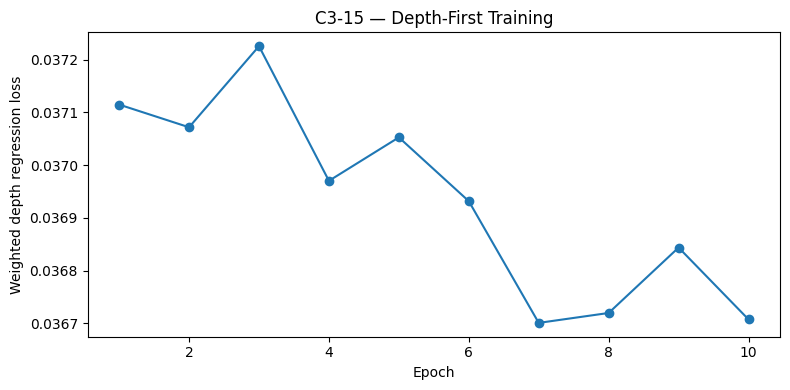

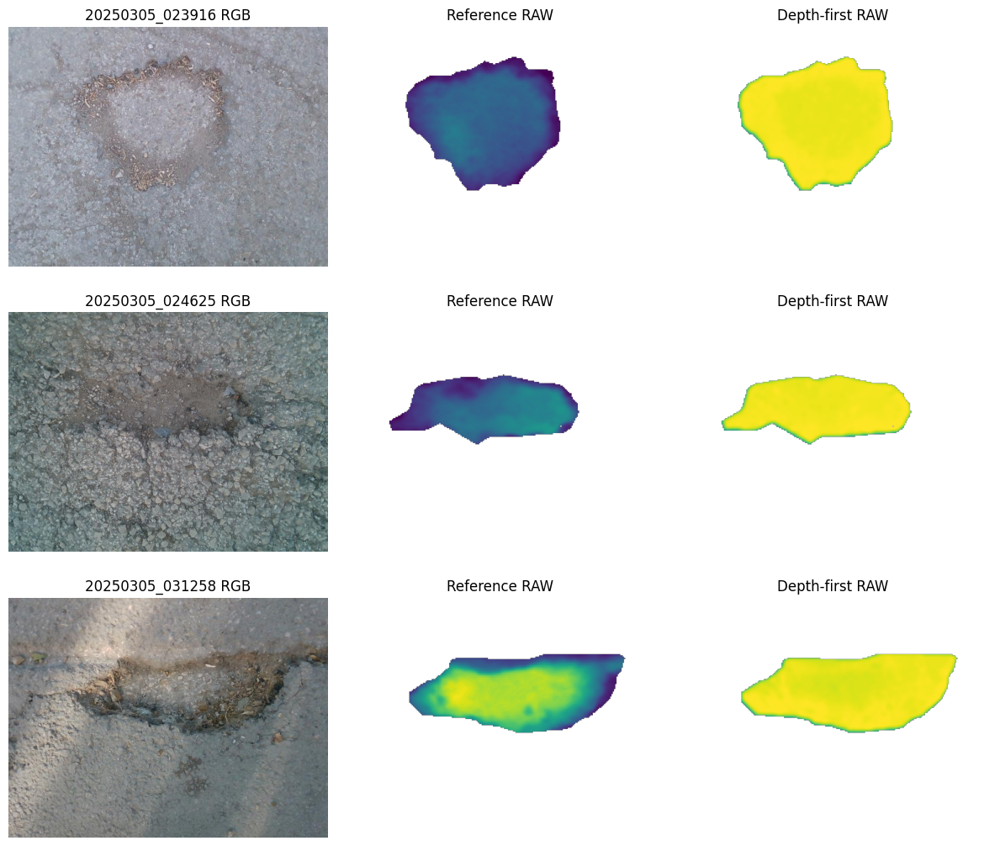


C3-15 — TRAINED DEPTH-FIRST BASELINE COMPLETE
Training epochs: 10
Training device: cuda
Development strict references: 72
Successfully compared: 72
Reconstruction failures: 0
Depth-first MAE RAW: 22.976944364100447
Direct CRDL MAE RAW, same cases: 9.951498845485133
Depth-first minus CRDL MAE RAW: 13.025445518615314
CRDL wins: 71
Depth-first wins: 1
Metric physical units verified: NO
Independent scene validation: NO
Original checkpoints unchanged: YES

Saved:
/content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-15_depth_first_baseline_20261021T071213Z_af6506


In [5]:
# ================================================================
# CRDL COMPONENT 3 — C3-15
# TRAINED DEPTH-FIRST BASELINE + DIRECT CRDL COMPARISON
# ONE CELL | NO UPLOADS | NO ORIGINAL FILES OVERWRITTEN
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import csv
import json
import hashlib
import uuid
import random
import os
import importlib.util

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader

from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt
import matplotlib.pyplot as plt


# ================================================================
# 1. RESTORE SAVED COMPONENT 3 EXPERIMENTS
# ================================================================

ROOT = Path("/content/drive/MyDrive")

if not ROOT.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT = (
    ROOT / "crdl_experiments"
    / "component3_fresh_v1"
)

DATA = (
    ROOT / "manushi_research_data"
    / "pothrgbd" / "PData-main"
)

C310 = (
    PROJECT / "07_evaluation"
    / "C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662"
    / "C3-10_section02_grouped_pilot_protocol_20261021T042524Z_735c9f"
)

LABEL_RUN = (
    PROJECT / "04_geometry_targets"
    / "C3-11_section01_RAW_target_pilot_20261021T043311Z_367db5"
    / "C3-11_section04_weighted_feasibility_20261021T050356Z_383980"
)

TRAIN = (
    PROJECT / "05_training_runs"
    / "C3-12_section05_main_training_20261021T062404Z_3206b0"
)

DEV = (
    PROJECT / "07_evaluation"
    / "C3-13_section01_frozen_dev_20261021T063918Z_9fee2e"
)

BUNDLE = (
    PROJECT / "08_integration"
    / "C3-14_provisional_component3_20261021T065928Z_c144de"
)

ROLE_FILE = C310 / "PROVISIONAL_pilot_role_manifest.csv"
LABEL_FILE = LABEL_RUN / "target_eligibility_manifest.csv"
DEV_SCORES = DEV / "strict_per_scene_metrics.csv"
DEV_TARGETS = DEV / "strict_targets"
SUSPECTS = C310 / "cross_role_similarity_REVIEW.csv"
TRAIN_CONFIG = TRAIN / "experiment_config.json"
DEV_QA = DEV / "per_case_qa.csv"

required = [
    ROLE_FILE, LABEL_FILE, DEV_SCORES,
    SUSPECTS, TRAIN_CONFIG, DEV_QA,
    BUNDLE / "selected_model.pt",
    BUNDLE / "bundle_config.json"
]

assert all(p.is_file() for p in required)


# ================================================================
# 2. HELPERS
# ================================================================

def readcsv(p):
    with p.open(newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))


def sha(p):
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for block in iter(
            lambda: f.read(1048576), b""
        ):
            h.update(block)
    return h.hexdigest()


def savejson(p, obj):
    p.write_text(
        json.dumps(
            obj, indent=2, allow_nan=False,
            default=str
        ),
        encoding="utf-8"
    )


def savecsv(p, records, columns):
    with p.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(
            f, fieldnames=columns
        )
        writer.writeheader()
        writer.writerows(records)


# ================================================================
# 3. VERIFY DATASET AND FREEZE EVALUATION REFERENCES
# ================================================================

roles = {
    r["sample_id"]: r
    for r in readcsv(ROLE_FILE)
}

labels = readcsv(LABEL_FILE)

assert len(roles) == 996
assert len(labels) == 489

assert Counter(r["tier"] for r in labels) == {
    "STRICT": 84,
    "AUX_EXPERIMENTAL": 212,
    "REVIEW": 193
}

quarantine = {
    sid
    for r in readcsv(SUSPECTS)
    for sid in (
        r["sample_a"],
        r["sample_b"]
    )
}

fit = sorted(
    [
        r for r in labels
        if r["tier"] in (
            "STRICT", "AUX_EXPERIMENTAL"
        )
        and roles[
            r["sample_id"]
        ]["temporal_burst_proxy"]
        == "POTHRGBD_TEMPORAL_0004"
        and r["sample_id"] not in quarantine
    ],
    key=lambda r: r["sample_id"]
)

assert len(fit) == 273

assert Counter(r["tier"] for r in fit) == {
    "STRICT": 79,
    "AUX_EXPERIMENTAL": 194
}

assert all(
    roles[r["sample_id"]]["pilot_role"]
    == "PILOT_TRAIN"
    for r in fit
)

reference_scores = readcsv(DEV_SCORES)

qa_lookup = {
    r["sample_id"]: r
    for r in readcsv(DEV_QA)
}

scored_ids = sorted({
    r["sample_id"]
    for r in reference_scores
    if r["method"] == "DIRECT_RGB_MASK"
})

assert len(scored_ids) == 72

assert all(
    roles[s]["pilot_role"] == "PILOT_DEV_VAL"
    and qa_lookup[s]["tier"] == "STRICT"
    for s in scored_ids
)

train_cfg = json.loads(
    TRAIN_CONFIG.read_text()
)

assert train_cfg["fit_n"] == 273

bundle_cfg = json.loads(
    (BUNDLE / "bundle_config.json").read_text()
)

assert bundle_cfg["selected_mode"] == "DIRECT_RGB_MASK"
assert bundle_cfg["physical_units_verified"] is False

assert sha(
    BUNDLE / "selected_model.pt"
) == bundle_cfg["selected_checkpoint_sha256"]

source_hashes = {
    "roles": sha(ROLE_FILE),
    "labels": sha(LABEL_FILE),
    "dev_scores": sha(DEV_SCORES),
    "selected_model": sha(
        BUNDLE / "selected_model.pt"
    )
}


# ================================================================
# 4. TRAINING AND RESUME CONFIGURATION
# ================================================================

SEED = 101
EPOCHS = 10
BATCH = 8

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

if DEVICE.type == "cpu":
    torch.set_num_threads(
        min(4, os.cpu_count() or 2)
    )

# To resume after a Colab restart, paste the exact
# printed output folder path below instead of None.
RESUME_RUN = None

if RESUME_RUN is not None:
    RUN = Path(RESUME_RUN)

elif (
    "C315_RUN" in globals()
    and Path(C315_RUN).is_dir()
):
    RUN = Path(C315_RUN)

else:
    RUN = (
        PROJECT / "05_training_runs"
        / (
            "C3-15_depth_first_baseline_"
            + datetime.now(
                timezone.utc
            ).strftime("%Y%m%dT%H%M%SZ_")
            + uuid.uuid4().hex[:6]
        )
    )

    RUN.mkdir(
        parents=True,
        exist_ok=False
    )

C315_RUN = RUN

assert RUN.parent.resolve() == (
    PROJECT / "05_training_runs"
).resolve()

print("\n" + "=" * 70)
print("CRDL C3-15 — DEPTH-FIRST ML BASELINE")
print("=" * 70)
print("Device:", DEVICE)
print("Training candidates:", len(fit))
print("Reserved strict references:", len(scored_ids))
print("Output:", RUN)


# ================================================================
# 5. CREATE TRAINABLE MODEL AND SAVED INFERENCE SOURCE
# ================================================================

MODEL_SOURCE = r'''
import numpy as np
import torch

from torch import nn
from torch.nn import functional as F
from PIL import Image


class Block(nn.Module):

    def __init__(self, a, b):
        super().__init__()

        self.seq = nn.Sequential(
            nn.Conv2d(a, b, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(b, b, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.seq(x)


class DepthFirst(nn.Module):

    def __init__(self, base=16):
        super().__init__()

        self.e1 = Block(4, base)
        self.e2 = Block(base, base * 2)
        self.mid = Block(base * 2, base * 4)

        self.d2 = Block(base * 6, base * 2)
        self.d1 = Block(base * 3, base)

        self.head = nn.Conv2d(base, 1, 1)

        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x):

        a = self.e1(x)

        b = self.e2(
            F.avg_pool2d(a, 2)
        )

        m = self.mid(
            F.avg_pool2d(b, 2)
        )

        c = self.d2(
            torch.cat([
                b,
                F.interpolate(
                    m,
                    size=b.shape[-2:],
                    mode="bilinear",
                    align_corners=False
                )
            ], dim=1)
        )

        d = self.d1(
            torch.cat([
                a,
                F.interpolate(
                    c,
                    size=a.shape[-2:],
                    mode="bilinear",
                    align_corners=False
                )
            ], dim=1)
        )

        return F.softplus(self.head(d))


def prepare(rgb, mask):

    rgb = np.asarray(rgb)
    mask = np.asarray(mask)

    if (
        rgb.ndim != 3
        or rgb.shape[-1] != 3
        or rgb.dtype != np.uint8
        or mask.shape != rgb.shape[:2]
    ):
        raise ValueError(
            "Expected uint8 RGB and aligned mask"
        )

    image = np.asarray(
        Image.fromarray(rgb).resize(
            (256, 192),
            Image.Resampling.BILINEAR
        ),
        dtype=np.float32
    ) / 255.0

    binary = np.asarray(
        Image.fromarray(
            (mask > 0).astype(np.uint8) * 255
        ).resize(
            (256, 192),
            Image.Resampling.NEAREST
        ),
        dtype=np.float32
    ) / 255.0

    x = np.concatenate([
        image.transpose(2, 0, 1),
        binary[None]
    ], axis=0)

    return torch.from_numpy(x).float()


def infer_sensor_raw(
    model, rgb, mask, raw_scale, device="cpu"
):

    x = prepare(
        rgb, mask
    )[None].to(device)

    model.eval()

    with torch.inference_mode():

        depth_log = model(x).clamp(max=8)

        depth_raw = (
            float(raw_scale)
            * torch.expm1(depth_log)
        )[0, 0].cpu().numpy()

    return depth_raw.astype(np.float32)
'''

MODEL_FILE = RUN / "depth_first_model.py"

if MODEL_FILE.exists():
    assert MODEL_FILE.read_text() == MODEL_SOURCE

else:
    MODEL_FILE.write_text(
        MODEL_SOURCE,
        encoding="utf-8"
    )

spec = importlib.util.spec_from_file_location(
    "crdl_depth_first_module",
    MODEL_FILE
)

mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)


# ================================================================
# 6. VALIDITY-AWARE SENSOR DEPTH RESIZING
# ================================================================

def box_resize(arr):

    return np.asarray(
        Image.fromarray(
            np.asarray(
                arr,
                dtype=np.float32
            )
        ).resize(
            (256, 192),
            Image.Resampling.BOX
        ),
        dtype=np.float32
    )


# ================================================================
# 7. PRELOAD ONLY TRAINING-GROUP RAW SENSOR DEPTHS
# ================================================================

fit_data = []
training_depth_scales = []

for i, row in enumerate(fit, 1):

    sid = row["sample_id"]
    role = roles[sid]

    rgb_path = Path(
        role["rgb_path"]
    )

    depth_path = Path(
        role["depth_path"]
    )

    for p, folder in [
        (rgb_path, "images"),
        (depth_path, "depths")
    ]:

        assert p.is_file()
        assert not p.is_symlink()

        assert p.parent.resolve() == (
            DATA / folder
        ).resolve()

    with Image.open(rgb_path) as im:
        rgb = np.asarray(
            im.convert("RGB")
        )

    depth = np.load(
        depth_path,
        allow_pickle=False
    )

    assert depth.ndim == 2
    assert depth.shape == rgb.shape[:2]

    valid = (
        np.isfinite(depth)
        & (depth > 0)
    )

    assert valid.sum() > 2000

    relative = Path(
        row["target_relative_path"]
    )

    assert len(relative.parts) == 2
    assert relative.parts[0] == "targets"

    target_path = LABEL_RUN / relative

    assert sha(target_path) == (
        row["target_sha256"]
    )

    with np.load(
        target_path,
        allow_pickle=False
    ) as z:

        small_mask = z[
            "pothole_mask"
        ].astype(bool)

        weights = z[
            "loss_weight"
        ].astype(np.float32)

        supervised = z[
            "loss_mask"
        ].astype(bool)

    assert small_mask.shape == (192, 256)
    assert supervised.sum() > 0

    reliability = float(
        np.median(
            weights[supervised]
        )
    )

    assert 0.24 <= reliability <= 1.001

    resized_rgb = np.asarray(
        Image.fromarray(rgb).resize(
            (256, 192),
            Image.Resampling.BILINEAR
        ),
        dtype=np.float32
    ) / 255.0

    x = np.concatenate([
        resized_rgb.transpose(2, 0, 1),
        small_mask[None].astype(np.float32)
    ], axis=0)

    weighted_depth = box_resize(
        np.where(valid, depth, 0)
    )

    low_valid_fraction = box_resize(
        valid.astype(np.float32)
    )

    low_valid = (
        low_valid_fraction >= 0.75
    )

    low_depth = np.zeros_like(
        weighted_depth
    )

    low_depth[low_valid] = (
        weighted_depth[low_valid]
        / np.maximum(
            low_valid_fraction[low_valid],
            1e-6
        )
    )

    assert low_valid.sum() > 1000
    assert np.isfinite(low_depth).all()

    training_depth_scales.append(
        float(
            np.median(
                low_depth[low_valid]
            )
        )
    )

    fit_data.append({
        "sid": sid,
        "x": x,
        "depth": low_depth,
        "valid": low_valid,
        "reliability": reliability
    })

    if i % 75 == 0:
        print(
            f"Loaded training depth {i}/{len(fit)}",
            flush=True
        )


DEPTH_SCALE = float(
    np.median(training_depth_scales)
)

assert DEPTH_SCALE > 0
assert len(fit_data) == 273


# ================================================================
# 8. FREEZE TRAINING PROTOCOL
# ================================================================

PROTOCOL = {
    "stage": "C3-15_DEPTH_FIRST_BASELINE",
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH,
    "learning_rate": 0.001,
    "fitting_examples": 273,
    "fitting_burst": "POTHRGBD_TEMPORAL_0004",
    "depth_scale_raw": DEPTH_SCALE,
    "architecture_sha256": sha(MODEL_FILE),
    "source_hashes": source_hashes,
    "target_units": "UNVERIFIED_RAW_SENSOR",
    "development_strict_references": 72,
    "checkpoint_selection": "FIXED_LAST_EPOCH",
    "physical_units_verified": False
}

PROTOCOL_FILE = RUN / "training_protocol.json"

if PROTOCOL_FILE.exists():

    saved = json.loads(
        PROTOCOL_FILE.read_text()
    )

    assert saved == PROTOCOL

else:
    savejson(PROTOCOL_FILE, PROTOCOL)


# ================================================================
# 9. PYTORCH DEPTH-FIRST DATASET
# ================================================================

class DepthDataset(Dataset):

    def __len__(self):
        return len(fit_data)

    def __getitem__(self, index):

        item = fit_data[index]

        y = np.log1p(
            item["depth"] / DEPTH_SCALE
        ).astype(np.float32)

        return (
            torch.from_numpy(item["x"]),

            torch.from_numpy(y[None]),

            torch.from_numpy(
                item["valid"][None].astype(np.float32)
            ),

            torch.tensor(
                item["reliability"],
                dtype=torch.float32
            )
        )


# ================================================================
# 10. TRAIN THE ACTUAL DEPTH-FIRST NETWORK
# ================================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

network = mod.DepthFirst(
    base=16
).to(DEVICE)

optimizer = torch.optim.AdamW(
    network.parameters(),
    lr=0.001
)

CHECKPOINT = RUN / "depth_first_last.pt"
HISTORY_FILE = RUN / "training_history.csv"

start_epoch = 1

if CHECKPOINT.exists():

    saved = torch.load(
        CHECKPOINT,
        map_location="cpu",
        weights_only=True
    )

    assert (
        saved["training_protocol_hash"]
        == sha(PROTOCOL_FILE)
    )

    network.load_state_dict(
        saved["state_dict"],
        strict=True
    )

    optimizer.load_state_dict(
        saved["optimizer"]
    )

    for state in optimizer.state.values():
        for key, value in state.items():
            if isinstance(value, torch.Tensor):
                state[key] = value.to(DEVICE)

    start_epoch = int(
        saved["epoch"]
    ) + 1

    print(
        "Resuming after epoch:",
        start_epoch - 1
    )


for epoch in range(
    start_epoch,
    EPOCHS + 1
):

    network.train()

    total = 0.0
    observed = 0

    loader = DataLoader(
        DepthDataset(),
        batch_size=BATCH,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(
            SEED + epoch
        )
    )

    for x, y, valid, reliability in loader:

        x = x.to(DEVICE)
        y = y.to(DEVICE)
        valid = valid.to(DEVICE)
        reliability = reliability.to(DEVICE)

        optimizer.zero_grad(
            set_to_none=True
        )

        prediction = network(x)

        pixel_loss = F.smooth_l1_loss(
            prediction,
            y,
            beta=0.25,
            reduction="none"
        )

        # Valid full-sensor supervision.
        # Additional weight inside pothole masks.
        focus = (
            1.0 + x[:, 3:4]
        )

        per_image = (
            (
                pixel_loss * valid * focus
            ).flatten(1).sum(1)
            /
            (
                valid * focus
            ).flatten(1).sum(1).clamp(min=1)
        )

        # The auxiliary sample reliability factor
        # is preserved rather than normalized away.
        loss = (
            per_image * reliability
        ).mean()

        assert bool(torch.isfinite(loss))

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            network.parameters(),
            5.0
        )

        optimizer.step()

        total += (
            float(loss.item()) * len(x)
        )

        observed += len(x)

    epoch_loss = total / observed

    history = (
        readcsv(HISTORY_FILE)
        if HISTORY_FILE.exists()
        else []
    )

    history = [
        r for r in history
        if int(r["epoch"]) != epoch
    ]

    history.append({
        "epoch": epoch,
        "train_weighted_huber": epoch_loss,
        "samples": observed
    })

    history.sort(
        key=lambda r: int(r["epoch"])
    )

    savecsv(
        HISTORY_FILE,
        history,
        [
            "epoch",
            "train_weighted_huber",
            "samples"
        ]
    )

    temporary = RUN / "depth_first_last.pt.tmp"

    torch.save({
        "state_dict": network.state_dict(),
        "optimizer": optimizer.state_dict(),
        "epoch": epoch,
        "base": 16,
        "depth_scale_raw": DEPTH_SCALE,
        "training_protocol_hash": sha(PROTOCOL_FILE),
        "metric_verified": False
    }, temporary)

    os.replace(
        temporary,
        CHECKPOINT
    )

    print(
        f"DEPTH_FIRST epoch {epoch:02d}/{EPOCHS} "
        f"| loss={epoch_loss:.6f} | checkpoint saved",
        flush=True
    )


# ================================================================
# 11. COLD-LOAD THE TRAINED DEPTH-FIRST NETWORK
# ================================================================

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["epoch"] == EPOCHS

reloaded = mod.DepthFirst(
    base=checkpoint["base"]
).to(DEVICE)

reloaded.load_state_dict(
    checkpoint["state_dict"],
    strict=True
)

network.eval()
reloaded.eval()

with torch.inference_mode():

    sample = torch.from_numpy(
        fit_data[0]["x"]
    )[None].to(DEVICE)

    difference = (
        network(sample) - reloaded(sample)
    ).abs().max().item()

assert difference < 1e-6

print("\nCold-load checkpoint test: PASS")


# ================================================================
# 12. RECONSTRUCT ROAD-RELATIVE GEOMETRY
#     USING PREDICTED DEPTH ONLY
# ================================================================

def predicted_road_residual(depth_small, mask):

    h, w = mask.shape

    full_depth = np.asarray(
        Image.fromarray(
            depth_small.astype(np.float32)
        ).resize(
            (w, h),
            Image.Resampling.BILINEAR
        ),
        dtype=np.float64
    )

    distance = distance_transform_edt(
        ~mask
    )

    ring = (
        (distance >= 8)
        & (distance <= 55)
        & np.isfinite(full_depth)
        & (full_depth > 0)
    )

    sy, sx = np.where(ring)

    if len(sy) < 2500:
        raise ValueError(
            "Insufficient predicted road support"
        )

    if len(sy) > 16000:

        pick = np.random.default_rng(
            SEED
        ).choice(
            len(sy),
            16000,
            replace=False
        )

        sy, sx = sy[pick], sx[pick]

    u = 2 * (sx + 0.5) / w - 1
    v = 2 * (sy + 0.5) / h - 1

    A = np.column_stack([
        np.ones_like(u),
        u,
        v
    ])

    observations = (
        1.0 / full_depth[sy, sx]
    )

    coefficients = np.linalg.lstsq(
        A,
        observations,
        rcond=None
    )[0]

    # Robust road plane from predicted depth.
    for _ in range(8):

        error = (
            observations - A @ coefficients
        )

        sigma = max(
            1.4826 * np.median(
                np.abs(
                    error - np.median(error)
                )
            ),
            1e-12
        )

        weights = np.sqrt(
            np.minimum(
                1.0,
                1.345 * sigma
                / (np.abs(error) + 1e-12)
            )
        )

        coefficients = np.linalg.lstsq(
            A * weights[:, None],
            observations * weights,
            rcond=None
        )[0]

    yy, xx = np.indices(
        mask.shape
    )

    inverse = (
        coefficients[0]
        + coefficients[1] * (
            2 * (xx + 0.5) / w - 1
        )
        + coefficients[2] * (
            2 * (yy + 0.5) / h - 1
        )
    )

    if (
        not np.isfinite(inverse[mask]).all()
        or (inverse[mask] <= 1e-10).any()
    ):
        raise ValueError(
            "Invalid predicted road reference"
        )

    road = (
        1.0 / np.maximum(inverse, 1e-10)
    )

    positive = np.where(
        mask,
        np.maximum(
            full_depth - road,
            0
        ),
        0
    ).astype(np.float32)

    low_positive = box_resize(positive)

    low_mask = np.asarray(
        Image.fromarray(
            mask.astype(np.uint8) * 255
        ).resize(
            (256, 192),
            Image.Resampling.NEAREST
        )
    ) > 0

    low_weight = box_resize(
        mask.astype(np.float32)
    )

    output = np.zeros(
        (192, 256),
        dtype=np.float32
    )

    output[low_mask] = (
        low_positive[low_mask]
        / np.maximum(
            low_weight[low_mask],
            1e-6
        )
    )

    assert np.isfinite(output).all()
    assert (output >= 0).all()

    return output


# ================================================================
# 13. EVALUATE THE SAME 72 STRICT REFERENCES
# ================================================================

scores = []
failures = []
previews = []

for i, sid in enumerate(scored_ids, 1):

    role = roles[sid]

    rgb_path = Path(
        role["rgb_path"]
    )

    label_path = Path(
        role["label_path"]
    )

    assert rgb_path.parent.resolve() == (
        DATA / "images"
    ).resolve()

    assert label_path.parent.resolve() == (
        DATA / "labels"
    ).resolve()

    with Image.open(rgb_path) as im:
        rgb = np.asarray(
            im.convert("RGB")
        )

    reference_path = (
        DEV_TARGETS / f"{sid}_target.npz"
    )

    assert reference_path.is_file()

    assert sha(reference_path) == (
        qa_lookup[sid]["strict_target_sha256"]
    )

    with np.load(
        reference_path,
        allow_pickle=False
    ) as archive:

        reference = np.asarray(
            archive["target_raw"],
            dtype=np.float32
        )

        valid = np.asarray(
            archive["loss_mask"],
            dtype=bool
        )

        small_mask = np.asarray(
            archive["pothole_mask"],
            dtype=bool
        )

    # Recover the full-resolution pothole mask
    # from the same existing YOLO segmentation.
    canvas = Image.new(
        "L",
        (rgb.shape[1], rgb.shape[0]),
        0
    )

    draw = ImageDraw.Draw(canvas)

    for line in label_path.read_text().splitlines():

        a = np.fromstring(
            line,
            sep=" "
        )

        if (
            len(a) >= 7
            and (len(a) - 1) % 2 == 0
            and a[0] == 0
            and np.isfinite(a).all()
        ):

            points = a[1:].reshape(-1, 2)

            assert (
                (points >= 0).all()
                and (points <= 1).all()
            )

            vertices = [
                (
                    round(
                        float(px) * (rgb.shape[1] - 1)
                    ),
                    round(
                        float(py) * (rgb.shape[0] - 1)
                    )
                )
                for px, py in points
            ]

            draw.polygon(
                vertices,
                fill=1
            )

    mask = np.asarray(
        canvas,
        dtype=bool
    )

    assert mask.sum() > 0

    try:

        # Predict camera-centred depth.
        predicted_depth = mod.infer_sensor_raw(
            reloaded,
            rgb,
            mask,
            DEPTH_SCALE,
            DEVICE
        )

        # Reconstruct a road-relative residual
        # using the predicted depth, not GT depth.
        predicted_geometry = predicted_road_residual(
            predicted_depth,
            mask
        )

        p = predicted_geometry[valid].astype(float)
        t = reference[valid].astype(float)

        error = p - t

        scores.append({
            "sample_id": sid,
            "mae_raw": float(
                np.mean(np.abs(error))
            ),
            "rmse_raw": float(
                np.sqrt(np.mean(error ** 2))
            ),
            "d95_abs_raw": float(
                abs(
                    np.percentile(p, 95)
                    - np.percentile(t, 95)
                )
            ),
            "bias_raw": float(
                error.mean()
            )
        })

        if len(previews) < 3:
            previews.append((
                sid,
                rgb,
                reference,
                predicted_geometry,
                valid
            ))

    except Exception as exc:

        failures.append({
            "sample_id": sid,
            "error": (
                type(exc).__name__
                + ": " + str(exc)[:180]
            )
        })

    if i % 18 == 0:
        print(
            f"Evaluated {i}/{len(scored_ids)}",
            flush=True
        )


# ================================================================
# 14. COMPARE DEPTH-FIRST WITH FROZEN DIRECT CRDL
# ================================================================

savecsv(
    RUN / "depth_first_per_scene.csv",
    scores,
    [
        "sample_id",
        "mae_raw",
        "rmse_raw",
        "d95_abs_raw",
        "bias_raw"
    ]
)

savecsv(
    RUN / "geometry_reconstruction_errors.csv",
    failures,
    ["sample_id", "error"]
)

direct_scores = {
    r["sample_id"]: r
    for r in reference_scores
    if r["method"] == "DIRECT_RGB_MASK"
}

paired = []

for r in scores:

    sid = r["sample_id"]

    direct_mae = float(
        direct_scores[sid]["mae_raw"]
    )

    paired.append({
        "sample_id": sid,
        "depth_first_mae_raw": r["mae_raw"],
        "direct_crdl_mae_raw": direct_mae,
        "depth_first_minus_crdl_mae_raw":
            r["mae_raw"] - direct_mae
    })

savecsv(
    RUN / "paired_depthfirst_minus_crdl.csv",
    paired,
    [
        "sample_id",
        "depth_first_mae_raw",
        "direct_crdl_mae_raw",
        "depth_first_minus_crdl_mae_raw"
    ]
)

mean_depth_first = (
    float(np.mean([
        r["mae_raw"]
        for r in scores
    ]))
    if scores else None
)

mean_direct_common = (
    float(np.mean([
        float(
            direct_scores[
                r["sample_id"]
            ]["mae_raw"]
        )
        for r in scores
    ]))
    if scores else None
)

mean_difference = (
    mean_depth_first - mean_direct_common
    if scores else None
)

report = {
    "stage": "C3-15_TRAINED_DEPTH_FIRST",
    "source_references": 72,
    "scored": len(scores),
    "failures": len(failures),
    "same_scene_comparison":
        len(scores) == 72,
    "depth_first_mae_raw": mean_depth_first,
    "direct_crdl_mae_on_same_cases":
        mean_direct_common,
    "depth_first_minus_crdl_mae_raw":
        mean_difference,
    "crdl_wins": sum(
        r["depth_first_minus_crdl_mae_raw"] > 0
        for r in paired
    ),
    "depth_first_wins": sum(
        r["depth_first_minus_crdl_mae_raw"] < 0
        for r in paired
    ),
    "unit": "UNVERIFIED_RAW_SENSOR",
    "physical_validation": False,
    "independent_scene_validation": False,
    "baseline_type":
        "Learn camera-centred depth from RGB+mask; "
        "fit healthy-road reference to predicted depth",
    "limitations": [
        "Development group previously used for model selection",
        "Strict-quality subset only",
        "Physical sensor scale unverified",
        "Model objectives differ",
        "Scene independence unverified"
    ]
}

savejson(
    RUN / "depth_first_comparison.json",
    report
)


# ================================================================
# 15. SAVE INFERENCE-ONLY CHECKPOINT
# ================================================================

torch.save({
    "state_dict": checkpoint["state_dict"],
    "base": 16,
    "depth_scale_raw": DEPTH_SCALE,
    "architecture_sha256": sha(MODEL_FILE),
    "metric_verified": False
}, RUN / "depth_first_inference.pt")


# ================================================================
# 16. TRAINING CURVE
# ================================================================

history = readcsv(HISTORY_FILE)

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    [int(r["epoch"]) for r in history],
    [
        float(r["train_weighted_huber"])
        for r in history
    ],
    marker="o"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Weighted depth regression loss")
ax.set_title("C3-15 — Depth-First Training")

fig.tight_layout()

fig.savefig(
    RUN / "training_curve.png",
    dpi=150
)

plt.show()
plt.close(fig)


# ================================================================
# 17. GEOMETRY PREDICTION VISUALIZATION
# ================================================================

if previews:

    fig, axes = plt.subplots(
        len(previews),
        3,
        figsize=(12, 3.5 * len(previews)),
        squeeze=False
    )

    for i, (
        sid, rgb, truth, pred, valid
    ) in enumerate(previews):

        axes[i, 0].imshow(rgb)
        axes[i, 0].set_title(sid + " RGB")

        vmax = max(
            1.0,
            float(
                np.percentile(
                    np.concatenate([
                        truth[valid],
                        pred[valid]
                    ]),
                    98
                )
            )
        )

        for j, (name, image) in enumerate([
            ("Reference RAW", truth),
            ("Depth-first RAW", pred)
        ], start=1):

            axes[i, j].imshow(
                np.ma.masked_where(
                    ~valid,
                    image
                ),
                cmap="viridis",
                vmin=0,
                vmax=vmax
            )

            axes[i, j].set_title(name)

        for ax in axes[i]:
            ax.axis("off")

    fig.tight_layout()

    fig.savefig(
        RUN / "depth_first_predictions.png",
        dpi=140
    )

    plt.show()
    plt.close(fig)


# ================================================================
# 18. CHECKSUM AND SOURCE INTEGRITY
# ================================================================

receipts = []

for p in sorted(RUN.iterdir()):

    if (
        p.is_file()
        and p.name != "sha256_manifest.json"
    ):

        receipts.append({
            "file": p.name,
            "bytes": p.stat().st_size,
            "sha256": sha(p)
        })

savejson(
    RUN / "sha256_manifest.json",
    receipts
)

assert source_hashes["selected_model"] == sha(
    BUNDLE / "selected_model.pt"
)

assert source_hashes["dev_scores"] == sha(
    DEV_SCORES
)


# ================================================================
# 19. FINAL C3-15 REPORT
# ================================================================

print("\n" + "=" * 72)
print("C3-15 — TRAINED DEPTH-FIRST BASELINE COMPLETE")
print("=" * 72)

print("Training epochs:", EPOCHS)
print("Training device:", DEVICE)

print(
    "Development strict references:",
    len(scored_ids)
)

print(
    "Successfully compared:",
    len(scores)
)

print(
    "Reconstruction failures:",
    len(failures)
)

print(
    "Depth-first MAE RAW:",
    mean_depth_first
)

print(
    "Direct CRDL MAE RAW, same cases:",
    mean_direct_common
)

print(
    "Depth-first minus CRDL MAE RAW:",
    mean_difference
)

print(
    "CRDL wins:",
    report["crdl_wins"]
)

print(
    "Depth-first wins:",
    report["depth_first_wins"]
)

print("Metric physical units verified: NO")
print("Independent scene validation: NO")
print("Original checkpoints unchanged: YES")

print("\nSaved:")
print(RUN)
print("=" * 72)

Mounted at /content/drive
CRDL C3-16 — PHYSICAL EVIDENCE RECOVERY
Strict fitting examples: 79
Output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-16_physical_evidence_and_real_service_20261021T083451Z_9b8994
Audited depth/targets: 25/79
Audited depth/targets: 50/79
Audited depth/targets: 75/79

Frozen Component 3 checkpoint: LOADED


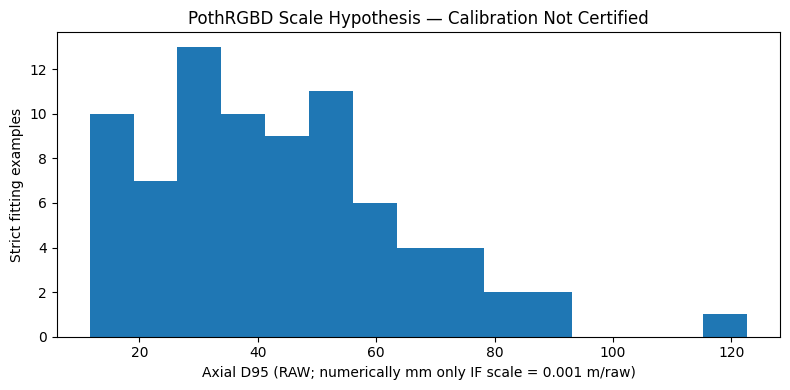


C3-16 — PHYSICAL MEASUREMENT EVIDENCE GATE COMPLETE
Strict fitting files audited: 79
Metadata candidate files: 0 (requires interpretation)
Median nominal axial D95 IF D400 default scale applies: 40.81 mm
Real RGB/mask model smoke tests: 3
Fan development point-cloud inventory: [('dataset1', 22), ('dataset3', 5)]
Source capture depth scale verified: NO
Camera intrinsics verified: NO
Road-normal physical depth validated: NO
Physical area and volume enabled: NO
Model retrained: NO

Saved:
/content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-16_physical_evidence_and_real_service_20261021T083451Z_9b8994


In [1]:
# ================================================================
# CRDL C3-16 SECTION 1
# PHYSICAL-UNIT EVIDENCE & REAL-DATA INTEGRATION TEST
#
# ONE GOOGLE COLAB CELL
# NO UPLOADS / NO TRAINING / NO ORIGINAL FILE MODIFICATION
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
import csv
import json
import hashlib
import os
import re
import uuid
import importlib.util

import numpy as np
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt


# ================================================================
# 1. RESTORE EXISTING GOOGLE DRIVE PATHS
# ================================================================

ROOT = Path("/content/drive/MyDrive")

if not ROOT.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT = (
    ROOT / "crdl_experiments"
    / "component3_fresh_v1"
)

DATA = (
    ROOT / "manushi_research_data"
    / "pothrgbd" / "PData-main"
)

PILOT = (
    PROJECT / "04_geometry_targets"
    / "C3-11_section01_RAW_target_pilot_"
      "20261021T043311Z_367db5"
)

LABEL_RUN = (
    PILOT
    / "C3-11_section04_weighted_feasibility_"
      "20261021T050356Z_383980"
)

C310 = (
    PROJECT / "07_evaluation"
    / "C3-09_physical_evidence_gate_v2_"
      "20261021T024723Z_ec15d662"
    / "C3-10_section02_grouped_pilot_protocol_"
      "20261021T042524Z_735c9f"
)

BUNDLE = (
    PROJECT / "08_integration"
    / "C3-14_provisional_component3_"
      "20261021T065928Z_c144de"
)

ROLE_FILE = (
    C310 / "PROVISIONAL_pilot_role_manifest.csv"
)

LABEL_FILE = (
    LABEL_RUN / "target_eligibility_manifest.csv"
)

SERVICE_FILE = (
    BUNDLE / "component3_service.py"
)

for p in (
    ROLE_FILE,
    LABEL_FILE,
    SERVICE_FILE,
    BUNDLE / "selected_model.pt"
):
    assert p.is_file(), f"Missing prerequisite: {p}"


# ================================================================
# 2. REPRODUCIBILITY HELPERS
# ================================================================

def readcsv(path):

    with path.open(
        newline="",
        encoding="utf-8"
    ) as f:
        return list(csv.DictReader(f))


def digest(path):

    h = hashlib.sha256()

    with path.open("rb") as f:

        for block in iter(
            lambda: f.read(1048576),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def savejson(path, obj):

    path.write_text(
        json.dumps(
            obj,
            indent=2,
            allow_nan=False,
            default=str
        ),
        encoding="utf-8"
    )


def savecsv(path, records, columns):

    with path.open(
        "w",
        newline="",
        encoding="utf-8"
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=columns
        )

        writer.writeheader()
        writer.writerows(records)


# ================================================================
# 3. RECOVER THE STRICT FITTING REFERENCES
# ================================================================

roles = {
    r["sample_id"]: r
    for r in readcsv(ROLE_FILE)
}

labels = readcsv(LABEL_FILE)

assert len(roles) == 996
assert len(labels) == 489

fit = sorted(
    (
        r for r in labels

        if r["tier"] == "STRICT"

        and roles[
            r["sample_id"]
        ]["temporal_burst_proxy"]
        == "POTHRGBD_TEMPORAL_0004"
    ),
    key=lambda r: r["sample_id"]
)

assert len(fit) == 79

assert all(
    roles[r["sample_id"]]["pilot_role"]
    == "PILOT_TRAIN"
    for r in fit
)


# ================================================================
# 4. CREATE NEW VERSIONED RESEARCH OUTPUT
# ================================================================

RUN = (
    PROJECT / "07_evaluation"
    / (
        "C3-16_physical_evidence_and_real_service_"
        + datetime.now(
            timezone.utc
        ).strftime("%Y%m%dT%H%M%SZ_")
        + uuid.uuid4().hex[:6]
    )
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)

print("=" * 70)
print("CRDL C3-16 — PHYSICAL EVIDENCE RECOVERY")
print("=" * 70)

print("Strict fitting examples:", len(fit))
print("Output:", RUN)


# ================================================================
# 5. SEARCH FOR CAPTURE-CALIBRATION METADATA
# ================================================================

# Search only metadata-like documents.
# Ignore the large image, depth and label directories.
#
# Potential values must be manually examined.
# Merely finding a number does not certify calibration.

metadata = []

allowed = {
    ".json",
    ".yaml",
    ".yml",
    ".ini",
    ".cfg",
    ".txt",
    ".md"
}

pattern = re.compile(
    r"depth[_\s-]?(?:scale|unit)"
    r"|camera[_\s-]?intrinsic"
    r"|\b(?:fx|fy|cx|cy)\b"
    r"|align(?:ed|ment)?"
    r"|calibration",
    re.I
)

for directory, dirs, filenames in os.walk(DATA):

    dirs[:] = [
        d for d in dirs

        if d.lower() not in (
            "images",
            "depths",
            "labels",
            ".git",
            "__pycache__"
        )
    ]

    for filename in filenames:

        p = Path(directory) / filename

        if (
            p.suffix.lower() not in allowed
            or p.stat().st_size > 1_000_000
        ):
            continue

        try:
            content = p.read_text(
                encoding="utf-8",
                errors="replace"
            )

        except Exception:
            continue

        hits = []

        for line in content.splitlines():

            if pattern.search(line):
                hits.append(
                    line.strip()[:240]
                )

            if len(hits) >= 12:
                break

        if (
            hits
            or p.name.lower().startswith(
                ("readme", "camera", "calib", "meta")
            )
        ):

            metadata.append({
                "relative_path":
                    str(p.relative_to(DATA)),

                "sha256":
                    digest(p),

                "candidate_lines":
                    hits
            })

        if len(metadata) >= 100:
            break

    if len(metadata) >= 100:
        break


savejson(
    RUN / "source_metadata_candidates_REVIEW.json",
    metadata
)


# ================================================================
# 6. INVENTORY FAN XYZ / POINT-CLOUD DEVELOPMENT DATA
# ================================================================

# Inspect dataset1 and dataset3 only.
# Do not access reserved Fan dataset2.

FAN_ROOT = (
    ROOT / "manushi_research_data"
    / "fan_stereo_pothole"
    / "stereo_pothole_datasets-master"
)

fan_inventory = []

for dataset_name in ("dataset1", "dataset3"):

    candidate = (
        FAN_ROOT / dataset_name / "ptcloud"
    )

    if candidate.is_dir():

        files = sorted(
            p for p in candidate.rglob("*")
            if p.is_file()
        )

    else:
        files = []

    fan_inventory.append({
        "dataset":
            dataset_name,

        "ptcloud_folder_exists":
            candidate.is_dir(),

        "file_count":
            len(files),

        "example_filenames":
            [p.name for p in files[:5]],

        "coordinate_units":
            "NOT_CERTIFIED"
    })


savejson(
    RUN / "fan_development_ptcloud_inventory.json",
    fan_inventory
)


# ================================================================
# 7. DECLARE PHYSICAL-SCALE HYPOTHESES
# ================================================================

# RealSense D400 manufacturer default:
# 0.001 metres per raw depth increment.
#
# This is NOT certified as the original
# PothRGBD capture scale.

SCALE_HYPOTHESES_M_PER_RAW = {

    "one_tenth_mm_per_raw":
        0.0001,

    "D400_MANUFACTURER_DEFAULT":
        0.001,

    "ten_mm_per_raw":
        0.01
}


# ================================================================
# 8. AUDIT ACTUAL RAW SENSOR DEPTH + TRAINING TARGETS
# ================================================================

rows = []
source_hashes = []

for i, r in enumerate(fit, 1):

    sid = r["sample_id"]
    role = roles[sid]

    depth_path = Path(
        role["depth_path"]
    )

    assert depth_path.is_file()
    assert not depth_path.is_symlink()

    assert depth_path.parent.resolve() == (
        DATA / "depths"
    ).resolve()

    relative = Path(
        r["target_relative_path"]
    )

    assert not relative.is_absolute()
    assert len(relative.parts) == 2
    assert relative.parts[0] == "targets"

    target_file = LABEL_RUN / relative

    assert target_file.is_file()

    assert digest(target_file) == (
        r["target_sha256"]
    )

    # ------------------------------------------------
    # Original depth array
    # ------------------------------------------------

    z = np.load(
        depth_path,
        allow_pickle=False
    )

    assert z.ndim == 2
    assert z.dtype == np.uint16

    valid_values = z[z > 0].astype(
        np.float64
    )

    assert len(valid_values) > 1000

    # ------------------------------------------------
    # Previously saved strict geometry target
    # ------------------------------------------------

    with np.load(
        target_file,
        allow_pickle=False
    ) as archive:

        target = np.array(
            archive["target_raw"],
            dtype=np.float64
        )

        valid_mask = np.array(
            archive["loss_mask"],
            dtype=bool
        )

    assert (
        target.shape
        == valid_mask.shape
        == (192, 256)
    )

    assert valid_mask.sum() >= 60

    values = target[valid_mask]

    assert np.isfinite(values).all()
    assert (values >= 0).all()

    d95 = float(
        np.percentile(values, 95)
    )

    camera_depth_median = float(
        np.median(valid_values)
    )

    # ------------------------------------------------
    # CONDITIONAL physical-scale interpretations
    # ------------------------------------------------

    item = {

        "sample_id":
            sid,

        "source_dtype":
            str(z.dtype),

        "source_height":
            int(z.shape[0]),

        "source_width":
            int(z.shape[1]),

        "valid_depth_fraction":
            float((z > 0).mean()),

        "source_depth_median_raw":
            camera_depth_median,

        "source_depth_p95_raw":
            float(
                np.percentile(
                    valid_values, 95
                )
            ),

        "target_d95_raw":
            d95,

        "target_mean_raw":
            float(values.mean()),

        "target_max_raw":
            float(values.max()),

        "nominal_d95_mm_if_default":
            d95,

        "nominal_camera_distance_m_if_default":
            camera_depth_median * 0.001
    }

    for name, scale in (
        SCALE_HYPOTHESES_M_PER_RAW.items()
    ):

        item[
            "axial_d95_mm_IF_" + name
        ] = d95 * scale * 1000

    rows.append(item)

    source_hashes.append({

        "sample_id":
            sid,

        "depth_sha256":
            digest(depth_path),

        "target_sha256":
            digest(target_file)
    })

    if i % 25 == 0:

        print(
            f"Audited depth/targets: {i}/{len(fit)}",
            flush=True
        )


savecsv(
    RUN / "fit_strict_nominal_scale_sensitivity.csv",
    rows,
    list(rows[0])
)

savejson(
    RUN / "source_hashes_79.json",
    source_hashes
)


# ================================================================
# 9. DECODE REAL YOLO POTHOLE POLYGONS
# ================================================================

def decode_polygons(label_path, width, height):

    canvas = Image.new(
        "L",
        (width, height),
        0
    )

    draw = ImageDraw.Draw(canvas)

    count = 0

    for line in label_path.read_text(
        encoding="utf-8"
    ).splitlines():

        values = np.fromstring(
            line,
            sep=" ",
            dtype=np.float64
        )

        if not len(values):
            continue

        assert (
            len(values) >= 7
            and (len(values) - 1) % 2 == 0
            and np.isfinite(values).all()
            and values[0] == 0
            and (values[1:] >= 0).all()
            and (values[1:] <= 1).all()
        )

        points = values[1:].reshape(
            -1, 2
        )

        vertices = [
            (
                round(x * (width - 1)),
                round(y * (height - 1))
            )
            for x, y in points
        ]

        draw.polygon(
            vertices,
            fill=1
        )

        count += 1

    return (
        np.asarray(canvas, dtype=bool),
        count
    )


# ================================================================
# 10. COLD-LOAD THE EXISTING C3-14 SERVICE
# ================================================================

spec = importlib.util.spec_from_file_location(
    "crdl_c316_service",
    SERVICE_FILE
)

service_module = importlib.util.module_from_spec(
    spec
)

spec.loader.exec_module(
    service_module
)

service = service_module.Component3Prototype(
    BUNDLE,
    device="cpu"
)

print("\nFrozen Component 3 checkpoint: LOADED")


# ================================================================
# 11. REAL RGB + MASK INTEGRATION SMOKE TEST
# ================================================================

# Use training-group examples only.
# Their masks are from existing annotation files.
#
# This tests the C3 input interface with real data,
# but is not a live teammate model handoff.

smoke = []

for r in fit[:3]:

    sid = r["sample_id"]
    role = roles[sid]

    rgb_path = Path(
        role["rgb_path"]
    )

    label_path = Path(
        role["label_path"]
    )

    assert rgb_path.parent.resolve() == (
        DATA / "images"
    ).resolve()

    assert label_path.parent.resolve() == (
        DATA / "labels"
    ).resolve()

    with Image.open(rgb_path) as im:

        rgb = np.asarray(
            im.convert("RGB"),
            dtype=np.uint8
        )

    mask, n = decode_polygons(
        label_path,
        rgb.shape[1],
        rgb.shape[0]
    )

    assert n > 0
    assert mask.any()

    prediction = service.predict(
        rgb,
        mask,
        include_map=False
    )

    assert (
        prediction["reliability_status"]
        == "REVIEW_ONLY"
    )

    assert all(
        value is None
        for value in prediction[
            "physical_measurements"
        ].values()
    )

    predicted_d95 = float(
        prediction["geometry_raw"]["d95_raw"]
    )

    assert np.isfinite(predicted_d95)
    assert predicted_d95 >= 0

    smoke.append({

        "sample_id":
            sid,

        "mask_pixels":
            int(mask.sum()),

        "predicted_d95_raw":
            predicted_d95,

        "nominal_predicted_d95_mm_if_D400_default":
            predicted_d95,

        "physical_status":
            "UNVERIFIED_SCALE_AND_GENERALIZATION"
    })


savecsv(
    RUN / "real_fit_input_service_smoke.csv",
    smoke,
    list(smoke[0])
)


# ================================================================
# 12. SAVE PHYSICAL-EVIDENCE DECISION
# ================================================================

summary = {

    "stage":
        "C3-16_PHYSICAL_UNIT_EVIDENCE",

    "data_source":
        "PothRGBD RealSense D415",

    "strict_train_only_samples":
        79,

    "nominal_default_scale_m_per_raw":
        0.001,

    "default_scale_documented_by_manufacturer":
        True,

    "original_capture_scale_verified_from_capture_config":
        False,

    "source_metadata_candidates":
        len(metadata),

    "capture_intrinsics_verified":
        False,

    "rgb_depth_alignment_verified":
        False,

    "axial_depth_mm_status":
        "CONDITIONAL_DEVICE_DEFAULT_HYPOTHESIS_ONLY",

    "road_normal_depth_mm_verified":
        False,

    "area_m2_available":
        False,

    "volume_m3_available":
        False,

    "model_metric_generalization_verified":
        False,

    "new_training":
        False,

    "protected_dev_and_cross_day_sources_read":
        False,

    "nominal_strict_target_d95_mm_median":
        float(
            np.median([
                r["nominal_d95_mm_if_default"]
                for r in rows
            ])
        ),

    "real_fit_service_smoke_passed":
        len(smoke),

    "caveat":
        "Manufacturer defaults and physically "
        "plausible values cannot certify the "
        "original capture configuration. "
        "Source geometry is axial, not "
        "road-normal. No metric claims enabled.",

    "references": [
        "https://dev.realsenseai.com/docs/"
        "projection-in-realsense-sdk-2-0/",

        "https://arxiv.org/abs/2505.04207"
    ]
}

savejson(
    RUN / "physical_evidence_gate.json",
    summary
)


# ================================================================
# 13. VISUALIZE PHYSICAL-SCALE HYPOTHESIS
# ================================================================

fig, ax = plt.subplots(
    figsize=(8, 4)
)

ax.hist(
    [
        r["target_d95_raw"]
        for r in rows
    ],
    bins=15
)

ax.set_xlabel(
    "Axial D95 (RAW; numerically mm only "
    "IF scale = 0.001 m/raw)"
)

ax.set_ylabel(
    "Strict fitting examples"
)

ax.set_title(
    "PothRGBD Scale Hypothesis — "
    "Calibration Not Certified"
)

fig.tight_layout()

fig.savefig(
    RUN / "raw_d95_scale_hypothesis.png",
    dpi=145
)

plt.show()
plt.close(fig)


# ================================================================
# 14. GENERATE ARTIFACT CHECKSUMS
# ================================================================

receipts = []

for p in sorted(RUN.iterdir()):

    if (
        p.is_file()
        and p.name != "sha256_manifest.json"
    ):

        receipts.append({

            "file":
                p.name,

            "bytes":
                p.stat().st_size,

            "sha256":
                digest(p)
        })


savejson(
    RUN / "sha256_manifest.json",
    receipts
)


# ================================================================
# 15. FINAL OUTPUT
# ================================================================

print("\n" + "=" * 70)

print(
    "C3-16 — PHYSICAL MEASUREMENT "
    "EVIDENCE GATE COMPLETE"
)

print("=" * 70)

print(
    "Strict fitting files audited:",
    len(rows)
)

print(
    "Metadata candidate files:",
    len(metadata),
    "(requires interpretation)"
)

print(
    "Median nominal axial D95 "
    "IF D400 default scale applies:",
    round(
        summary[
            "nominal_strict_target_d95_mm_median"
        ],
        2
    ),
    "mm"
)

print(
    "Real RGB/mask model smoke tests:",
    len(smoke)
)

print(
    "Fan development point-cloud inventory:",
    [
        (
            r["dataset"],
            r["file_count"]
        )
        for r in fan_inventory
    ]
)

print("Source capture depth scale verified: NO")

print("Camera intrinsics verified: NO")

print("Road-normal physical depth validated: NO")

print("Physical area and volume enabled: NO")

print("Model retrained: NO")

print("\nSaved:")
print(RUN)

print("=" * 70)